# Trying things out

In [171]:
import numpy as np
import networkx as nx
import matplotlib as mpl
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull
import importlib
import cProfile
import itertools
import timeit
import json
import ctmc
import utils
import plot
import os

importlib.reload(plot)

<module 'plot' from '/home/tohme/.julia/dev/LLROpt/plot.py'>

## Understanding iterators

In [53]:
a = [np.array([0,1]), np.array([[1,1],[3,6]])]
it = itertools.accumulate(a, ctmc.matmul_r)
b = np.array(list(it))
np.sum(b, axis=1)

array([1., 9.])

In [70]:
setup = """
import numpy as np
import ctmc
import itertools
a = [np.array([0,1])] + [np.array([[1,2],[3,4]])]*100000
it = itertools.accumulate(a, ctmc.matmul_r)
"""

stmt = """
np.log(np.sum(np.array(list(it)), axis=1))
"""

timeit.timeit(stmt, setup, number=1)

0.3747418439888861

In [71]:
stmt2 = """
np.array([np.log(np.sum(i)) for i in it])
"""

timeit.timeit(stmt2, setup, number=1)

0.5998997629940277

## Profiling

### ctmc.ir_full()

In [4]:
import pstats
from pstats import SortKey

nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1,1,1,1,1,1,1,1])
rates = 10.0 ** logrates

cProfile.run('ctmc.ir_full(rates, *args)', 'irstats')

In [33]:
p = pstats.Stats('irstats')
p.sort_stats(SortKey.CUMULATIVE).print_stats()

Mon Apr 22 16:31:15 2024    irstats

         4999667 function calls in 8.737 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    8.737    8.737 {built-in method builtins.exec}
        1    0.002    0.002    8.737    8.737 <string>:1(<module>)
        1    0.016    0.016    8.735    8.735 /home/tohme/phd/flython/ctmc.py:369(ir_full)
        1    4.267    4.267    4.267    4.267 /home/tohme/phd/flython/ctmc.py:126(generate)
        2    0.107    0.054    2.713    1.357 /home/tohme/phd/flython/ctmc.py:329(ll_full)
   499874    0.901    0.000    2.202    0.000 /home/tohme/phd/flython/ctmc.py:401(matmul_r)
        1    1.671    1.671    1.695    1.695 /home/tohme/phd/flython/utils.py:74(get_residence_times)
   499889    0.315    0.000    1.267    0.000 /home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/numpy/core/fromnumeric.py:2177(sum)
   499898    0.340    0.000    0.919    0.000 /h

In [32]:
p.print_callers(.99)

   Ordered by: internal time
   List reduced from 115 to 114 due to restriction <0.99>

Function                                                                                                              was called by...
                                                                                                                          ncalls  tottime  cumtime
/home/tohme/phd/flython/ctmc.py:126(generate)                                                                         <-       1    4.267    4.267  /home/tohme/phd/flython/ctmc.py:369(ir_full)
/home/tohme/phd/flython/utils.py:74(get_residence_times)                                                              <-       1    1.671    1.695  /home/tohme/phd/flython/ctmc.py:369(ir_full)
/home/tohme/phd/flython/ctmc.py:401(matmul_r)                                                                         <-  499874    0.901    2.202  /home/tohme/phd/flython/ctmc.py:329(ll_full)
{method 'reduce' of 'numpy.ufunc' objects}         

In [ ]:
np.ones((500000, 4, 4))

### ctmc.Generator.generate()

In [19]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
args = (c, dc, on_ind, idist, n, nb, na)

exp_name = 'outcmaes-diff-limited-log-search-space-general-4s-ir-acc-20240408'
logrates = utils.cmaes_output_to_arr('exps/data/'+exp_name+'/xrecentbest.dat')[-3, 5:13]

rates = 10.0 ** logrates
on = np.where(on_ind)[0]

Q = utils.build_mat(rates, c, nb, na)
C = ctmc.Generator(Q, n, initial_dist=idist)

In [20]:
cProfile.run('C.generate()', sort=0)

         5 function calls in 4.254 seconds

   Ordered by: call count

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    4.254    4.254 {built-in method builtins.exec}
        1    4.254    4.254    4.254    4.254 ctmc.py:126(generate)
        1    0.000    0.000    4.254    4.254 <string>:1(<module>)
        1    0.000    0.000    0.000    0.000 {built-in method numpy.arange}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




### utils.get_residence_times()

In [75]:
cProfile.run('utils.get_residence_times(C.r[:,0], C.t[:,0], on)', sort=2)

         500004 function calls in 1.724 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    1.724    1.724 {built-in method builtins.exec}
        1    0.002    0.002    1.724    1.724 <string>:1(<module>)
        1    1.698    1.698    1.722    1.722 utils.py:74(get_residence_times)
   500000    0.024    0.000    0.024    0.000 {method 'keys' of 'dict' objects}
        1    0.000    0.000    0.000    0.000 {method 'disable' of '_lsprof.Profiler' objects}




In [73]:
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))
t_onoff = np.stack((t_on, t_off), axis=1)
t_onoff = np.cumsum(np.concatenate(t_onoff))
t = np.sum(t_on + t_off)

args_ll = (on_ind, t_on, t_off, idist, nb, na)

### ctmc.ll_full()

In [74]:
cProfile.run('ctmc.ll_full(rates, c, *args_ll)', sort=2)

         2223097 function calls in 1.349 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    1.349    1.349 {built-in method builtins.exec}
        1    0.007    0.007    1.349    1.349 <string>:1(<module>)
        1    0.055    0.055    1.342    1.342 ctmc.py:329(ll_full)
   246978    0.443    0.000    1.072    0.000 ctmc.py:372(matmul_r)
   246983    0.149    0.000    0.611    0.000 fromnumeric.py:2177(sum)
   246985    0.160    0.000    0.446    0.000 fromnumeric.py:71(_wrapreduction)
   246991    0.195    0.000    0.195    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        2    0.032    0.016    0.123    0.061 ctmc.py:189(fpt)
        2    0.085    0.043    0.091    0.045 ctmc.py:151(P)
   246985    0.077    0.000    0.077    0.000 fromnumeric.py:72(<dictcomp>)
        1    0.049    0.049    0.057    0.057 utils.py:103(alternate)
        1    0.033    0.033    0.033    0.033 {built-in 

### ctmc.ll_full_fast()

In [61]:
args_ll = (on_ind, t_on, t_off, v_on, nb, na)

cProfile.run('ctmc.ll_full_fast(rates, c, *args_ll)', sort=2)

         292 function calls in 0.404 seconds

   Ordered by: cumulative time

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
        1    0.000    0.000    0.404    0.404 {built-in method builtins.exec}
        1    0.000    0.000    0.404    0.404 <string>:1(<module>)
        1    0.176    0.176    0.403    0.403 ctmc.py:430(ll_full_fast)
        2    0.060    0.030    0.220    0.110 ctmc.py:201(fpt)
        2    0.154    0.077    0.160    0.080 ctmc.py:163(P)
        2    0.004    0.002    0.004    0.002 {method 'flatten' of 'numpy.ndarray' objects}
        5    0.004    0.001    0.004    0.001 {built-in method numpy.zeros}
       13    0.003    0.000    0.003    0.000 {method 'reduce' of 'numpy.ufunc' objects}
        7    0.000    0.000    0.003    0.000 fromnumeric.py:71(_wrapreduction)
        5    0.000    0.000    0.003    0.001 fromnumeric.py:2177(sum)
        2    0.002    0.001    0.002    0.001 numeric.py:932(tensordot)
        2    0.000    0.000  

### ctmc.ir_full_fast()

In [2]:
import pstats
from pstats import SortKey

nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0, 1, 0, 1])
idist = np.array([0.25] * 4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1, 1, 1, 1, 1, 1, 1, 1])
rates = 10.0 ** logrates

cProfile.run('ctmc.ir_full_fast(rates, *args)', 'irstats')
p = pstats.Stats('irstats')
p.sort_stats(SortKey.CUMULATIVE).print_stats()


: 

## Vectorizing get_residence_times

In [76]:
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)

In [22]:
on = np.array([1,3])
on_ = np.outer(on, np.ones(n))

In [23]:
a = np.array([0,1,3,1,2,3,2,4])
b = a / 10
hset = np.array([1,3])
hset_ = np.outer(hset, np.ones(len(a)))

hset_

array([[1., 1., 1., 1., 1., 1., 1., 1.],
       [3., 3., 3., 3., 3., 3., 3., 3.]])

In [25]:
c = np.where(a == hset_, b, 0)
d = np.sum(c, axis=0)
d

array([0. , 0.1, 0.3, 0.1, 0. , 0.3, 0. , 0. ])

In [26]:
c

array([[0. , 0.1, 0. , 0.1, 0. , 0. , 0. , 0. ],
       [0. , 0. , 0.3, 0. , 0. , 0.3, 0. , 0. ]])

In [129]:
d * np.roll(d, 1) > 0

array([False, False,  True,  True, False, False, False, False])

# Interfacing with C

## ctmc.matmul_r() C interface

In [2]:
from ctypes import *
import sys
import os

lib_path = os.path.join(sys.path[0], 'cpython/matmul_%s.so' % (sys.platform))
try:
    matmul_lib = cdll.LoadLibrary(lib_path)
except:
    print('OS %s not recognized' % (sys.platform))

ctypes_matmul_r = matmul_lib.matmul_r
ctypes_accumulate = matmul_lib.accumulate
ctypes_matmul_r.restype = None
ctypes_accumulate.restype = None

In [47]:
# Python

seed = 42
rng = np.random.default_rng(seed)

# rate bounds
log_lb = -5
difflimit = 0.124
log_ub = 5
log_dl = np.log10(difflimit)

#                       k_0^0   k_0^1   k_1^0   k_1^1   k_2^0   k_2^1   k_3^0   k_3^1
log_lbounds = np.array([log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb])
log_ubounds = np.array([log_dl, log_ub, log_dl, log_ub, log_ub, log_ub, log_ub, log_ub])

# set up parameters
nb, na = 1, 1
nstates = 2 ** (nb + na)
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)
on = np.where(on_ind)[0]
off = np.arange(nstates)[~on]

# sample rates
logrates = rng.uniform(log_lbounds, log_ubounds)
rates = 10.0 ** logrates

# build rate matrix and simulate
Q = utils.build_mat(rates, c, nb, na)
C = ctmc.Generator(Q, n, initial_dist=idist)
C.generate()

# residence times in on and off partitions
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))

# only keep nonzero residence times
start_in_on = t_on[0] > 0
t_on = t_on[(t_on > 0)]
t_off = t_off[(t_off > 0)]

# make res time arrays of equal length
minlen = min(len(t_on), len(t_off))
t_on = t_on[:minlen]
t_off = t_off[:minlen]
njumps = minlen

# first-passage time probability densities
R = ctmc.fpt(Q, off, t_on)
S = ctmc.fpt(Q, on, t_off)

R_ = R[..., on, :][..., off]
S_ = S[..., off, :][..., on]

# concatenate into an alternating on-off sequence of matrices
if start_in_on:
    D = utils.alternate(R_, S_)
else:
    D = utils.alternate(S_, R_)

# prepend the initial distribution conditioned on start state
p_on = idist @ on_ind
p_off = idist @ (np.ones(nstates) - on_ind)
D.appendleft(idist[on] / p_on if start_in_on else idist[off] / p_off)

# reduce the sequence to a single vector, rescaling along the way
it = np.array(list(itertools.accumulate(D, ctmc.matmul_r)))

llr_vec_python = np.array(it)
llr_traj_python = np.log(np.sum(it, axis=1))

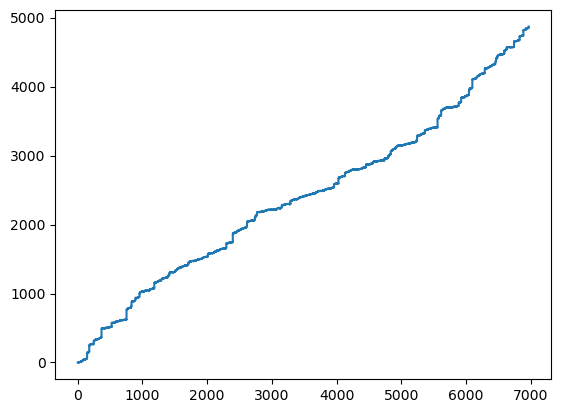

In [4]:
time = np.stack((t_on, t_off), axis=1)
time = np.concatenate(time)
w = 4000
plt.plot(np.cumsum(time)[:w], np.cumsum(llr_traj_python)[:w])

### Toy example

In [25]:
n = 2
m = 2
N_R = 2
N_S = 2
N = N_R + N_S


v = np.array([0,1])
Rlist = np.array([1,0,0,1,0,1,1,0])
Slist = np.array([1,1,2,2,1,1,2,2])

c_m = c_int(m)
c_n = c_int(n)
c_N = c_int(N)
c_v = (c_double * m)(*v)
c_Rlist = (c_double * (m*n*N_R))(*Rlist)
c_Slist = (c_double * (m*n*N_S))(*Slist)
c_vlist = (c_double * (m*N))()

c_M = (c_double * (m*n))(*np.array([0,1,2,3]))
c_w = (c_double * (m))()

In [17]:
ctypes_matmul_r(c_m, c_n, c_v, c_M, c_w)
np.array(c_w)

array([2., 3.])

In [18]:
# C

ctypes_accumulate(c_m, c_n, c_N, c_v, c_Rlist, c_Slist, c_vlist)

In [19]:
c_vlist[:]

[0.0, 1.0, 2.0, 2.0, 0.5, 0.5, 1.5, 1.5]

### Real trajectory

In [57]:
m = len(on)
n = len(off)
N_R = R_.shape[0]
N_S = S_.shape[0]
N = N_R + N_S
v_on = idist[on] / p_on
v_off = idist[off] / p_off

Rlist = R_.flatten()
Slist = S_.flatten()

c_m = c_int(m)
c_n = c_int(n)
c_N = c_int(N)
c_von = (c_double * m)(*v_on)
c_voff = (c_double * n)(*v_off)
c_Rlist = (c_double * (m*n*N_R))(*Rlist)
c_Slist = (c_double * (m*n*N_S))(*Slist)
c_vlist = (c_double * (m*N))()

In [17]:
if start_in_on:
    ctypes_accumulate(c_m, c_n, c_N, c_von, c_Rlist, c_Slist, c_vlist)
else:
    ctypes_accumulate(c_n, c_m, c_N, c_voff, c_Slist, c_Rlist, c_vlist)

In [18]:
a, b = llr_vec_python[1:].flatten(), c_vlist[:]

np.allclose(a, b)

True

### Comparing both implementations in the ctmc file

In [58]:
import time

start = time.time()
ll_traj_python = ctmc.ll_full(rates, c, on_ind, t_on, t_off, v_on, nb, na)
mid = time.time()
ll_traj_c = ctmc.ll_full_fast(rates, c, on_ind, t_on, t_off, v_on, nb, na)
end = time.time()

In [59]:
np.allclose(ll_traj_python[1:], ll_traj_c)

True

In [60]:
print("python: ", mid-start)
print("C: ", end - mid)

python:  1.869136095046997
C:  0.40924930572509766


## ctmc.Generator.generate() C interface

In [2]:
from ctypes import *
import sys
import os

lib_path = os.path.join(sys.path[0], 'cpython/generate_%s.so' % (sys.platform))
try:
    generate_lib = cdll.LoadLibrary(lib_path)
except:
    print('OS %s not recognized' % (sys.platform))

ctypes_generate = generate_lib.generate
ctypes_generate.restype = None

# from ctypes import *
# import sys
# import os

# lib_path = os.path.join(sys.path[0], 'cpython/gillespie_C_%s.so' % (sys.platform))
# try:
#     gillespie_lib = cdll.LoadLibrary(lib_path)
# except:
#     print('OS %s not recognized' % (sys.platform))

# python_gillespie = gillespie_lib.gillespie
# python_gillespie.restype = None

In [4]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0,1,0,1])
idist = np.array([0.25]*4)

seed = 45
rng = np.random.default_rng(seed)

# rate bounds
log_lb = -1
difflimit = 0.124
log_ub = 1
log_dl = np.log10(difflimit)

#                       k_0^0   k_0^1   k_1^0   k_1^1   k_2^0   k_2^1   k_3^0   k_3^1
log_lbounds = np.array([log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb, log_lb])
log_ubounds = np.array([log_dl, log_ub, log_dl, log_ub, log_ub, log_ub, log_ub, log_ub])

# sample rates
logrates = rng.uniform(log_lbounds, log_ubounds)
rates = 10.0 ** logrates
Q = utils.build_mat(rates, c, nb, na)

states, hold_times, t_on, t_off = ctmc.generate(rates, c, n, idist, on_ind, nb, na)

: 

In [3]:
nb, na = 1, 1
c = 1
dc = 0.1
n = 500000
on_ind = np.array([0, 1, 0, 1])
idist = np.array([0.25] * 4)
args = (c, dc, on_ind, idist, n, nb, na)

logrates = np.array([1, 1, 1, 1, 1, 1, 1, 1])
rates = 10.0 ** logrates

ns=2 ** (nb + na)
Q=utils.build_mat(rates, c, nb, na).T
K=-np.diag(Q)
k=Q+np.diag(K)
C=np.cumsum(k,0)/K
flattenC=np.transpose(C).flatten()
s0=np.random.default_rng().choice(np.arange(ns), p=idist)

# initialize the ctypes variables
c_K = (c_double * ns)(*K)
c_C = (c_double * (ns**2))(*flattenC)
c_deltat = (c_double * n)()
c_ton = (c_double * n)()
c_toff = (c_double * n)()
c_s = (c_int *n)()
c_on_ind = (c_int *ns)(*on_ind)

# simulate
ctypes_generate(
    c_int(ns), 
    c_int(s0), 
    c_int(n), 
    c_K,
    c_C, 
    c_on_ind,
    c_s, 
    c_deltat,
    c_ton,
    c_toff
)

In [4]:
import scipy

# some tests
assert len(t_on) == len(t_off)

Q = utils.build_mat(rates, c, nb, na)
Q = Q.T
Q_nodiag = Q - np.diag(np.diag(Q))
diagQ = np.diag(Q)
K=-np.diag(Q)
k=Q+np.diag(K)
values, counts = np.unique(states, return_counts=True)

u, s, vh = scipy.linalg.svd((k-np.diag(K))/K)
print(vh[-1,:]/sum(vh[-1,:]))
print(ctmc.P_ss(Q.T))
print(counts / n)

NameError: name 't_on' is not defined

In [51]:
values

array([-1,  0,  1,  2,  3], dtype=int32)

In [36]:
counts

array([     7,      7, 249993, 249993])

# Fully-connected network

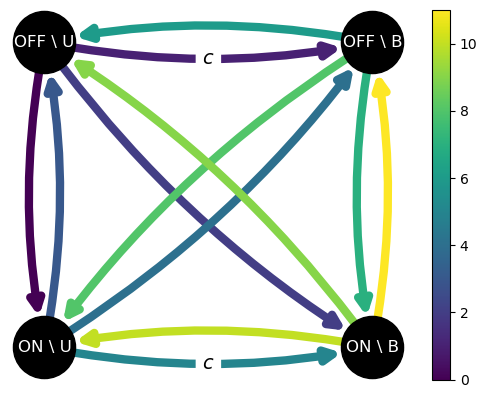

array([[-12.,   0.,  10.,   2.],
       [  3., -57.,   4.,  50.],
       [  6.,   8., -21.,   7.],
       [  9.,  10.,  11., -30.]])

In [4]:
import networkx as nx
importlib.reload(plot)

G = nx.DiGraph()
G.add_nodes_from(range(4))
edges = np.array([(0,1),(0,2),(0,3),
                  (1,0),(1,2),(1,3),
                  (2,0),(2,3),(2,1),
                  (3,0),(3,1),(3,2)])
input_edges = [(0,2), (1,3)]
weights = np.arange(12)[:, None]
base_rates = np.concatenate((edges, weights), axis=1)

plot.draw_circuit(base_rates, input_edges)
utils.build_mat(base_rates, input_edges, 10)

# Tinkering

In [2]:
import numpy as np
import copy

def fpt(Q, hset, t):
    """
    Matrix of PDFs of the first-passage time to hit any state in hset
    """
    nstates = len(Q)
    Q_h = copy.deepcopy(Q)
    Q_h[hset] = np.zeros(nstates)  # rows of hitting set are zeroed

    print(Q_h, '\n')

    print(ctmc.P(Q_h, t))

    return Q_h @ ctmc.P(Q_h, t)

Q = np.array([-1.0, 0.6, 0.4, 
              0.0, -1.5, 1.5, 
              1.0, 1.0, -2.0])

Q = Q.reshape((3, 3))
hset = np.array([0])

t = 1

fpt(Q, hset, t)

[[ 0.   0.   0. ]
 [ 0.  -1.5  1.5]
 [ 1.   1.  -2. ]] 

[[1.         0.         0.        ]
 [0.28212062 0.38383322 0.33404615]
 [0.50481806 0.22269744 0.2724845 ]]


array([[ 0.        ,  0.        ,  0.        ],
       [ 0.33404615, -0.24170368, -0.09234247],
       [ 0.2724845 , -0.06156165, -0.21092286]])

# Getting rid of alternate()

In [61]:
edges = np.array([(0,1), (1,0), (1,2), (2,1)])
input_edges = [(1,0), (1,2)]
on_ind = np.array([1,0,1])
c = 1
dc = 0.1
n = 5
idist = np.ones(3) / 3

logrates = np.random.default_rng().uniform(low=0, high=1, size=4)
rates = 10.0 ** logrates
rates = rates[:, np.newaxis]
weighted_edges = np.concatenate((edges, rates), axis=1)

nstates = len(on_ind)
off_ind = np.ones(nstates) - on_ind
on = np.where(on_ind)[0]
off = np.where(off_ind)[0]

# building the rate matrix and simulating 
Q = utils.build_mat(weighted_edges, input_edges, c)
C = ctmc.Generator(Q, n, initial_dist=idist)
C.generate()

# residence times in on and off partitions
res_times = utils.get_residence_times(C.r[:,0], C.t[:,0], on)
t_on = np.array(list(res_times['on'].values()))
t_off = np.array(list(res_times['off'].values()))

# only keep nonzero residence times
start_in_on = t_on[0] > 0
t_on = t_on[(t_on > 0)]
t_off = t_off[(t_off > 0)]

# make res time arrays of equal length
minlen = min(len(t_on), len(t_off))
t_on = t_on[:minlen]
t_off = t_off[:minlen]

# total duration of trajectory
t = np.sum(t_on + t_off)

# conditional initial distributions
idist_on = idist[on] / (idist @ on_ind)
idist_off = idist[off] / (idist @ off_ind)

if start_in_on:
    args_ll = (on_ind, t_on, t_off, idist_on)
    ind_set = on_ind
    t_set, t_comp = t_on, t_off
    idist_set = idist_on
else:
    args_ll = (off_ind, t_off, t_on, idist_off)
    ind_set = off_ind
    t_set, t_comp = t_off, t_on
    idist_set = idist_off

assert len(t_set) == len(t_comp)

ind_comp = np.ones_like(ind_set) - ind_set
_set = np.where(ind_set)[0]
_comp = np.where(ind_comp)[0]

# matrices of first-passage time PDFs
R = ctmc.fpt(Q, _comp, t_set)
S = ctmc.fpt(Q, _set, t_comp)

# zero-out slices of R except from on->off and from S except from off->on
R[..., _comp, :] = 0
R[..., _set] = 0
S[..., _set, :] = 0
S[..., _comp] = 0

# concatenate into an alternating on-off sequence of matrices
D = utils.alternate(R_, S_)

# prepend the initial distribution conditioned on start state
D.appendleft(idist_set)

# reduce the sequence to a single vector, rescaling along the way
it = np.array(list(itertools.accumulate(D, ctmc.matmul_r)))

ll = np.log(np.sum(it, axis=1))



(2,) (2, 1)
(1,) (1, 2)
(2,) (2, 1)
(1,) (1, 2)


ValueError: setting an array element with a sequence. The requested array has an inhomogeneous shape after 1 dimensions. The detected shape was (5,) + inhomogeneous part.

In [52]:
on_bool = np.array([1,0,1], dtype='bool')
off_bool = np.logical_not(on_bool)

In [76]:
import copy

S1 = copy.deepcopy(S)
R1 = copy.deepcopy(R)


In [77]:
R1[..., _comp, :] = 0
R1[..., _set] = 0
S1[..., _set, :] = 0
S1[..., _comp] = 0

In [81]:
R1

array([[[0.        , 0.64876013, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 1.07623634, 0.        ]],

       [[0.        , 0.46003018, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.90248879, 0.        ]]])

In [82]:
S1

array([[[0.        , 0.        , 0.        ],
        [2.05080202, 0.        , 4.99507377],
        [0.        , 0.        , 0.        ]],

       [[0.        , 0.        , 0.        ],
        [1.36374185, 0.        , 3.32162301],
        [0.        , 0.        , 0.        ]]])

In [104]:
idist = np.ones(3) / 3
idist[_comp] = 0
idist = idist / np.sum(idist)
# np.outer(idist, np.ones(3))
A = np.zeros_like(Q)
A[_set] = idist
A

array([[0.5, 0. , 0.5],
       [0. , 0. , 0. ],
       [0.5, 0. , 0.5]])

In [115]:


D = np.stack((R1, S1), axis=1)
D = np.concatenate(D)
list(itertools.accumulate(D, ctmc.matmul_r))

[array([[0.        , 0.64876013, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 1.07623634, 0.        ]]),
 array([[0.77129351, 0.        , 1.87861527],
        [0.        , 0.        , 0.        ],
        [1.27950851, 0.        , 3.1164585 ]]),
 array([[0.        , 0.29098547, 0.        ],
        [0.        , 0.        , 0.        ],
        [0.        , 0.48271946, 0.        ]]),
 array([[0.51289458, 0.        , 1.24924115],
        [0.        , 0.        , 0.        ],
        [0.85084727, 0.        , 2.07238186]])]

# Gradient descent
 Intuition: if the cost function g(x) initially grows faster than f(x) along the optimal boundary, then grows slower after some point, then the boundary will be non-concave

In [2]:
import numdifftools as nd

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
c = 5.6         # um^-3
dc = 0.1 * c
dl_tf = 4*a*D_tf
ub = 5*7.4/11
max_ir_full = 0.5 * (dc/c)**2 * (1/(c*4*a*D_tf + 1/ub)) ** (-1)

log_ub = np.log10(ub)
log_dl_tf = np.log10(dl_tf)
log_lb = -5 + np.log10(7.4/11)

log_lbounds = np.ones(8) * log_lb
log_ubounds = np.ones(8) * log_ub

# diff-limited upper bounds
log_ubounds[0] = log_dl_tf
log_ubounds[2] = log_dl_tf

# lower bounds
log_lbounds[0] = min(log_lb, log_dl_tf - 1)
log_lbounds[2] = min(log_lb, log_dl_tf - 1)

lbounds = 10.0 ** log_lbounds
ubounds = 10.0 ** log_ubounds
bounds = [log_lbounds, log_ubounds]

########### Circuit
edges = np.array([(0,2), (0,1), (1,3), (1,0), (2,0), (2,3), (3,1), (3,2)])#, (0,3), (3,0)])
input_edges = [(0,2), (1,3)]#, (0,3)]

########### CMA parameters
maxfevals = 10000
sigma0 = (log_ub) / 4
x0 = (log_ubounds + log_lbounds) / 2
# x0 = np.array([-1.05,-4,-1.05,0.69,-4,0.69,0.69,-4])    # true optimum
weighted_eges = np.concatenate((edges, x0[:, np.newaxis]), axis=1)

on_ind = np.array([0,1,0,1])
betas = np.logspace(-8, -3, 30)

In [45]:
setup = """
import importlib
import numpy as np
import ctmc
importlib.reload(ctmc)
import timeit

Q = np.array([[-2, 2], [2, -2]])
weighted_edges = np.array([(0,1,2), (1,0,2)])
input_edges = np.array([(0,1)])
c = 1.0000000001
on_ind = np.array([0,1])
t_set = np.array([1,2,3])
t_comp = np.array([2,3,4])
ind_set = np.array([0,1])
idist_set = np.array([0.5])
"""

timeit.timeit("ctmc.ll_full(weighted_edges, input_edges, c, ind_set, t_set, t_comp, idist_set)", setup=setup, number=10000)

1.5585023909807205

In [2]:
import importlib
import numpy as np
import ctmc
importlib.reload(ctmc)
import timeit
import matplotlib.pyplot as plt

weighted_edges = np.array([(0,1,0.5), (1,0,2)])
input_edges = [(0,1)]
c = 1
dc = 0.1
on_ind = np.array([0,1])
idist = np.ones(2) / 2
n = 1000

N = 1000
acc = 0
for i in range(N):
    t_on, t_off, llr = ctmc.ir_full(weighted_edges, input_edges, c, dc, on_ind, idist, n)
    acc += llr[-1] / np.sum((t_on, t_off))

acc / N

# fig, ax = plt.subplots(1,1)

# ax.hist(times, density=True)
# ax.plot()

# times = np.zeros(3)

# for i in range(n):
#     si = G.r[i, 0]
#     times[si] += G.t[i, 0]

# times /= np.sum(G.t)
# times

0.0018624739325114993

In [98]:
llr.shape

(5001,)

In [2]:
llr

array([0.        , 0.0651039 , 0.0651039 , ..., 3.67476954, 3.61412779,
       3.61412779])

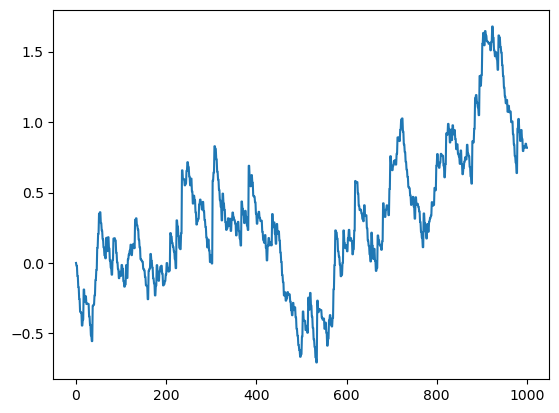

In [7]:
plt.plot(llr)

# Problem with pareto fronts

In [6]:
# try to isolate the problem(s)
# 1. optima should be the same under rescaling of the parameter bounds
# 2. beta should be the slope of the curve

# function to minimize
def f(x):
    return -x[0]**2 - x[1]**2

# constraint
def g(x, c):
    return x[1] - c*x[0]

def L(x, c, beta):
    return f(x) + beta*g(x, c)

# bounds
lb = [0, 0]
ub = [5, 5]
bounds = [lb, ub]

# lagrange multiplier
betas = np.linspace(0, 10, 20)
c = 1

# cma settings
x0 = [1,1]
sigma0 = 0.25
maxfevals = 5000
output = []

for key, beta in enumerate(betas):

    args = (c, beta)

    opts = {'maxfevals': maxfevals,
            'bounds': bounds,
            'verb_append': 0}

    xopt, es = cma.fmin2(L, x0, sigma0, options=opts, args=args)
    output.append(es)

(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=346627, Wed Jul 17 16:27:56 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 -3.369458931239090e+00 1.0e+00 2.87e-01  3e-01  3e-01 0:00.0
    2     12 -3.789485792000014e+00 1.3e+00 3.11e-01  3e-01  3e-01 0:00.0
    3     18 -4.441100587172597e+00 1.4e+00 3.08e-01  3e-01  3e-01 0:00.0
   79    474 -5.000000000000000e+01 1.3e+00 3.87e-05  3e-08  3e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 16:27:56 2024)
final/bestever f-value = -5.000000e+01 -5.000000e+01 after 475/436 evaluations
incumbent solution: [5.0, 5.0]
std deviation: [2.8691644079836216e-08, 2.6366114758051917e-08]
(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=404291, Wed Jul 17 16:27:56 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 -2.760281284998398e+00 1.0e+00 2.53e-01  3e-01  3e-01 0:00.0
    2     12 -4.061943276321189e+00 1.1e+00 3.52e-01  3e-01  5e-01 0:00.0
   

/home/tohme/phd/flython/cma/utilities/utils.py:343: UserWarning: sigma change np.exp(1.0184914363684265) = 2.7690143771826414 clipped to np.exp(+-1) (class=CMAAdaptSigmaCSA method=update iteration=2)
  warnings.warn(msg + ' (' +


   87    522 -7.500000000000000e+01 1.6e+00 1.62e-05  7e-09  7e-09 0:00.0
termination on tolflatfitness=1 (Wed Jul 17 16:27:58 2024)
final/bestever f-value = -7.500000e+01 -7.500000e+01 after 523/469 evaluations
incumbent solution: [5.0, 5.993424004088332e-16]
std deviation: [6.6629557971131726e-09, 6.946163001706939e-09]


In [10]:
es = output[-1]
res = es.result
res[0]

array([5.00000000e+00, 1.75551817e-16])

In [48]:
def constraint(x, mx, my, const):
    return x[0]*mx + x[1]*my - const

def detfun(x, cx, cy, mx, my, const, beta=0):
    return (x[0] - cx)**2 + (x[1] - cy)**2 + beta * np.abs(constraint(x, mx, my, const))

def stochfun(x, a, b, l):
    rng = np.random.default_rng()
    x += rng.normal(0,l, x.shape)
    return (x[0] - a)**2 + (x[1] - b)**2 

(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=339777, Wed Jul 17 17:01:21 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 1.872592983042352e-01 1.0e+00 2.81e-01  2e-01  3e-01 0:00.0
    2     12 3.279515646502942e-02 1.3e+00 3.20e-01  3e-01  3e-01 0:00.0
    3     18 3.950734510349879e-02 1.7e+00 3.22e-01  3e-01  3e-01 0:00.0
   63    378 2.304942742306854e-14 1.3e+00 2.21e-05  7e-08  8e-08 0:00.0
termination on tolfun=1e-11 (Wed Jul 17 17:01:21 2024)
final/bestever f-value = 2.696152e-14 4.340364e-16 after 379/323 evaluations
incumbent solution: [0.4999998650549818, 0.500000093548711]
std deviation: [6.571230258158016e-08, 7.675954636730959e-08]
(3_w,6)-aCMA-ES (mu_w=2.0,w_1=63%) in dimension 2 (seed=323719, Wed Jul 17 17:01:21 2024)
Iterat #Fevals   function value  axis ratio  sigma  min&max std  t[m:s]
    1      6 3.441907222225167e-01 1.0e+00 3.99e-01  4e-01  5e-01 0:00.0
    2     12 3.149736856082032e-01 1.5e+00 3.72e-01  4e-0

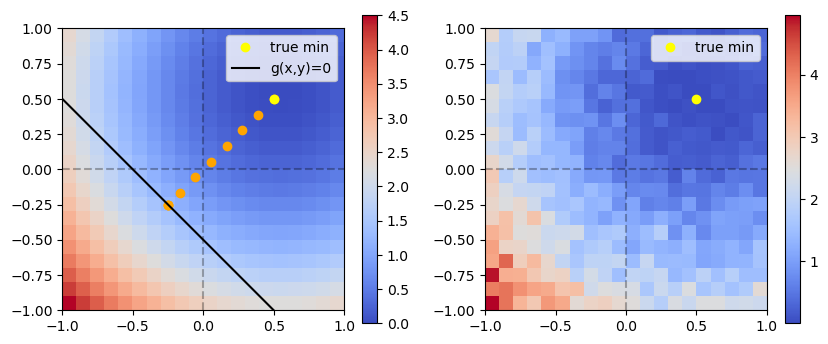

In [58]:
import matplotlib.cm as cm

# parameters
dx = 0.1     # spatial resolution
ub = 1       # upper bound
lb = -1      # lower bound
cx = 0.5     # x-coordinate of center
cy = 0.5   # y-coordintate of center
mx = 1
my = 1
const = -0.5
noise = 0.1  # noise level

x = np.arange(lb, ub, dx)
y = np.arange(lb, ub, dx)
X, Y = np.meshgrid(x, y)
detZ = detfun(np.array([X, Y]), cx, cy, mx, my, const)
stochZ = stochfun(np.array([X, Y]), cx, cy, noise)

# CMA-ES parameters
bounds = np.array([[lb, lb], [ub, ub]])
x0 = np.zeros(2)
sigma0 = 0.3
opts = {'maxfevals': 1000,
        'verb_filenameprefix':'exps/data/outcmaes-test/'}
betas = np.linspace(0, 2, 10)
solutions = []

fig, ax = plt.subplots(1, 2, figsize=(10, 4))

for key, beta in enumerate(betas):
    xopt, es = cma.fmin2(detfun, x0, sigma0, args=(cx, cy, mx, my, const, beta), options=opts)
    ax[0].plot(xopt[0], xopt[1], 'o', color='orange')
    solutions.append(es)

im0 = ax[0].imshow(detZ, interpolation='none', origin='lower', cmap=cm.coolwarm, extent=(lb, ub, lb, ub))
im1 = ax[1].imshow(stochZ, interpolation='none', origin='lower', cmap=cm.coolwarm, extent=(lb, ub, lb, ub))
ax[0].plot(cx, cy, 'o', color='yellow', label='true min')
ax[0].plot(x, (const - x*mx) / my, color='black', label='g(x,y)=0')
ax[1].plot(cx, cy, 'o', color='yellow', label='true min')
ax[0].axhline(y = 0, linestyle='dashed', color='black', alpha=0.3)
ax[1].axhline(y = 0, linestyle='dashed', color='black', alpha=0.3)
ax[0].axvline(x = 0, linestyle='dashed', color='black', alpha=0.3)
ax[1].axvline(x = 0, linestyle='dashed', color='black', alpha=0.3)
ax[0].set_xlim(-1,1)
ax[0].set_ylim(-1,1)

_ = fig.colorbar(im0, orientation='vertical', shrink=1)
_ = fig.colorbar(im1, orientation='vertical', shrink=1)
ax[0].legend()
ax[1].legend()

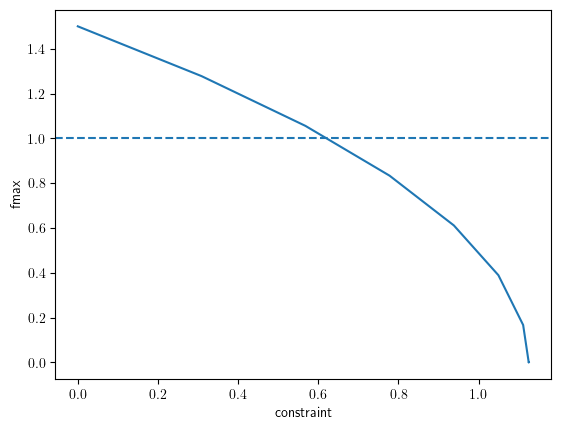

In [64]:
fig, ax = plt.subplots(1,1)

fopts = []
constr = []
fmax = 1

for key, beta in enumerate(betas):
    es = solutions[key]
    res = es.result
    fopts.append(res[1])
    constr.append(constraint(res[0], mx, my, const))

ax.plot(fopts, constr)
ax.set_ylabel('fmax')
ax.set_xlabel('constraint')
ax.axhline(y=fmax, linestyle='dashed')

# IR-EPr Pareto front

## $\min \{-IR + \beta EP\}$

### Testing different concentrations

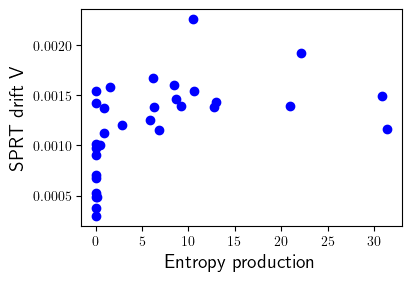

In [722]:
# dirname = '20250108/1bs-ir-ep-acc-c-0.1'
dirname = '20250221/ir-ep-finetune-hic'

ncpus = 16
nedges = 8
figsize = (4,2.7)
color_full = "red"
color_acc = "blue"
data, params = get_data(dirname, "full")

irvals_acc = [data[i][nedges] for i in range(1, params["nparams"]+1)]
epvals_acc = [data[i][nedges+1] for i in range(1, params["nparams"]+1)]
                
plt.rcParams['text.usetex'] = True

figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)

ax.scatter(epvals_acc, np.array(irvals_acc),  color=color_acc)
# ax.set_ylim(0, 2.5e-3)
# ax.set_xlim(0, 16)
ax.set_title("")
ax.set_ylabel("SPRT drift V", fontsize=14)
ax.set_xlabel("Entropy production", fontsize=14)

c = 0.1
dc = 0.1 * c
kboff = 0.0888
konb = 5
kuon = 5
koffu = 5

kbon = 1e-5
koffb = 1e-5
kuoff = 1e-5
konu = 1e-5

D_full2b = ((dc/c)**2/2) * (c*kboff*kuon/(c*kboff+kuon))
# ax.axhline(y=D_full2b, linestyle="dashed", color="red", alpha=0.3)
# ax.axhline(y=2*D_full2b/3, linestyle="solid", color="blue", alpha=0.3)
# ax.axhline(y=D_full2b/2, linestyle="dashed", color="blue", alpha=0.3)

IndexError: index 2 is out of bounds for axis 1 with size 2

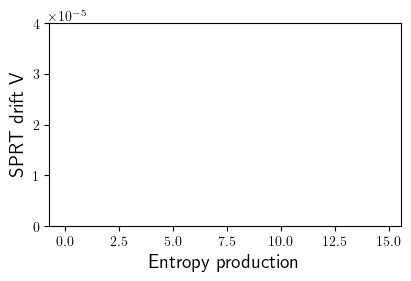

In [ ]:
dirname_full = '20241107/ir-ep'
dirname_full = '20241206/ir-ep-finetune-from-20241107/'
# dirname_acc = '20241204/1bs-ir-ep-acc'
# dirname_acc2 = '20241203/2bs-ir-ep/test-forcing-konu-de'
# dirname_acc = '20250115/1bs-ir-ep-c0-1'
# dirname_acc = '20250129/1bs-ir-ep-acc-c-1000-dc-0.01'
ncpus = 32
nedges = 8
# skipkeys = [1,2,3,4,5,6,7,9,10,11,12,13,15,17,20,23,29]
skipkeys = []
figsize = (4,2.7)
color_full = "red"
color_acc = "blue"
data_full, params_full = get_data(dirname_full, "full")
data_acc, params_acc = get_data(dirname_acc, "acc")
# data_acc2, params_acc2 = get_data(dirname_acc2, "acc")

irvals_full = [data_full[i][nedges] for i in range(1, params_full["nparams"]+1) if i not in skipkeys]
irvals_full_err = [data_full[i][nedges+2] for i in range(1, params_full["nparams"]+1) if i not in skipkeys]
epvals_full = [data_full[i][nedges+1] for i in range(1, params_full["nparams"]+1) if i not in skipkeys]

irvals_acc = [data_acc[i][nedges] for i in range(1, params_acc["nparams"]+1)]
epvals_acc = [data_acc[i][nedges+1] for i in range(1, params_acc["nparams"]+1)]
# irvals_acc2 = [data_acc2[i][10] for i in range(1, params_acc2["nparams"]+1)]
# epvals_acc2 = [data_acc2[i][10+1] for i in range(1, params_acc2["nparams"]+1)]
                   
plt.rcParams['text.usetex'] = True

figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)

# ax.errorbar(epvals_full, irvals_full, yerr=irvals_full_err, marker='o', linestyle='none', capsize=3, color=color_full, markersize=3)
ax.plot(epvals_acc, np.array(irvals_acc), linestyle='solid', color=color_acc)
# ax.plot(epvals_acc2, np.array(irvals_acc2), linestyle='solid', color=color_acc, alpha=0.4)

ax.set_ylim(0, 4e-5)
# ax.set_xlim(0, 16)
ax.set_title("")
ax.set_ylabel("SPRT drift V", fontsize=14)
ax.set_xlabel("Entropy production", fontsize=14)

c = 1000
dc = 0.01 * c
kboff = 0.0888
konb = 5
kuon = 5
koffu = 5

logrates = data_acc[32][:nedges]
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
input_edges = [(0,2), (1,3)]
on_ind = [0,1,0,1]
tauon, tauoff = ctmc.mean_fpt_part(we_lin, input_edges, 1000, on_ind)
taubmax = tauon + tauoff

kbon = 1e-5
koffb = 1e-5
kuoff = 1e-5
konu = 1e-5

D_full2b_highc = ((dc/c)**2/2) / taubmax
D_full2b = (2*(dc/c)**2/3) * (c*kboff*kuon/(c*kboff+kuon))
ax.axhline(y=D_full2b_highc, linestyle="solid", color="red", alpha=0.3, label="high c")
# ax.axhline(y=D_full2b, linestyle="solid", color="blue", alpha=0.3, label="low c")
# ax.axhline(y=D_full2b/2, linestyle="dashed", color="blue", alpha=0.3)
ax.legend()

In [3578]:
D_full2b

0.003365945375405737

In [225]:
date = 20241204
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/{}/ir-ep-acc-full.pdf'.format(date))

ir: 3.3843553e-05
ep: 20.588938


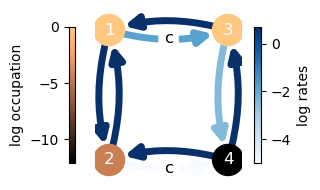

In [115]:
from matplotlib.colors import Normalize
importlib.reload(plot)

edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
ie = [(0,2), (1,3)]
weights = data_full[31][:8]
we = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
we[1][2] = -5
we[2][2] = -5
we[4][2] = -5
we[7][2] = -5
weights_acc = data_acc[31][:8]
we_acc = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights_acc)])

k = 32
weights_eq = data_full[1][:8]
we_eq = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights_eq)])
# we_eq[3][2] = -5
node_labels = dict(zip(range(4), range(1,5)))
input_labels = dict(zip(ie, ['c']*2))

weights_eq_acc = data_acc[1][:8]
we_eq_acc = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights_eq_acc)])
we_eq_acc_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights_eq_acc)])
Q = utils.build_mat(we_eq_acc_lin, ie, c)
pss = ctmc.P_ss(Q)
colors = [np.log(p) for p in pss]

fig, ax, G = plot.draw_circuit(we_eq_acc, ie, dims=(3.3,2), 
                               node_size=500, 
                               node_color=colors,
                               node_labels=node_labels, 
                               input_labels=input_labels,
                               colorbar=True)
print('ir:', data_acc[k][8])
print('ep:', data_acc[k][9])

nodes = list([n for n in G.nodes])

ax.set_axis_off()
norm = Normalize(min(colors), 0)
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper), 
             ax=ax, label="log occupation", location="left", shrink=0.8)

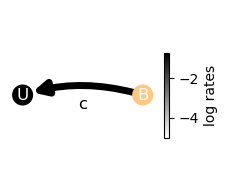

In [113]:
edges = np.array([(0,1), (1,0)])
ie = [(0,1)]
on_ind = [1]
c = 5.6
logrates = [-5, np.log(0.0888*c)]
we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])


Q = utils.build_mat(we, ie, c)
pss = ctmc.P_ss(Q)
colors = [np.log10(p) for p in pss]
node_labels = {0:'U', 1:'B'}
input_labels = {(0,1):'c'}

fig2s, ax2s, G = plot.draw_circuit(we, ie, dims=(2.4,2), 
                               node_size=200, 
                               node_color=colors,
                               node_labels=node_labels, 
                               input_labels=input_labels,
                               bottom_set=[0],
                               align="vertical",
                               edge_cmap=plt.cm.gray.reversed(),
                               colorbar=False)

norm = Normalize(min(logrates),max(logrates))
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax2s, label="log rates", location="right", shrink=0.5)


/tmp/ipykernel_4514/2015498719.py:37: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax1.plot(xhull, yhull, 'r-', lw=2,color="green")


AttributeError: module 'matplotlib.cm' has no attribute 'green'

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/IPython/core/events.py:82: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  func(*args, **kwargs)
/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/IPython/core/pylabtools.py:152: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


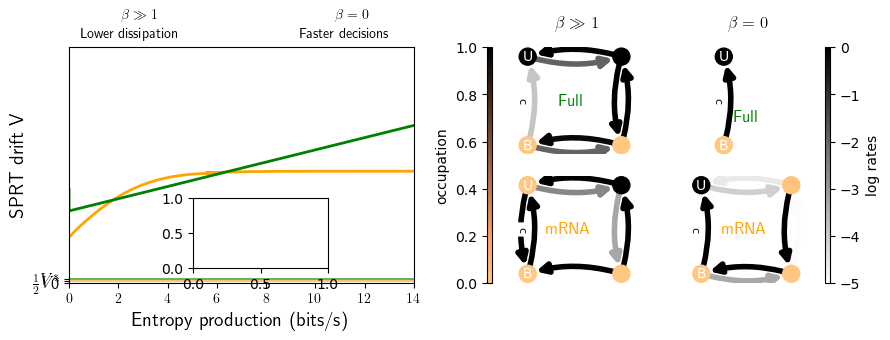

In [122]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from mpl_toolkits.axes_grid1 import make_axes_locatable
importlib.reload(plot)

# Create a figure
fig = plt.figure(figsize=(9, 3.5), layout="tight")

# Define the GridSpec with 1 row and 3 columns, and the right side having 2 rows
gs = gridspec.GridSpec(1, 3, width_ratios=[2.5,1,1])  # Left plot twice as wide

# Define a nested GridSpec for the right side with 2 rows
right_gs = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[2])
mid_gs = gridspec.GridSpecFromSubplotSpec(2, 1, subplot_spec=gs[1])

# Create the large plot on the left
ax1 = fig.add_subplot(gs[0])

## Convex hull
xydata_ = np.stack((epvals_full, irvals_full), axis=1)
# mask = np.where(np.bitwise_and(xydata[:,0] > xlb, xydata[:,0] < xub))
# xydata_ = xydata[mask]
hull = ConvexHull(xydata_)
xhull = [xydata_[hull.vertices[i]][0] for i in range(-5,2)]
yhull = [xydata_[hull.vertices[i]][1] for i in range(-5,2)]

# ax1.errorbar(epvals_full, irvals_full, yerr=irvals_full_err, marker='o', linestyle='none', 
#              capsize=3, color="green", markersize=3)
ax1.plot(epvals_acc, irvals_acc, lw=2,linestyle='solid', color="orange")
ax1.set_ylim(0, 2.5e-3)
ax1.set_xlim(0, 14)
ax1.set_ylabel("SPRT drift V", fontsize=14)
ax1.set_xlabel("Entropy production (bits/s)", fontsize=14)
ax1.axhline(y=D_full2b/2, lw=1.5,linestyle="solid", color="orange", alpha=0.6)
# ax1.axhline(y= 2*D_full2b/3, lw=0.6, linestyle="solid", color="black", alpha=0.6)
ax1.axhline(y=D_full2b, lw=1.5, linestyle="solid", color="green", alpha=0.6)
ax1.plot(xhull, yhull, 'r-', lw=2,color="green")
ax1.set_yticks([0,D_full2b/2,D_full2b])
ax1.set_yticklabels([0, r"$\frac{1}{2}V^*$", r"$V^*$"], fontsize=12)

ax1.text(0.5,2.6e-3,r"Lower dissipation", fontsize=10)
ax1.text(2.1,2.8e-3,r"$\beta \gg 1$", fontsize=10)
ax1.text(9.4,2.6e-3,r"Faster decisions", fontsize=10)
ax1.text(10.8,2.8e-3,r"$\beta = 0$", fontsize=10)
x = np.linspace(0, 14, 100)
y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect

# Use imshow to display the gradient as the background
# ax1.imshow(Z, extent=[0, 14, 0, 1], origin='lower', aspect='auto', cmap='coolwarm', alpha=0.2)

xl = -1.5
xr = 1
xmarg = 0.2
ymarg = 0.1
# Create the first smaller plot on the right (top part)
ax2 = fig.add_subplot(right_gs[0], xlim=(-1.1,1.4))
ax2.set_title(r"$\beta = 0$", x=0.45, y=1.1)
ax2.text(-0.2,-0.1,"Full", color="green", fontsize=12)

# Create the second smaller plot on the right (bottom part)
ax3 = fig.add_subplot(right_gs[1], xlim=(-1.1,1.4))
ax3.text(-0.4,-0.1,"mRNA", color="orange", fontsize=12)

# Create the second smaller plot on the right (top part)
ax4 = fig.add_subplot(mid_gs[0], xlim=(-1.4, 1))
ax4.set_title(r"$\beta \gg 1$", x=0.6, y=1.1)
ax4.text(-0.25,-0.1,"Full", color="green", fontsize=12)

# Create the second smaller plot on the right (bottom part)
ax5 = fig.add_subplot(mid_gs[1], xlim=(-1.4, 1))
ax5.text(-0.45,-0.1,"mRNA", color="orange", fontsize=12)

for ax, weights in zip([ax2, ax3, ax4, ax5], [we, we_acc, we_eq, we_eq_acc]):
    ax.set_axis_off()
    weights_lin = np.array([(u,v,10**w) for (u,v,w) in weights])
    Q = utils.build_mat(weights_lin, ie, c)
    pss = ctmc.P_ss(Q)
    colors = [np.log(p) for p in pss]
    
    _, _, G = plot.draw_circuit(weights, ie, 
                                dims=(2,1), 
                                figax = (fig, ax),
                                node_size=150, 
                                node_labels=node_labels, 
                                input_labels=input_labels,
                                node_cmap=plt.cm.copper.reversed(),
                                edge_cmap=plt.cm.Grays,
                                node_color=pss,
                                arrsize=15,
                                arrwidth=4,
                                edgefsize=8,
                                nodefsize=10)

divider1 = make_axes_locatable(ax1)
cax1 = divider1.new_horizontal(size='0%', pad=0.3, pack_start = False)

axl = fig.add_subplot(gs[1])
axr = fig.add_subplot(gs[2])

axl.set_axis_off()
axr.set_axis_off()

norm = Normalize(-5, 0)
dividerr = make_axes_locatable(axr)
caxr = dividerr.new_horizontal(size='10%', pad=0.9, pack_start = False)
fig.add_axes(caxr)
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.binary), cax = caxr, 
             label="log rates", location="right", shrink=0.5)

norm = Normalize(0,1)
dividerl = make_axes_locatable(axl)
caxl = dividerl.new_horizontal(size='10%', pad=0.95, pack_start = True)
fig.add_axes(caxl)
plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
            cax=caxl, label="occupation", location="left", shrink=0.5)

left, bottom, width, height = [0.22, 0.22, 0.15, 0.2]
ax_inset = fig.add_axes([left, bottom, width, height])

edges = np.array([(0,1), (1,0)])
ie = [(0,1)]
on_ind = [1]
c = 5.6
logrates = [-5, np.log(0.0888*c)]
we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])


Q = utils.build_mat(we, ie, c)
pss = ctmc.P_ss(Q)
colors = [np.log10(p) for p in pss]
node_labels = {0:'U', 1:'B'}
input_labels = {(0,1):'c'}

fig2s, ax2s, G2s = plot.draw_circuit(we, ie, figax=(fig, ax_inset), 
                                   dims=(2,1.6), 
                                   node_size=200, 
                                   node_color=colors,
                                   node_labels=node_labels, 
                                   input_labels=input_labels,
                                   bottom_set=[0],
                                   rmin=-6,
                                   align="vertical",
                                   edge_cmap=plt.cm.green.reversed(),
                                   colorbar=False)

ax1.text(11.8, 0.0003, "(a)", fontsize=18)
ax1.text(23.5, 0.0003, "(b)", fontsize=18)

# Adjust layout to avoid overlap
plt.tight_layout()
plt.subplots_adjust(wspace=0.2, hspace=0.2)

# Show the plot we_eq_acc
plt.show()

In [2044]:
date = 20250114
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/ir-ep-with-opt-circuits.pdf'.format(os.environ["HOME"], date))

## $\min \{\langle T \rangle + \beta EP\}$

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


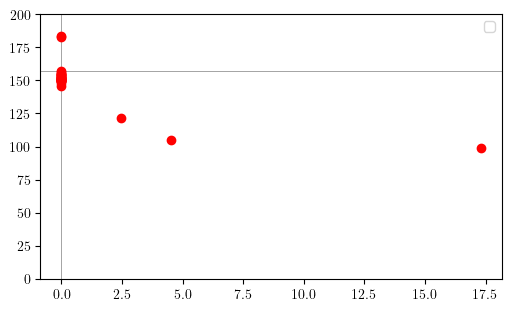

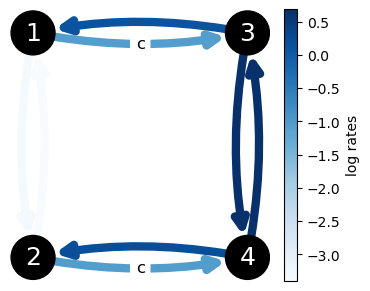

(<Figure size 360x280 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x78b72e972190>)

In [ ]:
dirname = '20241204/dt-ep'
whichf = "full"
nedges = 8
k = 29
figsize = (5,3)
showlines = True
fig, ax, data = plot_data(None, color="red", figsize=figsize)
ax.legend()
# ax.set_xlim(0,20)
ax.set_ylim(0, 200)
weights = data[k][:nedges]

edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
iedges = [(0,2), (1,3)]
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
on_ind = [0,1,0,1]
node_labels = dict(zip(range(4), range(1,5)))
input_labels = dict(zip(iedges, ['c']*2))
bottom_set = [1,3]
node_size=1000

Q = utils.build_mat(wedges_lin, iedges, 5.6)
pss = ctmc.P_ss(Q)
G = nx.DiGraph()
for u, v, w in wedges:
    G.add_edge(u, v, weight=w)

# node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]
node_color = np.zeros(4)

plot.draw_circuit(wedges, 
                iedges, 
                node_labels=node_labels, 
                input_labels=input_labels,
                bottom_set=bottom_set,
                node_size=node_size,
                node_color=node_color,
                #   title="2 binding sites",
                dims=(3.6,2.8))

In [143]:
dirname = '/home/tohme/phd/flython/plots/{}'.format(20241128)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/dt-ep-three-epsilons.pdf')

In [86]:
fig.savefig('plots/optimal_circuit_4s_acc_beta0.pdf')

## $\min \{ \langle T \rangle + \beta Var(T) \}$

Text(0.5, 0, '$Var(T)$')

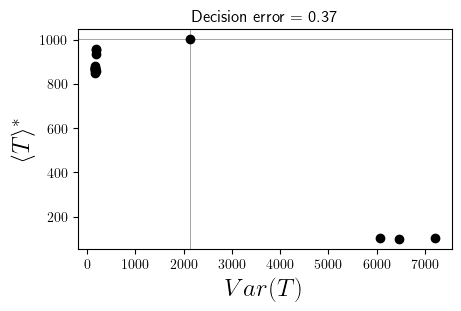

In [265]:
dirname = '20241127/dt-vart/test-e=0.37-k=2000-n=5000-maxiters=5000/'
k = 7
showlines = True
fig, ax, data = plot_ir_ep(None, color="black")

ax.axhline(y = data[k][8], linewidth=0.5, color="gray")
ax.axvline(x = data[k][9], linewidth=0.5, color="gray")
ax.set_xlabel("$Var(T)$")

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


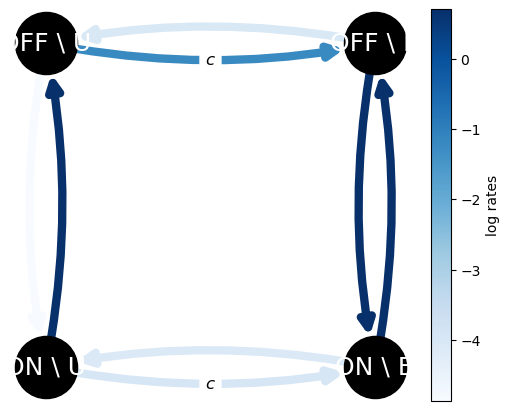

(<Figure size 500x400 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x7c9d279ed850>)

In [266]:
logrates = data[k][:nedges]
edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
input_edges = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1])
we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])

plot.draw_circuit(we, input_edges)

# Modeling specificity with one binding site

### IR versus [wrong ligand] / [right ligand]

(0.0, 1.05)

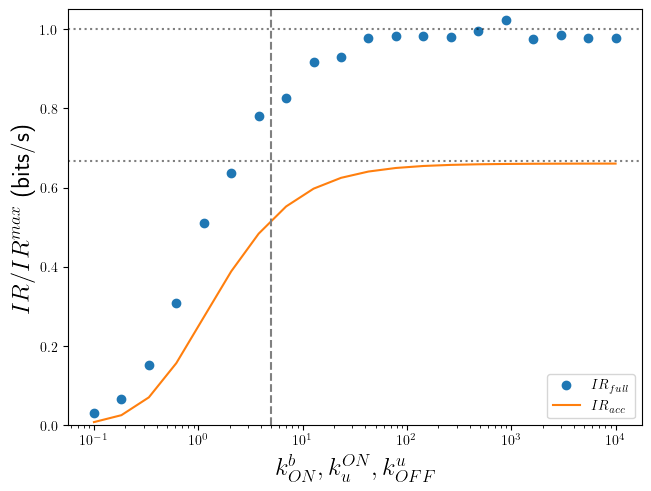

In [252]:
data_full = json.load(open('/home/tohme/.julia/dev/LLROpt/data/ir_full_scaling_output_20240725.json'))
data_acc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/ir_acc_scaling_output_20240725.json'))

nvals = len(data_full.keys())

xvals = np.logspace(-1, 4, 20)
# ir_full_pure = data["ir_full_pure"]
# ir_full_mix = data["ir_full_mix"]
# ir_acc_pure = data["ir_acc_pure"]
# ir_acc_mix = data["ir_acc_mix"]

fig, ax = plt.subplots(1,1, layout='constrained')

# ax.plot(xvals, ir_full_pure, 'o', color='C1', label=r"$IR_{f}^{pure}$")
# ax.plot(xvals, ir_full_mix, 'o', color='C2', label=r"$IR_{f}^{mix}$")

# ax.plot(xvals, ir_acc_pure, color='C1', label=r"$IR_{a}^{pure}$")
# ax.plot(xvals, ir_acc_mix, color='C2', label=r"$IR_{a}^{mix}$")
ax.plot(xvals, [data_full[str(i)] for i in range(1, nvals+1)], 'o', label=r"$IR_{full}$")
ax.plot(xvals, [2*data_acc[str(i)]/3 for i in range(1, nvals+1)], label=r"$IR_{acc}$")
ax.set_xlabel(r"$k_{ON}^b, k_{u}^{ON}, k_{OFF}^u$", fontsize=18)
ax.set_ylabel(r"$IR/IR^{max}$ (bits/s)", fontsize=18)
ax.axvline(x=5, linestyle='dashed', color='gray')
ax.axhline(y=1, linestyle='dotted', color='black', alpha=0.5)
ax.axhline(y=2/3, linestyle='dotted', color='black', alpha=0.5)
ax.legend()
ax.set_xscale('log')

ax.set_ylim(0, 1.05)

In [253]:
fig.savefig("plots/ir_limit_konb_kuon_koffu_large_notrescaled_20240725.pdf")

### maximizing $DR + \beta \epsilon$

In [172]:
def f(x,g):
    a = 1/g
    b = 1-a/(1-a)
    if a >= 1/2:
        return (2*a-1)/(1-a)**2
    else:
        return (1-a)*a**(-1/(1-a))*np.sin(np.pi*a/(1-a))*x**b/np.pi

In [4]:
# dirname = '20241004/full'
# dirname = '20241111/ir-epsilon'
# dirname = '20241113/ir-dr'
# dirname = '20241116/ir-dr-from-20241113/cmaes'
# dirname = '20241114/ir-epsilon-hernan/gen2'
# dirname = '20241116/dr-epsilon-from-20241114/cmaes'
# dirname = '20241114/dr-epsilon'
# dirname = '20241118/dr-epsilon-hernan/bigsweep-cmaes-C-pn'
# whichf = "full"

In [ ]:
whichf = "acc"
k, kg, kw = (1, 3, 2)
ginds, winds = [2], [1]
# ylb, yub = -4e-5, 18.5e-4
# xlb, xub = 9.5, 13.7        # low omega

# ylb, yub = -4e-5, 18.5e-4
# xlb, xub = 9.5, 13.7        # medium omega

ylb, yub = None, None
xlb, xub = None, None
showbound = True
showlines = False
showlegend = True
legend_loc = 'upper right'
ylab = r"$DR^*$"
xlab = r"$- \log(\varepsilon^*)$"
fill = "full"
line = "none"
msize = 3

cr = 5.6

In [177]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
from matplotlib.colors import Normalize
importlib.reload(plot)

def plot_pareto(figax, plotcirc=False, color=None):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data_acc = {}
    data_acc_proc = {}
    ncpus = params_acc["ncpus"]
    nbetas = params_acc["nparams"]
    betas = params_acc["betas"]
    gammas = params_acc["gammas"]
    wvals = params_acc["wvals"]
    nparams_per_cpu = int(nbetas/ncpus)

    a = 3e-3        # um
    D_tf = 7.4      # um^2/s
    D_cplx = 0.1    # um^2/s
    # cr = 5.6         # um^-3
    dc = 0.1 * cr
    dl_tf = 4*a*D_tf
    ub = 5
    lb = 1e-5

    g = gammas[kg-1]
    w = wvals[kw-1]
    cw = w*cr
    x = cr / (cr+cw)

    # max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)
    # tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
    # max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

    for cpukey in range(1, ncpus + 1):
        data_acc_proc = json.load(open(path+'{}/ir_{}_mix_vs_pure_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data_acc[str(keyb)] = data_acc_proc[str(keyb)]

    # plt.rcParams['text.usetex'] = True

    if figax is None:
        figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)
    else:
        figplot, ax = figax

    colors = ['C{}'.format(i) for i in range(len(gammas))]
    markers = ['d','^','o']
    node_color = ""
    epvals = np.zeros((len(gammas), nbetas))
    cmap = plt.colormaps["coolwarm"]

    if whichf == "acc":
        epindex = 10
    else:
        epindex = 12

    for i in ginds:
        gamma = gammas[i]
        for j in winds:

            keyg = str(i+1)
            keyw = str(j+1)

            xopt = np.array([data_acc[str(k)][keyg][keyw][:8] for k in np.arange(1, nbetas+1, 1)])
            ir_acc_mix = np.array([data_acc[str(k)][keyg][keyw][8] for k in np.arange(1, nbetas+1, 1)])
            ir_acc_pure = np.array([data_acc[str(k)][keyg][keyw][9] for k in np.arange(1, nbetas+1, 1)])
            epvals[i] = np.array([data_acc[str(k)][keyg][keyw][epindex] for k in np.arange(1, nbetas+1, 1)])

            for x in range(nbetas - 1):
                if color is None:
                    col = cmap(epvals[i,x])
                else:
                    col = color

                ax.plot([ir_acc_mix[x], ir_acc_mix[x+1]],
                        [ir_acc_pure[x], ir_acc_pure[x+1]],
                        marker=markers[i], 
                        fillstyle=fill,
                        color=col, 
                        linestyle=line, 
                        markersize=msize)


            ax.set_ylabel(ylab, fontsize=18)
            ax.set_xlabel(xlab, fontsize=22)
            irvals = np.linspace(0, 2e-3, 50)

        if showbound:
            ax.axvline(x=np.log2(gamma**2), linestyle='dashed', color='gray', alpha=0.6)
            ax.axvline(x=np.log2(gamma), linestyle='dotted', color='gray', alpha=0.6)
            ax.axhline(y=0.001186*cr/5.6, linestyle='solid', color='gray', alpha=0.6)

    _=ax.set_title(r"$\omega = c_w/c_r$ = {}".format(w), fontsize=20)

    xopt_acc = data_acc[str(k)][str(kg)][str(kw)][:8]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = xopt_acc
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
            konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]

    edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
            (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
    wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
    wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])

    iedges = [(0,2), (1,3)]
    on_ind = np.array([0,1,0,1,0,1])
    Q = utils.build_mat(wedges_acc_lin, iedges, cr)
    pss = ctmc.P_ss(Q)
    pc = sum(pss[[0]])

    if ylog:
        ax.set_yscale('log')

    # h1 = mpatches.Patch(color=colors[j])  
    # wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
    gammalabels = list(zip(*[(Line2D([0], [0], linestyle='none', fillstyle='none',marker=markers[i], color="black"),r"$\gamma = {}$".format(round(g, 1))) for (i,g) in enumerate(gammas)]))

    # ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
    if showlegend:
        ax.legend(gammalabels[0], gammalabels[1], loc='upper right', fontsize=8)
        ax.legend((Line2D([0], [0], linestyle='dotted', color='gray'),
                Line2D([0], [0], linestyle='dashed', color='gray'),
                Line2D([0], [0], linestyle='solid', color='gray')),
                (r"$\log(\gamma)$",r"$\log(\gamma^2)$", r"$\frac{1}{4\tau}(\frac{dc}{c})^2$"), loc=legend_loc) # (0.5,0.1)
    ax.set_ylim(ylb, yub)
    ax.set_xlim(xlb, xub)

    if showlines:
        ax.axhline(y = data_acc[str(k)][str(kg)][str(kw)][9], linewidth=0.5, color="gray")
        ax.axvline(x = data_acc[str(k)][str(kg)][str(kw)][8], linewidth=0.5, color="gray")

    if color is None:
        if figax is None:
            cb = figplot.colorbar(plt.cm.ScalarMappable(norm=Normalize(0,max(epvals.flatten())), cmap=cmap),
                                ax=ax)

            cb.set_label(label="$EP$ rate", fontsize=14)

    G = nx.DiGraph()
    for u, v, w in wedges_acc_lin:
        G.add_edge(u, v, weight=w)

    if node_color != "black":
        node_color = [np.log(pss[int(i)]) for i in G.nodes()]

    node_labels = {0: r'FU',
                    1: r'NU',
                    2: r'FBR',
                    3: r'NBR',
                    4: r'FBW',
                    5: r'NBW'}

    node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

    input_labels = {(0,4):"cw",
                    (0,2):"cr",
                    (1,5):"cw",
                    (1,3):"cr"}

    if plotcirc:
        figcirc, axcirc, G = plot.draw_circuit(wedges_acc,
                                        iedges, 
                                        node_labels=node_numbers, 
                                        input_labels=input_labels,
                                        bottom_set=[5,1,3],
                                        node_size=1000,
                                        node_color=node_color,
                                        title="IR_acc",
                                        dims=(5,2.8))
    else:
        figcirc = None
    
    return figplot, ax, xopt_acc, logrates2, data_acc, params_acc

/tmp/ipykernel_4514/306629400.py:50: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax.plot(xhull, yhull, 'r-', lw=2,color=cols[id])
/tmp/ipykernel_4514/306629400.py:121: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax.plot(xhull, yhull, 'r--', lw=2,color=cols[id])


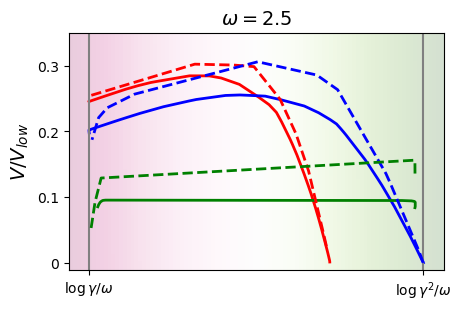

In [451]:
plt.rcParams["text.usetex"] = False

dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-A-pn-simfull-200k-fcalls-lownoise'
whichf = "full"
msize = 0
ylog = False
showbound = False
showlines = False
k, kg, kw = (1, 3, 2)
ginds, winds = [2], [1]
figsize = (4.5,3)
ylb, yub = None, None
xlb, xub = None, None
figplot, ax, _, _, dataA, paramsA = plot_pareto(None, color="red")      # local optimization
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-B-pn-simfull-100k-fcalls-lownoise'
figplot, ax, _, _, dataB, paramsB = plot_pareto((figplot, ax), color="blue")
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-C-pn-simfull-200k-fcalls-lownoise'
figplot, ax, _, _, dataC, paramsC = plot_pareto((figplot, ax), color="green")

cols = ["red", "blue", "green", "red", "blue", "green"]
# rx = [(5,63), (5,50), (12,18)] # low omega
rx = [(5,42), (2,38), (8,32)]
msize = 5

g = paramsA["gammas"][kg-1]
w = paramsA["wvals"][kw-1]
dlb, dub = np.log2(g/w), np.log2(g**2/w)
vlow = 0.5*0.01*5.6*0.0888
nbetas = 512

ax.set_xlim(dlb+ np.log2(0.87), dub + np.log2(1.15))
# ax.set_ylim(-5e-5, vlow/3)

## Convex hull
for (id, data) in enumerate([dataA, dataB, dataC]):
    drvals = np.array([data[str(k)][str(key_g)][str(key_w)][8] for k in np.arange(1, nbetas+1, 1)])
    epsvals = np.array([data[str(k)][str(key_g)][str(key_w)][9] for k in np.arange(1, nbetas+1, 1)])

    xydata = np.stack((drvals, epsvals), axis=1)
    mask = np.where(np.bitwise_and(xydata[:,0] > dlb, xydata[:,0] < dub))
    xydata_ = xydata[mask]
    hull = ConvexHull(xydata_)
    xhull = [xydata_[hull.vertices[i]][0] for i in range(rx[id][0], rx[id][1])]
    yhull = [xydata_[hull.vertices[i]][1] for i in range(rx[id][0], rx[id][1])]

    # if id == 2:
    #     ax.scatter(drvals[-3], epsvals[-3], s=110, marker='o', color=cols[id], 
    #                facecolors="none", linestyle='-', lw=2)
    # else:
    ax.plot(xhull, yhull, 'r-', lw=2,color=cols[id])

k, kg, kw = (1, 1, 2)
ginds, winds = [0], [1]
# dirname = '20241206/dr-epsilon/cmaes-A-pn-full/'
msize = 0
dirname = '20241120/dr-epsilon/cmaes-A-pn-full/'
whichf = "full"
figplot, ax, _, _, datafA, paramsfA = plot_pareto((figplot, ax), color="red")      # local optimization
dirname = '20241120/dr-epsilon/cmaes-B-pn-full'
figplot, ax, _, _, datafB, paramsfB = plot_pareto((figplot, ax), color="blue")
dirname = '20241120/dr-epsilon/cmaes-C-pn-full'
figplot, ax, _, _, datafC, paramsfC = plot_pareto((figplot, ax), color="green")

# ax.get_legend().remove()
# ax.axvline(x=dlb, linestyle='dotted', color='black', alpha=0.5, label=r"$\log (\gamma / \omega)$")
# ax.axvline(x=dub, linestyle='dashed', color='black', alpha=0.5, label=r"$\log (\gamma^2 / \omega)$")
# ax.legend(loc=(0.15, 0.07), fontsize=12)
ax.set_ylabel("$V/V_{low}$", fontsize=14)

# ax.set_xlabel(r"$-\log(\varepsilon)$", fontsize=14)
# ax.text(2, 1e-3, r"$\beta = 0$", fontsize=10)
# ax.text(2, 1.1e-3, "Faster decisions", fontsize=10)
# ax.text(5, 1e-3, r"$\beta \gg 1$", fontsize=10)
# ax.text(5,1.1e-3,"Lower errors", fontsize=10)
x = np.linspace(9.5, 14, 100)
y = np.linspace(-1e-2, 1e-2, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect

ax.set_title(r"$\omega = 2.5$", fontsize=14)

# Use imshow to display the gradient as the background
ax.imshow(Z, extent=[dlb+ np.log2(0.85),dub+ np.log2(1.18),-1e-4,vlow/2], origin='lower', aspect='auto', cmap='PiYG', alpha=0.2)

# rx = [(1,12), (1,11), (4,7)]
rx = [(-8,1), (-11,1), (1,7)]
msize = 5

# key_g = 1
# key_w = 2
# g = paramsfA["gammas"][key_g-1]
# w = paramsfA["wvals"][key_w-1]
# dlb, dub = np.log2(g/w), np.log2(g**2/w)
nbetas = 32

ax.set_ylim(-0.01*vlow,0.35*vlow)
ax.set_yticks(np.linspace(0,0.3,4)*vlow)
ax.set_yticklabels([0,0.1,0.2,0.3])
ax.axvline(x=dub, linestyle="solid", color="gray")
ax.axvline(x=dlb, linestyle="solid", color="gray")
ax.set_xticks([dlb,dub])
ax.set_xticklabels(["$\log \gamma/\omega$", "$\log \gamma^2/\omega$"])
ax.set_xlabel("", fontsize=14)

# ## Convex hull
for (id, data) in enumerate([datafA, datafB, datafC]):
    drvals = np.array([data[str(k)][str(kg)][str(kw)][8] for k in np.arange(1, nbetas+1, 1)])
    epsvals = np.array([data[str(k)][str(kg)][str(kw)][9] for k in np.arange(1, nbetas+1, 1)])

    xydata = np.stack((drvals, epsvals), axis=1)
    mask = np.where(np.bitwise_and(xydata[:,0] > dlb, xydata[:,0] < dub))
    xydata_ = xydata[mask]
    hull = ConvexHull(xydata_)
    xhull = [xydata_[hull.vertices[i]][0] for i in range(rx[id][0], rx[id][1])]
    yhull = [xydata_[hull.vertices[i]][1] for i in range(rx[id][0], rx[id][1])]

    # if id == 2:
    #     ax.scatter(drvals[-3], epsvals[-3], s=110, marker='o', color=cols[id], 
    #                facecolors="none", linestyle='dashed', lw=2)
    # else:
    ax.plot(xhull, yhull, 'r--', lw=2,color=cols[id])

In [452]:
date = 20250225
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

figplot.savefig('/home/tohme/phd/flython/plots/{}/dr-epsilon-clean-hiw.svg'.format(date))

/tmp/ipykernel_4514/4211798485.py:50: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r-" (-> color='r'). The keyword argument will take precedence.
  ax.plot(xhull, yhull, 'r-', lw=2,color=cols[id])
/tmp/ipykernel_4514/4211798485.py:122: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "r--" (-> color='r'). The keyword argument will take precedence.
  ax.plot(xhull, yhull, 'r--', lw=2,color=cols[id])


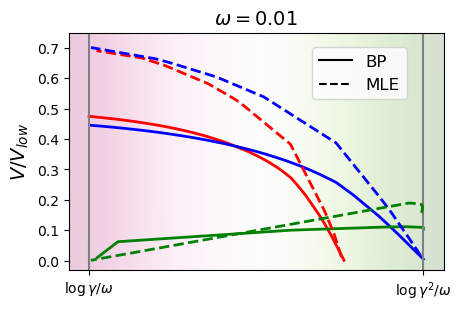

In [446]:
plt.rcParams["text.usetex"] = False

dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-A-pn-simfull-200k-fcalls-lownoise'
whichf = "full"
msize = 0
fill = "full"
ylog = False
showbound = False
k, kg, kw = (1, 3, 1)
ginds, winds = [2], [0]
figsize = (4.5,3)
ylb, yub = None, None
xlb, xub = None, None
figplot, ax, _, _, dataA, paramsA = plot_pareto(None, color="red")      # local optimization
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-B-pn-simfull-100k-fcalls-lownoise'
figplot, ax, _, _, dataB, paramsB = plot_pareto((figplot, ax), color="blue")
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-C-pn-simfull-200k-fcalls-lownoise'
figplot, ax, _, _, dataC, paramsC = plot_pareto((figplot, ax), color="green")

cols = ["red", "blue", "green", "red", "blue", "green"]
rx = [(5,63), (5,50), (-5,2)] # low omega
# rx = [(5,42), (2,38), (2,100)]

g = paramsA["gammas"][kg-1]
w = paramsA["wvals"][kw-1]
dlb, dub = np.log2(g/w), np.log2(g**2/w)
vlow = 0.5*0.01*5.6*0.0888
nbetas = 512

ax.set_xlim(dlb+ np.log2(0.87), dub + np.log2(1.15))
# ax.set_ylim(-5e-5, vlow/3)

## Convex hull
for (id, data) in enumerate([dataA, dataB, dataC]):
    drvals = np.array([data[str(k)][str(kg)][str(kw)][8] for k in np.arange(1, nbetas+1, 1)])
    epsvals = np.array([data[str(k)][str(kg)][str(kw)][9] for k in np.arange(1, nbetas+1, 1)])

    xydata = np.stack((drvals, epsvals), axis=1)
    mask = np.where(np.bitwise_and(xydata[:,0] > dlb, xydata[:,0] < dub))
    xydata_ = xydata[mask]
    hull = ConvexHull(xydata_)
    xhull = [xydata_[hull.vertices[i]][0] for i in range(rx[id][0], rx[id][1])]
    yhull = [xydata_[hull.vertices[i]][1] for i in range(rx[id][0], rx[id][1])]

    # if id == 2:
    #     ax.scatter(drvals[-3], epsvals[-3], s=110, marker='o', color=cols[id], 
    #                facecolors="none", linestyle='-', lw=2)
    # else:
    
    ax.plot(xhull, yhull, 'r-', lw=2,color=cols[id])

k, kg, kw = (1, 1, 1)
ginds, winds = [0], [0]
# dirname = '20241206/dr-epsilon/cmaes-A-pn-full/'
msize = 0
fill = "none"
dirname = '20241120/dr-epsilon/cmaes-A-pn-full/'
whichf = "full"
figplot, ax, _, _, datafA, paramsfA = plot_pareto((figplot, ax), color="red")      # local optimization
dirname = '20241120/dr-epsilon/cmaes-B-pn-full'
figplot, ax, _, _, datafB, paramsfB = plot_pareto((figplot, ax), color="blue")
dirname = '20241120/dr-epsilon/cmaes-C-pn-full'
figplot, ax, _, _, datafC, paramsfC = plot_pareto((figplot, ax), color="green")

# ax.get_legend().remove()
# ax.axvline(x=dlb, linestyle='dotted', color='black', alpha=0.5, label=r"$\log (\gamma / \omega)$")
# ax.axvline(x=dub, linestyle='dashed', color='black', alpha=0.5, label=r"$\log (\gamma^2 / \omega)$")
# ax.legend(loc=(0.15, 0.07), fontsize=12)
ax.set_ylabel("$V/V_{low}$", fontsize=14)

# ax.set_xlabel(r"$-\log(\varepsilon)$", fontsize=14)
# ax.text(2, 1e-3, r"$\beta = 0$", fontsize=10)
# ax.text(2, 1.1e-3, "Faster decisions", fontsize=10)
# ax.text(5, 1e-3, r"$\beta \gg 1$", fontsize=10)
# ax.text(5,1.1e-3,"Lower errors", fontsize=10)
x = np.linspace(9.5, 14, 100)
y = np.linspace(-1e-2, 1e-2, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect

ax.set_title(r"$\omega = 0.01$", fontsize=14)

# Use imshow to display the gradient as the background
ax.imshow(Z, extent=[dlb+ np.log2(0.85),dub+ np.log2(1.18),-1e-4,vlow], origin='lower', aspect='auto', cmap='PiYG', alpha=0.2)

rx = [(1,14), (-5,6), (0,8)]
# rx = [(-8,1), (-11,1), (1,5)]
msize = 4

# key_g = 1
# key_w = 2
# g = paramsfA["gammas"][key_g-1]
# w = paramsfA["wvals"][key_w-1]
# dlb, dub = np.log2(g/w), np.log2(g**2/w)
nbetas = 32

ax.set_ylim(-0.03*vlow,0.75*vlow)
ax.set_yticks(np.linspace(0,0.7,8)*vlow)
ax.set_yticklabels(np.linspace(0,7,8,dtype='int')/10)
ax.axvline(x=dub, linestyle="solid", color="gray")
ax.axvline(x=dlb, linestyle="solid", color="gray")
ax.set_xticks([dlb,dub])
ax.set_xticklabels(["$\log \gamma/\omega$", "$\log \gamma^2/\omega$"])
ax.set_xlabel("", fontsize=14)

# ## Convex hull
for (id, data) in enumerate([datafA, datafB, datafC]):
    drvals = np.array([data[str(k)][str(kg)][str(kw)][8] for k in np.arange(1, nbetas+1, 1)])
    epsvals = np.array([data[str(k)][str(kg)][str(kw)][9] for k in np.arange(1, nbetas+1, 1)])

    xydata = np.stack((drvals, epsvals), axis=1)
    mask = np.where(np.bitwise_and(xydata[:,0] > dlb, xydata[:,0] < dub))
    xydata_ = xydata[mask]
    hull = ConvexHull(xydata_)
    xhull = [xydata_[hull.vertices[i]][0] for i in range(rx[id][0], rx[id][1])]
    yhull = [xydata_[hull.vertices[i]][1] for i in range(rx[id][0], rx[id][1])]

    # if id == 2:
    #     ax.scatter(drvals[-3], epsvals[-3], s=110, marker='o', color=cols[id], 
    #                facecolors="none", linestyle='dashed', lw=2)
    # else:
    ax.plot(xhull, yhull, 'r--', lw=2,color=cols[id])

ax.legend((Line2D([0], [0], linestyle='solid', color='black'),
           Line2D([0], [0], linestyle='dashed', color='black')),
           ("BP","MLE"), loc=(0.65, 0.72), fontsize=12)

In [450]:
date = 20250225
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

figplot.savefig('/home/tohme/phd/flython/plots/{}/dr-epsilon-clean-loww.svg'.format(date))

In [131]:
figplot.savefig('/home/tohme/phd/flython/plots/20241120/dr_epsilon_hernan_de_localsearch_ABC_loww.pdf')

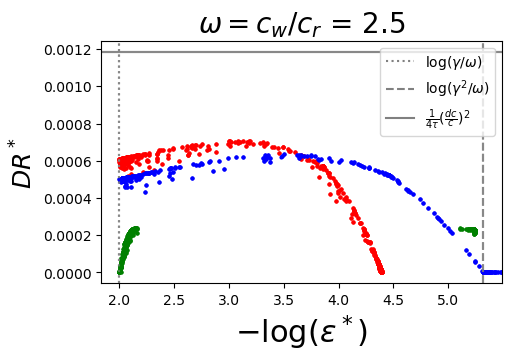

In [2398]:
k, kg, kw = (1, 1, 2)
ginds, winds = [0], [1]
# ylb, yub = -4e-5, 12.5e-4
# xlb, xub = 1.5, 5.8
ylb, yub = None, None
xlb, xub = None, None
showbound = True
showlines = False
showlegend = True
legend_loc = 'upper right'
ylab = r"$DR^*$"
xlab = r"$ \log(f^*)$"
figsize = (5,3.5)
fill = "none"
msize = 6

# dirname = '20241114/dr-epsilon'
# dirname = '20241206/dr-epsilon/cmaes-A-pn-full/'
# whichf = "full"
# figplot, ax, rates1, rates2, _, _ = plot_pareto(None, color="red")      # local optimization
# dirname = '20241206/dr-epsilon/cmaes-B-pn-full'
# figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="blue")
# dirname = '20241206/dr-epsilon/cmaes-C-pn-full'
# figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="green")

# ax.text(3, 8.5e-4, "A", color="red", fontsize=20)
# ax.text(4.2, 8e-4, "B", color="blue", fontsize=20)
# ax.text(5.1, 4.5e-4, "C", color="green", fontsize=20)

# ax.text(10.5, 12.5e-4, "A", color="red", fontsize=20)
# ax.text(12, 14e-4, "B", color="blue", fontsize=20)
# ax.text(13, 7.5e-4, "C", color="green", fontsize=20)

k, kg, kw = (1, 3, 2)
ginds, winds = [2], [1]
fill = "full"
msize = 2

dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-A-pn-simfull-200k-fcalls-lownoise'
whichf = "full"
figplot, ax, rates1, rates2, _, _ = plot_pareto(None, color="red")      # local optimization
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-B-pn-simfull-100k-fcalls-lownoise'
figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="blue")
dirname = '20241121/dr-epsilon-hernan/bigsweep-cmaes-C-pn-simfull-200k-fcalls-lownoise'
figplot, ax, _, _, _, _ = plot_pareto((figplot, ax), color="green")

In [125]:
figplot.savefig('/home/tohme/phd/flython/plots/20241120/dr_epsilon_full_hernan_de_localsearch_ABC_loww.pdf')

In [576]:
k, kg, kw = (32, 1, 2)

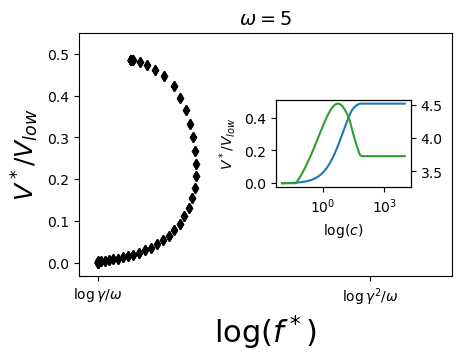

In [623]:
# k, kg, kw = (35, 1, 6)
ginds, winds = [kg-1], [kw-1]
ylb, yub = -1e-4, 3e-3
xlb, xub = 3, 7
ylb, yub = None, None
# xlb, xub = None, None
showbound = False
showlines = False
showlegend = False
legend_loc = 'upper right'
ylab = r"$V^*$"
xlab = r"$ \log(f^*)$"
figsize = (4.5,3.5)
fill = "full"
line = "none"
ylog = False
msize = 5

# dirname = '20250122/dr-epsilon-hernan/de-global-cold-start-acc-c0-w-sweep'
# dirname = '20250201/1bs-sens-spec-c-run1'
# whichf = "full"
# figplot, ax, rates1, rates2, data, params = plot_pareto(figax=None, color="black")

# k, kg, kw = (3, 1, 1)
ginds, winds = [kg-1], [kw-1]
dirname = '20250122/dr-epsilon-hernan/de-global-cold-start-acc-c0-w-sweep'
# dirname = '20250201/1bs-sens-spec-c-run1'
whichf = "acc"
figplot, ax, rates1, rates2, data, params = plot_pareto(figax=None, color="black")

g = params["gammas"][kg-1]
w = params["wvals"][kw-1]
conc = params["betas"]
nbetas = len(conc)
dlb, dub = np.log2(g), np.log2(g**2)

ax.set_ylim(-0.03*vlow,0.55*vlow)
ax.set_yticks(np.linspace(0,0.5,6)*vlow)
ax.set_yticklabels(np.arange(0,6,1)/10)
ax.set_ylabel(r"$V^*/V_{low}$")

ax.set_xlim(dlb + np.log2(0.85), dub + np.log2(2))
ax.set_xticks([dlb,dub])
ax.set_xticklabels(["$\log \gamma/\omega$", "$\log \gamma^2/\omega$"])
ax.set_title("$\omega = 5$", fontsize=14)

left, bottom, width, height = [0.6, 0.48, 0.3, 0.25]
ax2 = figplot.add_axes([left, bottom, width, height])
ax2x = ax2.twinx()

irvals = np.array([data[str(k)][str(kg)][str(kw)][8] for k in np.arange(1, nbetas+1, 1)])
spec = np.array([data[str(k)][str(kg)][str(kw)][9] for k in np.arange(1, nbetas+1, 1)])
epvals = np.array([data[str(k)][str(kg)][str(kw)][10] for k in np.arange(1, nbetas+1, 1)])

ax2.set_xscale('log')
ax2.set_xlabel("$\log(c)$")
ax2.set_ylabel("$V^*/V_{low}$")
ax2x.plot(conc, irvals, color="C2")
ax2.plot(conc, spec/vlow)


Text(0.5, 1.0, '$\\omega=5$')

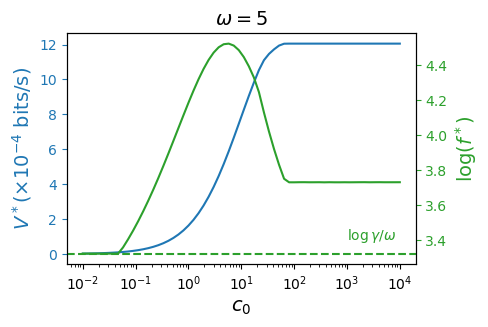

In [714]:
dirname = '20250122/dr-epsilon-hernan/de-global-cold-start-acc-c0-w-sweep'
# dirname = '20250201/1bs-sens-spec-c-run1'
whichf = "acc"

data, params = get_data(dirname, whichf, whicha="spec")

fig2, ax2 = plt.subplots(1,1,figsize=(4.5, 3.0))
ax2x = ax2.twinx()

irvals = np.array([data[k][str(kg)][str(kw)][8] for k in np.arange(1, nbetas+1, 1)])
spec = np.array([data[k][str(kg)][str(kw)][9] for k in np.arange(1, nbetas+1, 1)])
epvals = np.array([data[k][str(kg)][str(kw)][10] for k in np.arange(1, nbetas+1, 1)])

ax2.set_xscale('log')
# ax2.set_yscale('log')
ax2.set_xlabel("$c_0$", fontsize=14)
ax2.set_ylabel("$V^* (\\times 10^{-4}$ bits/s)", fontsize=14, color="C0")
ax2.tick_params(colors="C0", axis='y')
ax2.set_yticks(np.arange(0,13,2)*1e-4)
ax2.set_yticklabels(np.arange(0,13,2))

ax2x.plot(conc, irvals, color="C2")
ax2x.set_ylabel("$\log(f^*)$", fontsize=14, color="C2")
ax2x.tick_params(colors="C2")
# ax2x.set_yticklabels([0,"$\log \gamma/\omega$", "$\log \gamma^2/\omega$"])
ax2x.axhline(y=dlb, label="$\log \gamma/\omega$", linestyle="dashed", color="C2")
ax2x.text(1000, 3.4, s="$\log \gamma/\omega$", color="C2")
ax2.plot(conc, spec)
ax2.set_title("$\omega=5$", fontsize=14)

In [715]:
date = 20250225
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig2.savefig('/home/tohme/phd/flython/plots/{}/v-f-versus-c0.svg'.format(date))

log c =  -9.0


/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap', 'vmin', 'vmax' will be ignored
  node_collection = ax.scatter(


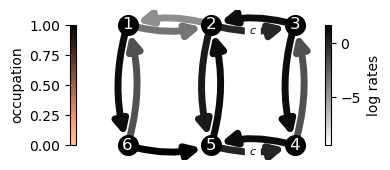

In [520]:
logrates = data[str(k)][str(kg)][str(kw)][:8]
# logrates = [-1.0515872,
#           -4.9898477,
#           -1.0515872,
#           0.69897,
#           0.2825698,
#           0.69897,
#           0.46107602,
#           -4.999996]
gamma = data[str(k)][str(kg)][str(kw)][-2]
w = data[str(k)][str(kg)][str(kw)][-1]
c = params["betas"][k-1]
edges2 = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                   (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1

logcw = np.log10(c) + np.log10(w)
kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
logrates2 = [kuoff+np.log10(gamma), kboff+logcw, kbon+logcw, kuon+np.log10(gamma), 
    konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]

we = np.array([(u,v,r) for ((u,v),r) in zip(edges2, logrates2)])
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges2, logrates2)])
we[0][2] += np.log10(c)
we[2][2] += np.log10(c)
minrate = min(logrates2)
maxrate = max(logrates2)

G = nx.Graph()
G.add_edges_from(edges2)
nodelist = G.nodes()
nodelabels = [2,5,3,4,1,6]

# Q = utils.build_mat(we_lin, ie, c)
# pss = ctmc.P_ss(Q)
# colors = [pss[i] for i in nodelist]
node_labels = dict(zip(range(6), nodelabels))

fig, ax, _ = plot.draw_circuit(we, ie, dims=(4,1.8), node_size=200, 
                               nodefsize=12,  colorbar=False, 
                               node_labels=node_labels, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8, vmin=0, vmax=1,
                               bottom_set=[5,1,3])
print("log c = ", np.log10(c))

ax.set_axis_off()
norm = Normalize(0,1)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
             ax=ax, label="occupation", location="left", shrink=0.8)

# cbar.set_ticks(ticks=[-8, -4, 0])
# cbar.set_ticks(ticks=[-2, -1, 0])
# ax.text(-0.64, -0.1, r"$c_0 = 100$", fontsize=11)
# ax.text(-0.2, -0.4, r"(c)", fontsize=16)

norm = Normalize(minrate, maxrate)
cbarr = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax, label="log rates", location="right", shrink=0.8)

# cbarr.set_ticks(ticks=[-4, -2, 0])

In [3095]:
[colors[node_labels[i]-1] for i in nodelist]

[0.35631814343380974,
 0.287275106885294,
 0.3563181434338078,
 4.400904630635307e-05,
 5.89046694427643e-07,
 4.4008154087750585e-05]

### maximizing $IR + \beta DR$

In [76]:
# dirname = '20241116/ir-dr-from-20241113/cmaes'
# dirname = '20241113/ir-dr'
# dirname = '20241004/full'
whichf = "full"
k, kg, kw = (20, 1, 1)
ginds, winds = [0], [0]
ylb, yub = None, None
xlb, xub = None, None
# xlb, xub = 2e-4, 7.5e-4
# ylb, yub = 5e-4, 15e-4
showlegend = False
showlines = False
showbound = True
legend_loc = 'center right'
ylab = r"$IR^*$"
xlab = r"$DR^*$"
fill = "full"

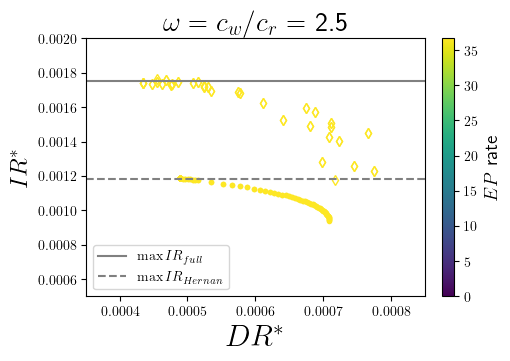

In [139]:
dirname = '20241125/ir-dr-hernan-p'
whichf = "acc"
k, kg, kw = (32, 3, 2)
ginds, winds = [2], [1]
xlb, xub = 3.5e-4, 8.5e-4
ylb, yub = 5e-4, 20e-4
# ylb, yub = None, None
# xlb, xub = None, None
showlines = False
showbound = False
msize=3
marker='o'
fill = "full"
fig, ax, _, _ = plot_pareto(None)

dirname = '20241120/ir-dr/g10-w2.5'
whichf = "full"
k, kg, kw = (32, 1, 1)
ginds, winds = [0], [0]
msize = 5
fill = "none"
fig, ax, _, _ = plot_pareto((fig, ax))
ax.axhline(y=0.00175, linestyle="solid", color="gray", label=r"$\max IR_{full}$")
ax.axhline(y=0.001185, linestyle="dashed", color="gray", label=r"$\max IR_{Hernan}$")
ax.legend(loc='lower left')

In [140]:
dirname = '/home/tohme/phd/flython/plots/20241126'

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/ir-dr-full-hernan.pdf')

### Comparing fake IR_full to IR_acc

Text(0, 0.5, '$IR^*$')

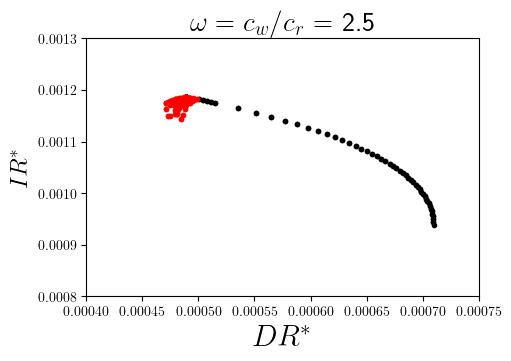

In [ ]:
# dirname = '20241125/ir-dr-hernan/coarse-sweep-1-alg=de-start=MGR-lg=global-whichf=simfull-maxiters=3000-sigma=3e-5-N=3000-nparams=1'
# dirname = '20241125/ir-dr-hernan/bigsweep-de-global-MGR-p-simfull-20k-fcalls-1-param-noise-2e-5-vhires'
# dirname = '20241125/ir-dr-hernan/bigsweep-cmaes-global-prevsim-p-simfull-4k-fcalls-1-param-noise-2.5e-6-hires'

# dirname = '20241125/ir-dr-hernan/coarse-sweep-1-alg=de-start=MGR-lg=global-whichf=simfull-maxiters=3000-sigma=3e-5-N=3000-nparams=1'
# dirname = '20241125/ir-dr-hernan/prevbeta-alg=cmaes-start=MGR-lg=global-whichf=simfull-maxiters=10-sigma=1e-5-N=1-nparams=1'
# dirname = '20241113/ir-dr'
dirname = '20241125/ir-dr-hernan-p'
whichf = "acc"
k, kg, kw = (20, 3, 2)
ginds, winds = [2], [1]
xlb, xub = 3.5e-4, 8.5e-4
ylb, yub = 5e-4, 20e-4
ylb, yub = None, None
xlb, xub = None, None
showlines = False
showbound = False
showlegend = False
msize=3
marker='o'
fill = "full"
fig, ax, _, _, figcirc = plot_pareto(None, False, color="black")
ax.set_title("")
ax.set_title("1000 out-of-bounds points around the IR-optimum", fontsize=12)
# ax.set_title("Subset of within-bounds points")

dirname = '20241123/test-point-cloud'
whichf = "full"
k, kg, kw = (1, 1, 1)
ginds, winds = [2], [0]
showlines = False
xlb, xub = 4e-4, 7.5e-4
ylb, yub = 8e-4, 13e-4
fig, ax, _, _, _ = plot_pareto((fig, ax), False, color="red")
# ax.set_title("CV = 0.13\%", fontsize=18)
ax.set_xlabel(r"$DR^*$")
ax.set_ylabel(r"$IR^*$")

In [228]:
import os
dirname = '/home/tohme/phd/flython/plots/20241127'

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/20241127/point-cloud-mgr-oob.pdf')
# figcirc.savefig('/home/tohme/phd/flython/plots/20241127/ir-dr-hernan-far-circuit.pdf')

### Special circuits

/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


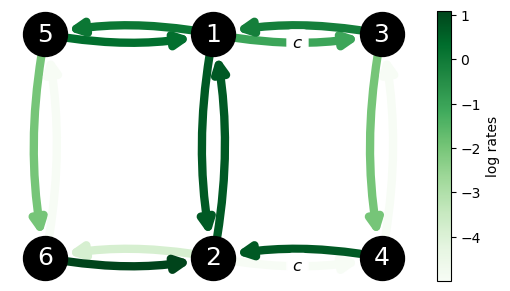

In [61]:
# circuit A
importlib.reload(plot)

edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
            (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
input = [(0,2), (1,3)]
on_ind = np.array([0,1,0,1,0,1])
idist = np.ones(6) / 6
logratesA = [1.2825698,
          0.09454083567823801,
          0.09454083567823801,
          1.46107602,
          -4.9898477,
          -1.0515872,
          -1.0515872,
          0.69897,
          0.2825698,
          0.69897,
          0.46107602,
          -4.999996,
          0.69897,
          -4.999996]
logratesB = [1.6989699,
            0.09454083567823801,
            -3.853808964321762,
            1.54783356,
            -4.989879,
            -1.0515872,
            -4.999937,
            0.69897,
            0.6989699,
            0.69896984,
            0.54783356,
            -4.9945397,
            0.69896984,
            -4.9945397]
logratesC = [0.2695346886720376,
            0.09453593567823804,
            -3.853656964321762,
            1.0969087786720375,
            0.6989517,
            -1.0515921,
            -4.999785,
            0.69896877,
            -0.12840532,
            -1.9895186,
            0.69896877,
            -4.9985023,
            -1.9895186,
            -4.9985023]

whichc = "C"

if whichc == "A":
    logrates = logratesA
if whichc == "B":
    logrates = logratesB
if whichc == "C":
    logrates = logratesC

we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])
we_lin = np.array([(u-1,v-1,10**r) for ((u,v),r) in zip(edges, logrates)])
Q = utils.build_mat(we_lin, input, c)
pss = ctmc.P_ss(Q)
node_color = [np.log(pss[int(i)]) for i in [0,1,2,3,4,5]]

node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

figA, axA, graphA = plot.draw_circuit(we, 
                    input_edges=input, 
                    bottom_set=[5,1,3],
                    node_size=1000,
                    input_labels = None,
                    node_labels=node_numbers,
                    node_color="black",
                    edge_cmap=plt.cm.Greens,
                    # title="Circuit {}".format(whichc),
                    dims=(5,2.8))

In [62]:
import os
dirname = '/home/tohme/phd/flython/plots/20241126'

if not os.path.exists(dirname):
    os.makedirs(dirname)

figA.savefig('{}/circuitC.pdf'.format(dirname))

## No activation

In [55]:
dirname = '20241011/full'
whichf = "full"
k, kg, kw = (15, 2, 1)
xlim, ylim = (3e-3, 3e-3)
node_color = ""

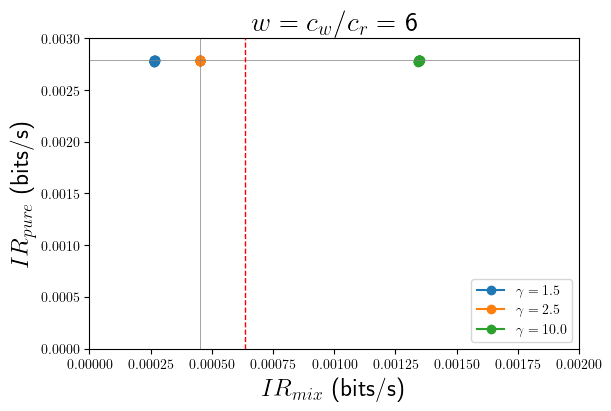

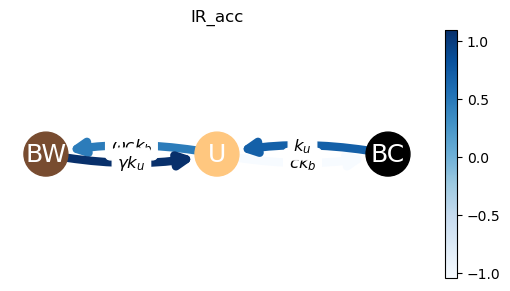

In [56]:
from matplotlib.lines import Line2D
import matplotlib.patches as mpatches
importlib.reload(plot)

path = '/home/tohme/.julia/dev/LLROpt/data/'
params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

data_acc = {}
data_acc_proc = {}
ncpus = params_acc["ncpus"]
nbetas = params_acc["nparams"]
betas = params_acc["betas"]
gammas = params_acc["gammas"]
wvals = params_acc["wvals"]
nparams_per_cpu = int(nbetas/ncpus)

winds = [kw-1]
g = gammas[kg-1]
w = wvals[kw-1]
cw = w*cr
x = cr/(cw+cr)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

for cpukey in range(1, ncpus + 1):
    data_acc_proc = json.load(open(path+'{}/ir_{}_mix_vs_pure_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

    for i in range(1, nparams_per_cpu+1):
        keyb = (cpukey - 1) * nparams_per_cpu + i
        data_acc[str(keyb)] = data_acc_proc[str(keyb)]

max_irpure = data_acc[str(1)][str(kg)][str(kw)][3]

plt.rcParams['text.usetex'] = True

fig, ax = plt.subplots(1,1, layout='constrained', figsize=(6,4))

colors = ['C{}'.format(i) for i in range(len(gammas))]

for (i, gamma) in enumerate(gammas):
    for j in winds:

        keyg = str(i+1)
        keyw = str(j+1)

        xopt = np.array([data_acc[str(k)][keyg][keyw][:2] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_mix = np.array([data_acc[str(k)][keyg][keyw][2] for k in np.arange(1, nbetas+1, 1)])
        ir_acc_pure = np.array([data_acc[str(k)][keyg][keyw][3] for k in np.arange(1, nbetas+1, 1)])

        ax.plot( ir_acc_mix, ir_acc_pure, color=colors[i], marker='o', linestyle='none', markersize=6)

        ax.set_ylabel(r"$IR_{pure}$ (bits/s)", fontsize=18)
        ax.set_xlabel(r"$IR_{mix}$ (bits/s)", fontsize=18)
        irvals = np.linspace(0, 2e-3, 50)

h1 = mpatches.Patch(color=colors[j])  
wlabels = list(zip(*[(mpatches.Patch(color=colors[j]), 'w = {}'.format(w)) for (j,w) in enumerate(wvals)]))
gammalabels = list(zip(*[(Line2D([0], [0], color=colors[i], marker='o'),r"$\gamma = {}$".format(round(g, 1))) for (i,g) in enumerate(gammas)]))
ax.legend(wlabels[0]+gammalabels[0], wlabels[1]+gammalabels[1], loc='lower right')
ax.legend(gammalabels[0], gammalabels[1], loc='lower right')
ax.set_ylim(0, 3e-3)
ax.set_xlim(0, 2e-3)
ax.axhline(y = data_acc[str(k)][str(kg)][str(kw)][3], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[str(k)][str(kg)][str(kw)][2], linewidth=0.5, color="gray")

ax.axvline(x = max_ir_mix, linewidth=1, color="red", linestyle="dashed")
# ax.axhline(y = ir_full_pure[k], linewidth=1, color="gray", linestyle="dashed")
# ax.axvline(x = ir_full_mix[k], linewidth=1, color="gray", linestyle="dashed")
_=ax.set_title(r"$w = c_w/c_r$ = {}".format(w), fontsize=20)
# ax.axvline(x=dcr_mle)

# plot circuit
importlib.reload(plot)

a = 3e-3        # um
D_tf = 7.4      # um^2/s
D_cplx = 0.1    # um^2/s
cr = 5.6         # um^-3
dc = 0.1 * cr
cw = w * cr
dl_tf = 4*a*D_tf
ub = 5
lb = 1e-5
max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

xopt_acc = data_acc[str(k)][str(kg)][str(kw)][:2]
kb, ku = xopt_acc
logrates2 = [kb, ku, kb+np.log10(cw), ku+np.log10(g)]

edges = [(0,1),(1,0),(0,2),(2,0)]
wedges_acc = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_acc_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])

iedges = [(0,1)]
on_ind = np.array([0,1,1])
Q = utils.build_mat(wedges_acc_lin, iedges, cr)
pss = ctmc.P_ss(Q)
pc = sum(pss[[0]])
kbl = 10**kb
kul = 10**ku

G = nx.DiGraph()
for u, v, w in wedges_acc_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]


node_labels = {0: r'U',
                1: r'BC',
                2: r'BW'}

input_labels = {(0,1):"$ck_b$",
                (0,2):"$\omega c k_b$",
                (1,0):"$k_u$",
                (2,0):"$\gamma k_u$"}

fig, ax, G = plot.draw_circuit(wedges_acc,
                            iedges, 
                            node_labels=node_labels, 
                            input_labels=input_labels,
                            bottom_set=[2,0,1],
                            node_size=1000,
                            node_color=node_color,
                            title="IR_acc",
                            dims=(5,2.8))

In [ ]:
path = '/home/tohme/.julia/dev/LLROpt/data/'
dirname = "20241118/test-point-cloud"
filename = "circuits"
data = json.load(open(path+'{}/{}.json'.format(dirname, filename)))

## Handcrafted circuits

In [23]:
dirname = '20241022/dr_limits/'
fname = "dr_max_full_noac.json"
k, kg, kw = (1, 3, 3)
xlim, ylim = (1e-3, 2.5e-3)
node_color = ""
acc = False

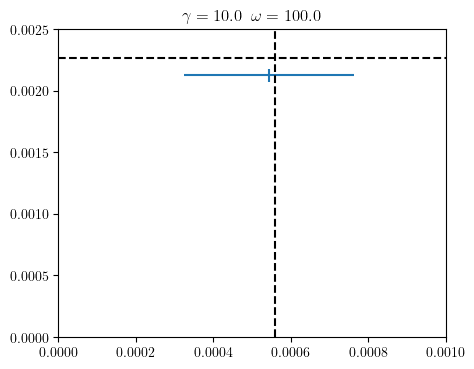

In [24]:
path = '/home/tohme/.julia/dev/LLROpt/data/'
data = json.load(open(path+dirname+fname))

logrates = data["1"][str(kg)][str(kw)][:-8]
irmix_mean = data["1"][str(kg)][str(kw)][-8]
irpure_mean = data["1"][str(kg)][str(kw)][-7]
irmix_stdev = data["1"][str(kg)][str(kw)][-6]
irpure_stdev = data["1"][str(kg)][str(kw)][-5]
g = data["1"][str(kg)][str(kw)][-2]
w = data["1"][str(kg)][str(kw)][-1]
cw = w*cr
x = cr / (cr+cw)

max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)
tau = (1/(1+w))*(1/(cr*dl_tf)+(1+w/g)/5)
max_ir_mix = 0.5 * (dc**2/(cr**2 + f(x,g)*(cr+cw)**2))/tau

plt.rcParams['text.usetex'] = True
fig, ax = plt.subplots(1,1,figsize=(5,4))

ax.errorbar(irmix_mean, irpure_mean, irpure_stdev, irmix_stdev)
ax.axhline(y=max_ir_full, linestyle="dashed", color="black")
ax.axvline(x=max_ir_mix, linestyle="dashed", color="black")
ax.set_xlim(0, xlim)
ax.set_ylim(0, ylim)
ax.set_title(r"$\gamma={}\;\; \omega={}$".format(g, round(w, 1)))

if acc:
    edges = [(4,0), (0,4), (1,5), (5,1), (0,1), (0,2), (1,3),
             (1,0), (2,0), (2,3), (3,1), (3,2), (4,5), (5,4)]
    iedges = [(0,2), (1,3)]
    on_ind = np.array([0,1,0,1,0,1])
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
else:
    edges = [(0,1),(1,0),(0,2),(2,0)]
    iedges = [(0,1)]
    on_ind = np.array([0,1,1])
    kb, ku = logrates
    logrates2 = [kb, ku, kb+np.log10(cw), ku+np.log10(g)]


wedges = [(u,v,w) for ((u,v), w) in zip(edges, logrates2)]
wedges_lin = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])
Q = utils.build_mat(wedges_lin, iedges, cr)
pss = ctmc.P_ss(Q)


G = nx.DiGraph()
for u, v, w in wedges_lin:
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)]) for i in G.nodes()]

if acc:

    node_labels = {0: r'FU',
                    1: r'NU',
                    2: r'FBR',
                    3: r'NBR',
                    4: r'FBW',
                    5: r'NBW'}

    node_numbers = {0: r'1',
                    1: r'2',
                    2: r'3',
                    3: r'4',
                    4: r'5',
                    5: r'6'}

    input_labels = {(0,4):"cw",
                    (0,2):"cr",
                    (1,5):"cw",
                    (1,3):"cr"}

else:
    node_labels = {0: r'U',
                    1: r'BC',
                    2: r'BW'}

    input_labels = {(0,1):"$ck_b$",
                    (0,2):"$\omega c k_b$",
                    (1,0):"$k_u$",
                    (2,0):"$\gamma k_u$"}

    # fig, ax, G = plot.draw_circuit(wedges_acc,
    #                             iedges, 
    #                             node_labels=node_labels, 
    #                             input_labels=input_labels,
    #                             bottom_set=[2,0,1],
    #                             node_size=1000,
    #                             node_color=node_color,
    #                             title="IR_acc",
    #                             dims=(5,2.8))

### Exploring optimal circuit statistics

In [485]:
k, kg, kw = (1,2,2)

In [427]:
pons = np.zeros(nbetas)
tbs = np.zeros(nbetas)
tons = np.zeros(nbetas)
toffs = np.zeros(nbetas)
sharps = np.zeros(nbetas)
vars = np.zeros(nbetas)
ir_mixs = np.zeros(nbetas)
lrspec = np.zeros(nbetas)
ir_pures = np.zeros(nbetas)
logrates_all = np.zeros((8, nbetas))
on_ind_pure = [0,1,0,1]
edges_pure = [(0,2),(0,1),(1,3),(1,0),(2,0),(2,3),(3,1),(3,2)]
g = gammas[kg-1]
w = wvals[kw-1]

for k, beta in enumerate(betas):
    logrates = data_acc[str(k+1)][str(kg)][str(kw)][:8]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(g), kboff+np.log10(cw), kbon+np.log10(cw), kuon+np.log10(g), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
    wedges_acc = np.array([(u,v,10**w) for ((u,v), w) in zip(edges_pure, logrates)])
    wedges_acc2 = np.array([(u,v,10**w) for ((u,v), w) in zip(edges, logrates2)])
    Q = utils.build_mat(wedges_acc2, iedges, cr)
    pss = ctmc.P_ss(Q)
    pons[k] = ctmc.pi_on(wedges_acc2, iedges, cr, on_ind)
    lrspec[k] = np.log2((pss[3])/(pss[5]))
    ton, toff = ctmc.mean_fpt_part(wedges_acc2, iedges, cr, on_ind)
    tbs[k] = ton+toff
    tons[k] = ton
    toffs[k] = toff
    sharps[k] = ctmc.sharpness(wedges_acc2, iedges, cr, on_ind)
    ir_mixs[k] = ctmc.ir_acc(wedges_acc2, iedges, cr, dc, on_ind)
    ir_pures[k] = ctmc.ir_acc(wedges_acc, iedges, cr, dc, on_ind_pure)
    vars[k] = ctmc.var(wedges_acc2, iedges, cr, on_ind)
    logrates_all[:,k] = logrates

fig, ax = plt.subplots(1,1, figsize=(6,3.5))

# axr = ax.twinx()

# ax.plot(betas, ir_mixs)
# ax.plot(betas, ir_pures)
# ax.plot(betas, sharps)
# ax.plot(betas, lrspec)
# ax.plot(betas, tbs)
# ax.plot(betas, tons)
# ax.plot(betas, toffs)

ax.plot(betas, logrates_all[0,:], label="kboff")
ax.plot(betas, logrates_all[1,:], label="konu")
ax.plot(betas, logrates_all[2,:], label="kbon")   #
ax.plot(betas, logrates_all[3,:], label="koffu")  #
ax.plot(betas, logrates_all[4,:], label="kuoff")  #
ax.plot(betas, logrates_all[5,:], label="konb")
ax.plot(betas, logrates_all[6,:], label="kuon")
ax.plot(betas, logrates_all[7,:], label="koffb")  #

# axr.plot(betas, pons, color='C3')
# axr.plot(betas, vars, color='C4')
ax.axhline(y=np.log2(g/w), linestyle='dashed')

ax.set_xscale('log')
# axr.set_ylabel(r"$p_{ON}$", fontsize=16)
# ax.set_ylabel(r"$\tau_{B}$", fontsize=16)
ax.set_xlabel(r"$\beta$", fontsize=16)
ax.legend(loc='lower center', fontsize=8)

NameError: name 'nbetas' is not defined

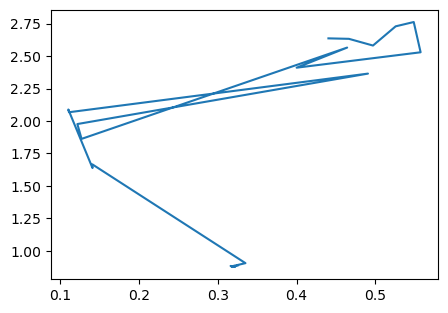

In [635]:
fig, ax = plt.subplots(1,1, figsize=(5,3.5))

ax.plot(pons, tbs)

# Multiple binding sites

## 2 binding sites

(<Figure size 500x280 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x70d4900192d0>)

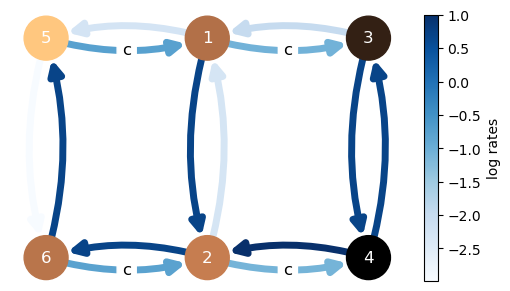

In [1093]:
edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                  (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1    

kboff = -1.0613204
konu = -2.98726
kbon = -1.0868188
koffu = 0.7
kuoff = -2.276372
kon1b = 0.7
kuon = 0.7
koff1b = -2.2888334 
kon2b = 0.7
koff2b = 0.7
logrates = [kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b]
# logrates = np.zeros(10)

# logrates = [-1.0515876,
#               -3,
#               -1.0515876,
#               0.69896996,
#               -2.9974964,
#               0.69896996,
#               0.6989698,
#               -2.9998689,
#               0.69896996,
#               -2.9999237]

kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
iedges = [(0,2), (1,3), (4,0), (5,1)]
on_ind = np.concatenate((np.zeros(3), np.ones(3)))
node_labels = dict(zip(range(6), range(1,7)))
# node_color = [0] * 6
# node_color[0] = 1
input_labels = dict(zip(iedges, ['c']*4))
bottom_set = [5,1,3]
node_size=1000

G = nx.DiGraph()
for u, v, w in wedges_lin:
    # print("edge: ({},{})".format(u, v), "weight: {}".format(w))
    G.add_edge(u, v, weight=w)

Q = utils.build_mat(wedges_lin, iedges, cr)
pss = ctmc.P_ss(Q)
node_color = [np.log(pss[int(i)]) for i in G.nodes()]

plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color=node_color,
                  dims=(5,2.8))

In [346]:
import matplotlib.pyplot as plt

def plot_ir_ep(figax, color="black", label="", ncpus=16, nparams_per_cpu=1, k_=1):
    a = 3e-3        # um
    D_tf = 7.4      # um^2/s
    cr = 5.6         # um^-3
    dc = 0.1 * cr
    dl_tf = 4*a*D_tf
    ub = 5
    max_ir_full = 0.5 * (dc/cr)**2 * (cr*dl_tf*ub)/(cr*dl_tf + ub)

    irkey = nedges
    data_full = {}
    data_acc = {}
    data_acc_proc = {}
    betakeys = np.arange(1, ncpus+1)

    for cpukey in range(1, ncpus+1):
        if cpukey not in skipkeys:
            # data_full_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_vs_ep_pareto_4s_beta{}.json'.format(dirname, cpukey)))
            # data_acc_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_acc_vs_ep_pareto_4s_beta{}.json'.format(dirname, cpukey)))
            data_full_proc = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

            for k in range(1, nparams_per_cpu+1):
                betakey = (cpukey - 1)*nparams_per_cpu + k
                if betakey not in skipkeys:
                    data_full[betakey] = data_full_proc[str(betakey)]

    irvals_full = [data_full[i][irkey] for i in betakeys if i not in skipkeys]
    epvals_full = [data_full[i][irkey+1] for i in betakeys if i not in skipkeys]

    if whichf == "full":
        irvals_full_std = [data_full[i][irkey+2] for i in betakeys if i not in skipkeys]

    plt.rcParams['text.usetex'] = True

    if figax == None:
        fig, ax = plt.subplots(1,1, layout='constrained', figsize=(4.5,3))
    else:
        fig, ax = figax

    ax.axhline(y=irvals_full[k_], color="gray", linewidth=0.5)
    ax.axvline(x=epvals_full[k_], color="gray", linewidth=0.5)

    ax.errorbar(epvals_full, irvals_full,  marker='o', linestyle='none', capsize=2, color=color, label=label)
    ax.set_ylabel(r"$\langle T \rangle^*$", fontsize=18)
    ax.set_xlabel(r"$EP^*$", fontsize=18)
    ax.set_title("Decision error = 0.37")

    logrates = data_full[k_][:irkey]
    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

    weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                 koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

    edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                      (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1

    wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
    wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
    iedges = [(0,2), (1,3), (4,0), (5,1)]
    on_ind = np.concatenate((np.zeros(3), np.ones(3)))
    node_labels = dict(zip(range(6), range(1,7)))
    # node_color = [0] * 6
    # node_color[0] = 1
    input_labels = dict(zip(iedges, ['c']*4))
    bottom_set = [5,1,3]
    node_size=1000

    Q = utils.build_mat(wedges_lin, iedges, cr)
    pss = ctmc.P_ss(Q)

    G = nx.DiGraph()
    for u, v, w in wedges:
        G.add_edge(u, v, weight=w)

    # node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]
    node_color = np.zeros(6)
    node_color[0] = 1

    plot.draw_circuit(wedges, 
                    iedges, 
                    node_labels=node_labels, 
                    input_labels=input_labels,
                    bottom_set=bottom_set,
                    node_size=node_size,
                    node_color=node_color,
                    #   title="2 binding sites",
                    dims=(5,2.8))

    return fig, ax, data_full #, figcirc

In [572]:
def plot_data(figax=None, color="black", figsize=None):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data_acc = {}
    data_acc_proc = {}
    ncpus = params_acc["ncpus"]
    nbetas = params_acc["nparams"]
    betas = params_acc["betas"]
    nparams_per_cpu = int(nbetas/ncpus)

    for cpukey in range(1, ncpus + 1):
        data_acc_proc = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data_acc[keyb] = data_acc_proc[str(keyb)]

    irvals = [data_acc[i][nedges] for i in range(1, nbetas+1)]
    epvals = [data_acc[i][nedges+1] for i in range(1, nbetas+1)]

    if figax is None:
        figplot, ax = plt.subplots(1,1, layout='constrained', figsize=figsize)
    else:
        figplot, ax = figax

    ax.errorbar(epvals, irvals,  marker='o', linestyle='none', capsize=2, color=color, markersize=msize)

    if showlines:
        ax.axhline(y=irvals[k-1], color="gray", linewidth=0.5)
        ax.axvline(x=epvals[k-1], color="gray", linewidth=0.5)

    return figplot, ax, data_acc

def plot_circuit_2bs(k=1, node_color=None, input_labels=None):
    paramfile = "params"
    path = '/home/tohme/.julia/dev/LLROpt/data/'
    params_acc = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data_acc = {}
    data_acc_proc = {}
    ncpus = params_acc["ncpus"]
    nbetas = params_acc["nparams"]
    betas = params_acc["betas"]
    nparams_per_cpu = int(nbetas/ncpus)

    for cpukey in range(1, ncpus + 1):
        data_acc_proc = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname, whichf, cpukey)))

        for i in range(1, nparams_per_cpu+1):
            keyb = (cpukey - 1) * nparams_per_cpu + i
            data_acc[keyb] = data_acc_proc[str(keyb)]

    logrates = data_acc[k][:nedges]
    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

    weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                 koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

    edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                      (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1

    wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
    wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
    iedges = [(0,2), (1,3), (4,0), (5,1)]
    on_ind = np.concatenate((np.zeros(3), np.ones(3)))
    # node_labels = dict(zip(range(6), range(1,7)))
    # node_color = [0] * 6
    # node_color[0] = 1
    if input_labels is None:
        input_labels = dict(zip(iedges, ['c']*4))
    bottom_set = [5,1,3]
    node_size=1000

    Q = utils.build_mat(wedges_lin, iedges, cr)
    pss = ctmc.P_ss(Q)

    # node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]
    # node_color = np.zeros(6)

    _, _, H = plot.draw_circuit(wedges, 
                    iedges, 
                    node_labels=node_labels, 
                    input_labels=input_labels,
                    bottom_set=bottom_set,
                    node_size=node_size,
                    node_color=node_color,
                    dims=(5,2.8))

    return H

In [1348]:
k = 37
which = "full"

(<Figure size 500x280 with 2 Axes>,
 <Axes: >,
 <networkx.classes.digraph.DiGraph at 0x70d4730892d0>)

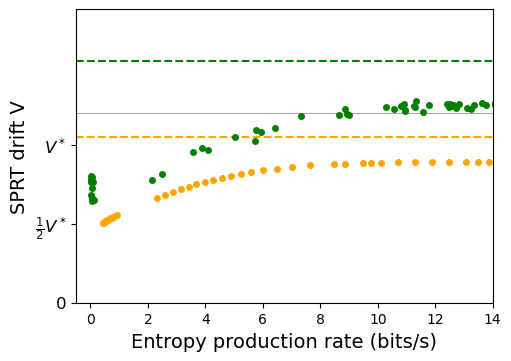

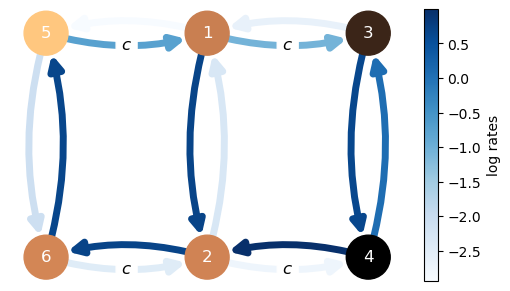

In [1354]:
# dirname = '20241130/2bs-ir-ep/test'
dirname = '20241203/2bs-ir-ep/test-forcing-konu-de'
# dirname = '20241202/2bs-ir-ep/test-forcing-5-6-de'

plt.rcParams["text.usetex"] = False
nedges = 10
showlines = True if which == "acc" else False
# showlines = False
whichf = "acc"
msize=4
fig, ax, data_acc = plot_data(None, "orange", (5,3.5))
ax.set_title("")
ax.axhline(y=2*0.00173, linestyle="dashed", color="green")
ax.axhline(y=2*0.001185, linestyle="dashed", color="orange")
ax.set_ylabel("SPRT drift V", fontsize=14)
ax.set_xlabel("Entropy production rate (bits/s)", fontsize=14)
ax.set_ylim(0,42e-4)
ax.set_xlim(-0.5, 14)
ax.set_yticks([0,D_full2b/2,D_full2b])
ax.set_yticklabels([0, r"$\frac{1}{2}V^*$", r"$V^*$"], fontsize=12)
# ax.set_xscale('log')

# ax.text(0.5,3.3e-3,"Lower dissipation", fontsize=10)
# ax.text(2,3.6e-3,r"$\beta \gg 1$", fontsize=10)
# ax.text(9.6,3.3e-3,"Faster decisions", fontsize=10)
# ax.text(11,3.6e-3,r"$\beta = 0$", fontsize=10)
x = np.linspace(-0.5, 14, 100)
y = np.linspace(0, 1, 100)
X, Y = np.meshgrid(x, y)
Z = X + Y  # This will create a simple gradient effect
# ax.imshow(Z, extent=[-0.5, 14, 0, 1], origin='lower', aspect='auto', cmap='coolwarm', alpha=0.2)

dirname = '20241203/2bs-ir-ep/'
whichf = "full"
showlines = True if which == "full" else False
# showlines = False
fig, ax, data_full = plot_data((fig,ax), "green")

logrates = data_acc[k][:10] if which == "acc" else data_full[k][:10]
kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates
e = (0,1)
input_labels = None
# input_labels= {e:'pimp'}
cr = 5.6
# dirname = '20241203/2bs-ir-ep/test-forcing-konu-de'
dirname = '20241203/2bs-ir-ep/' if which == "full" else '20241203/2bs-ir-ep/test-forcing-konu-de'
whichf = which

weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])
G = nx.DiGraph()
for u, v, w in wedges_lin:
    # print("edge: ({},{})".format(u, v), "weight: {}".format(w))
    G.add_edge(u, v, weight=w)

Q = utils.build_mat(wedges_lin, iedges, cr)
pss = ctmc.P_ss(Q)
node_color = [np.log(pss[int(i)]) for i in G.nodes()]

plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color=node_color,
                  dims=(5,2.8))

In [1098]:
date = 20241210
dirname = '/home/tohme/phd/flython/plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('/home/tohme/phd/flython/plots/{}/ir-ep-with-opt-circuits.pdf'.format(date))

### Clustering based on transition rates

In [1309]:
X = np.array([data_full[i][:10] for i in range(1,61)])

rates_embedded = TSNE(n_components=2, learning_rate='auto',
                    init='random', perplexity=10).fit_transform(X)

hdb_2bs_rates = HDBSCAN()
hdb_2bs_rates.fit(rates_embedded)

HDBSCAN()

label: 0


/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/networkx/drawing/nx_pylab.py:450: UserWarning: No data for colormapping provided via 'c'. Parameters 'cmap' will be ignored
  node_collection = ax.scatter(


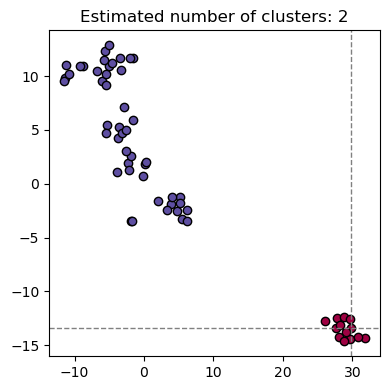

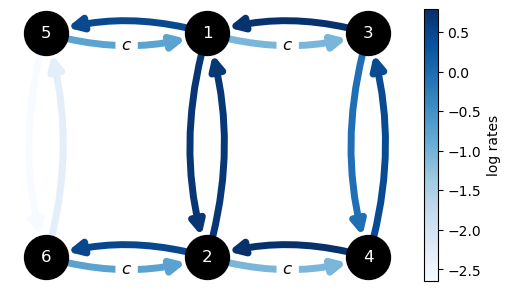

In [1310]:
key = 3
print("label:", hdb_2bs_rates.labels_[key])

ax = plot_clusters(rates_embedded, hdb_2bs_rates.labels_)
ax.axvline(x=rates_embedded[key][0], linestyle="dashed", color="gray", lw=1)
ax.axhline(y=rates_embedded[key][1], linestyle="dashed", color="gray", lw=1)

kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = X[key]
weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
_ = plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color="black",
                  dims=(5,2.8))

In [1311]:
hdb_2bs_rates.labels_

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

### Clustering based on occupation probabilities

In [1312]:
probs = np.zeros((60,6))

for key in range(60):
    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = X[key]
    weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                    koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]

    wedges_lin = np.array([(u,v,10**w) for ((u,v),w) in zip(edges, weights)])

    Q = utils.build_mat(wedges_lin, iedges, cr)
    pss = ctmc.P_ss(Q)
    probs[key] = [np.log(pss[int(i)]) for i in G.nodes()]

In [1313]:
probs_embedded = TSNE(n_components=2, learning_rate='auto',
                    init='random', perplexity=5).fit_transform(probs)

hdb_2bs_probs = HDBSCAN()
hdb_2bs_probs.fit(probs_embedded)

HDBSCAN()

label: 1


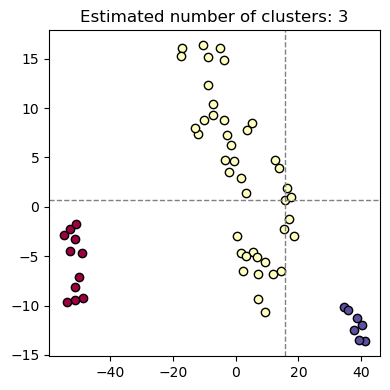

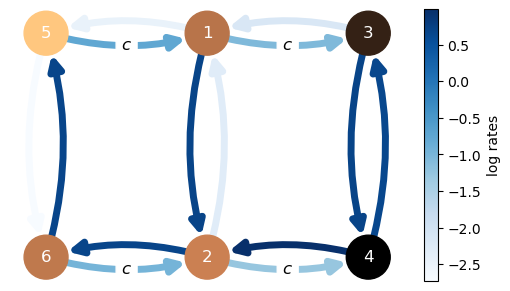

In [1323]:
key = -6
print("label:", hdb_2bs_probs.labels_[key])

ax = plot_clusters(probs_embedded, hdb_2bs_probs.labels_)
ax.axvline(x=probs_embedded[key][0], linestyle="dashed", color="gray", lw=1)
ax.axhline(y=probs_embedded[key][1], linestyle="dashed", color="gray", lw=1)

kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = X[key]
weights = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon, 
                koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
_ = plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color=probs[key],
                  dims=(5,2.8))

In [1291]:
hdb_2bs_probs.labels_

array([0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 1, 2, 1, 1, 1, 2, 1,
       1, 1, 2, 1, 2, 2, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1])

## 6 binding sites

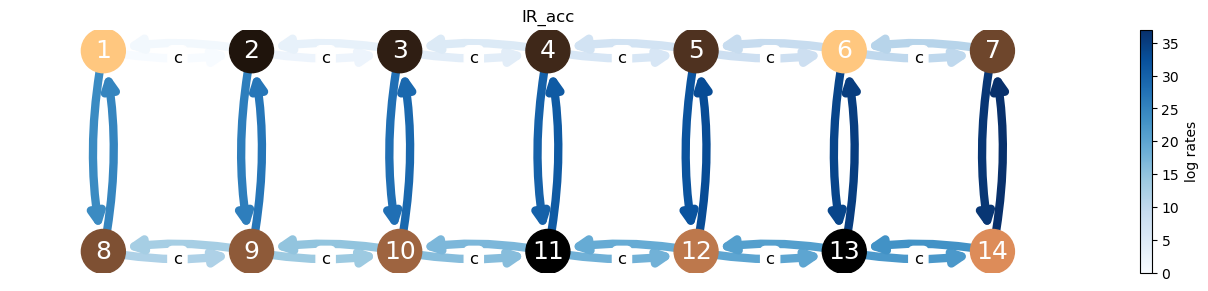

(<Figure size 1200x280 with 2 Axes>,
 <Axes: title={'center': 'IR_acc'}>,
 <networkx.classes.digraph.DiGraph at 0x7c9d28a15850>)

In [316]:
import networkx as nx
importlib.reload(plot)

edges = [(1 ,2 ), (2 ,1 ),
         (2 ,3 ), (3 ,2 ),
         (3 ,4 ), (4 ,3 ),
         (4 ,5 ), (5 ,4 ),
         (5 ,6 ), (6 ,5 ),
         (6 ,7 ), (7 ,6 ),
         (8 ,9 ), (9 ,8 ),
         (9 ,10), (10,9 ),
         (10,11), (11,10),
         (11,12), (12,11),
         (12,13), (13,12),
         (13,14), (14,13),
         (1 ,8 ), (8 ,1 ),
         (2 ,9 ), (9 ,2 ),
         (3 ,10), (10,3 ),
         (4 ,11), (11,4 ),
         (5 ,12), (12,5 ),
         (6 ,13), (13,6 ),
         (7 ,14), (14,7 )]

weights = np.arange(len(edges))
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])
iedges = [(i,i+1) for i in range(1,14) if i != 7]
on_ind = np.concatenate((np.zeros(7), np.ones(7)))
node_labels = dict(zip(range(1,15), range(1,15)))
node_color = [20,2,3,4,5,20,7,8,9,10,0,12,0,14]
input_labels = dict(zip(iedges, ['c']*14))
bottom_set = range(8,15)
node_size=1000

plot.draw_circuit(wedges, 
                  iedges, 
                  node_labels=node_labels, 
                  input_labels=input_labels,
                  bottom_set=bottom_set,
                  node_size=node_size,
                  node_color=node_color,
                  title="IR_acc",
                  dims=(12,2.8))

In [317]:
kb = 3
dirname1 = '20241002/6bs'
node_color=""
which_ir = "acc"

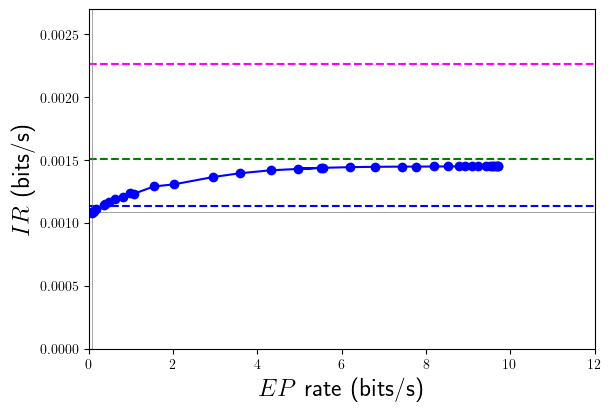

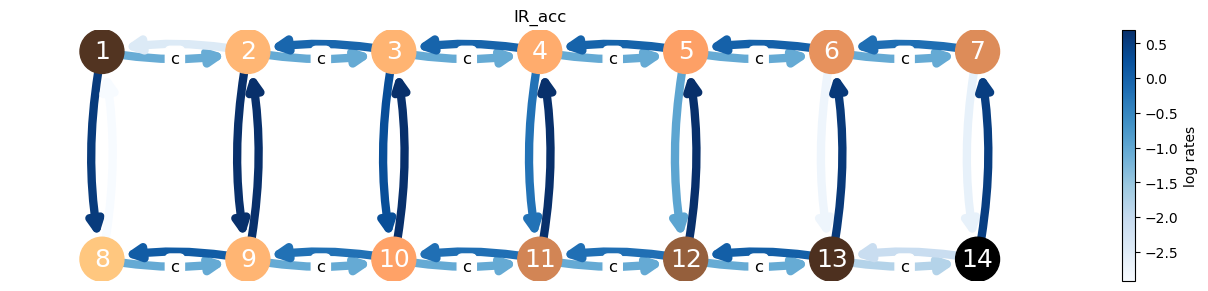

In [319]:
import matplotlib.pyplot as plt
importlib.reload(plot)

########## 6 bs

params_acc1 = json.load(open(path+'{}/params.json'.format(dirname1)))
data_acc = {}
data_acc_proc1 = {}
ncpus = params_acc1["ncpus"]
nparams = params_acc1["nparams"]
betakeys = np.arange(1, nparams+1)
nparams_per_cpu = int(nparams/ncpus)

for cpukey in range(1, ncpus+1):
    data_acc_proc1 = json.load(open(path+'{}/ir_{}_vs_ep_pareto_pid{}.json'.format(dirname1, which_ir, cpukey)))

    for k in range(1, nparams_per_cpu+1):
        betakey = (cpukey - 1)*nparams_per_cpu + k
        data_acc[betakey] = data_acc_proc1[str(betakey)]

nvals = len(data_acc.keys())
irvals_acc1 = [data_acc[i][-2] for i in betakeys]
# irstdev_acc1 = [data_acc[i][-1] for i in betakeys]
epvals_acc1 = [data_acc[i][-1] for i in betakeys]

plt.rcParams['text.usetex'] = True

fig1, ax = plt.subplots(1,1, layout='constrained', figsize=(6,4))

ax.errorbar(epvals_acc1, irvals_acc1, linestyle='solid',marker='o', color='blue')
# ax.plot(epvals_acc2, irvals_acc2, marker='o', color='green')
ax.axhline(y=0.0022614, color='magenta', linestyle='dashed')
ax.axhline(y=0.0022614/2, color='blue', linestyle='dashed')
ax.axhline(y=0.0022614*2/3, color='green', linestyle='dashed')
ax.axhline(y = data_acc[kb][-2], linewidth=0.5, color="gray")
ax.axvline(x = data_acc[kb][-1], linewidth=0.5, color="gray")
ax.set_ylim(0,0.0027)
ax.set_xlim(0, 12)
ax.set_ylabel(r"$IR$ (bits/s)", fontsize=18)
ax.set_xlabel(r"$EP$ rate (bits/s)", fontsize=18)

weights = np.array(data_acc[kb][:len(edges)])
wedges = np.array([(u,v,w) for ((u,v),w) in zip(edges, weights)])

wedges_lin = np.array([(u-1,v-1,10**w) for ((u,v),w) in zip(edges, weights)])
iedges_py = [(u-1,v-1) for (u,v) in iedges]
Q = utils.build_mat(wedges_lin, iedges_py, cr)
pss = ctmc.P_ss(Q)

G = nx.DiGraph()
for u, v, w in wedges:
    # print("edge: ({},{})".format(u, v), "weight: {}".format(w))
    G.add_edge(u, v, weight=w)

if node_color != "black":
    node_color = [np.log(pss[int(i)-1]) for i in G.nodes()]

fig2, ax, _ = plot.draw_circuit(
    wedges, 
    iedges,
    node_labels=node_labels, 
    input_labels=input_labels,
    bottom_set=bottom_set,
    node_size=node_size,
    node_color=node_color,
    title="IR_acc",
    dims=(12,2.8)
)

In [497]:
fig1.savefig('plots/6bs_irfull_ir_vs_ep_not_converging_20241005.pdf')
fig2.savefig('plots/6bs_circuit_not_converged.pdf')

# Better estimator for V

### Testing estimators with a real Gaussian process

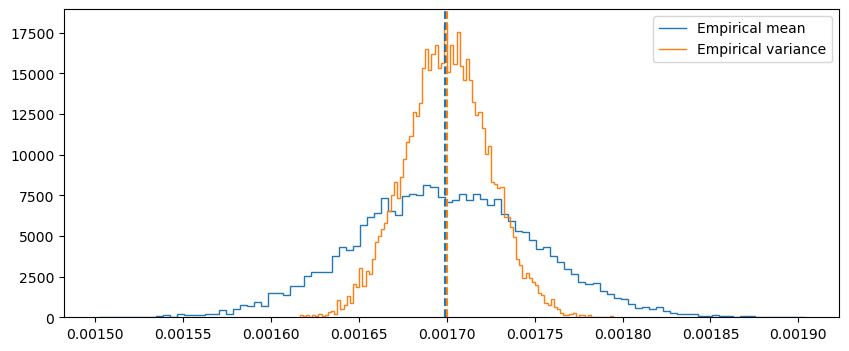

In [107]:
date = 20240822
data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/empirical_mean_estimator.json'.format(date)))
data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/empirical_variance_estimator.json'.format(date)))
# data3 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/20240809/maximum_likelihood_estimator.json'))

fig, ax = plt.subplots(1,1, figsize=(10,4))

h1, edges1 = np.histogram(data1, bins=100, density=True)
h2, edges2 = np.histogram(data2, bins=100, density=True)
# h3, edges3 = np.histogram(data3, bins=30, density=True)

ax.stairs(h1, edges1, label='Empirical mean')
ax.stairs(h2, edges2, label='Empirical variance')
# ax.stairs(h3, edges3, label='MLE given V=D')

ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
ax.axvline(x=np.mean(data2), linestyle='dashed', color='C1')
# ax.axvline(x=np.mean(data3), linestyle='dashed', color='C2')
# ax.set_xlim(80, 120)

ax.legend()

In [151]:
fig.savefig('plots/estimators_comparison_20240809.pdf')

### How gaussian are LLR increments?

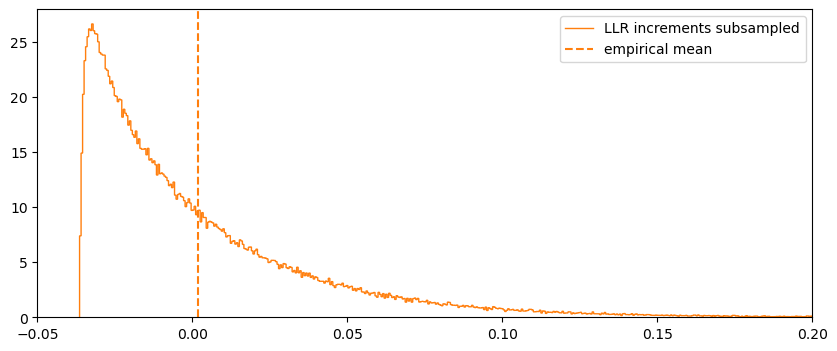

In [5]:
date = 20240822
# data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/llr_incrs.json'.format(date)))
data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/llr_incrs_sub.json'.format(date)))

c = 5.6
kb = 0.0888
kon = 5
ku = 5
koff = 5
n = 10000000
k = 5000000
dt = (1/(c*kb) + 1/kon + 1/ku + 1/koff) * (n/k) / 2
V = 0.0017
sigma = np.sqrt(2*V*dt)
xvals = np.linspace(V*dt-4*sigma, V*dt+4*sigma, 1000)

fig, ax = plt.subplots(1,1, figsize=(10,4))

# h1, edges1 = np.histogram(data1, bins=100, density=True)
h2, edges2 = np.histogram(np.array(data2)/dt, bins=1000, density=True)

# ax.stairs(h1, edges1, label='LLR increments', color='C0')
ax.stairs(h2, edges2, label='LLR increments subsampled', color='C1')

# ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
ax.axvline(x=np.mean(data2)/dt, linestyle='dashed', color='C1', label="empirical mean")

norm = np.exp(-(xvals - V*dt)**2/(2*sigma**2)) / np.sqrt(2*np.pi*sigma**2)
# ax.plot(xvals/dt, norm, color='C2')
# ax.axvline(x=V*dt, linestyle='dashed', color='C2', label="true mean")
ax.set_xlim(-0.05, 0.2)
ax.legend()

In [18]:
print("empirical D:", np.var(data2)/(2*dt))
print("empirical V:", np.mean(data2)/dt)

empirical D: 0.0018980577150951967
empirical V: 0.0017631688717462905


### Testing mean and var estimators with our LLR process

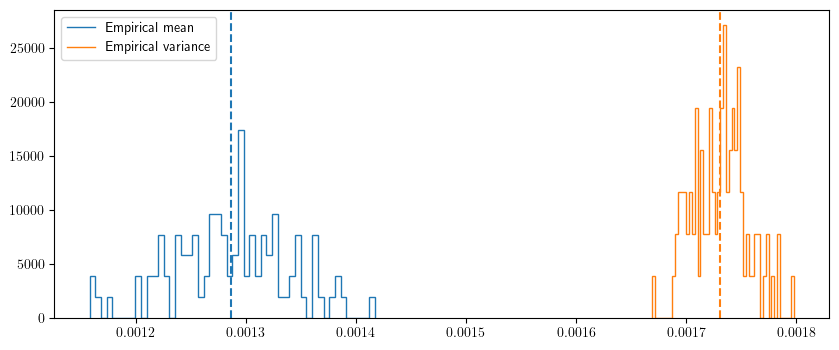

In [91]:
# date = 20241103
# date = 20241111
date = 20241125
data1 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_mean_estimator.json'.format(date)))
# data2 = json.load(open('/home/tohme/.julia/dev/LLROpt/data/{}/ir_full_variance_estimator.json'.format(date)))

fig, ax = plt.subplots(1,1, figsize=(10,4))

h1, edges1 = np.histogram(data1, bins=50, density=True)
# h2, edges2 = np.histogram(data2, bins=50, density=True)

ax.stairs(h1, edges1, label='Empirical mean')
# ax.stairs(h2, edges2, label='Empirical variance')

ax.axvline(x=np.mean(data1), linestyle='dashed', color='C0')
# ax.axvline(x=np.mean(data2), linestyle='dashed', color='C1')

ax.legend()

In [184]:
dirname = 'plots/{}'.format(date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig(dirname+'/ir_full_mean_and_variance_estimators_subsamp_5.pdf')

### Testing V=D and decision-time distribution

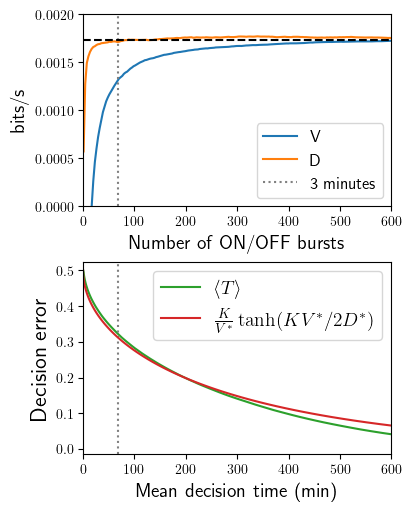

In [294]:
dirname = "20241103/"
# dirname = "20241102/max_iracc_circuit/" 
# dirname = "20241102/max_IR_equilibrium_circuit/"
path = '/home/tohme/.julia/dev/LLROpt/data/'
data1 = json.load(open(path+'{}ir_full_samples.json'.format(dirname)))
data2 = json.load(open(path+'{}stop_times_llr.json'.format(dirname)))
data3 = json.load(open(path+'{}stop_times_gp.json'.format(dirname)))

n = 5000
ntimes = len(data1)
nruns = len(data1[0])
nerrs = len(data2)

c = 5.6
kb = 0.0888
kon = 5
ku = 5
koff = 5
taub = (1/(c*kb) + 1/kon + 1/ku + 1/koff)
times = np.linspace(taub, n*taub/8, ntimes)
errs = np.linspace(0.5, 1e-2, nerrs)

V = np.mean(np.array(data1), axis=1)
D = np.var(np.array(data1) * np.sqrt(times)[:,None], axis=1) / 2

plt.rcParams['text.usetex'] = True
fig, ax = plt.subplots(2,1, figsize=(4,5), layout="constrained")

ax[0].plot(times/taub, V, label="V")
ax[0].plot(times/taub, D, label="D")
ax[0].set_ylim(0, 0.002)
ax[0].set_xlim(0, 600)
ax[0].axvline(x=180/taub, linestyle="dotted", color="gray", label="3 minutes")
ax[0].axhline(y=0.001728, linestyle="dashed", color="black")
ax[0].set_xlabel("Number of ON/OFF bursts", fontsize=14)
ax[0].set_ylabel(r"bits/s", fontsize=14)
ax[0].legend(fontsize=12)

mean_stoptimes = np.mean(np.array(data2), axis=1)
Ks = np.log((1-errs)/errs)

ax[1].plot(mean_stoptimes/taub, errs, label=r"$\langle T \rangle$", color="C2")
ax[1].set_xlabel("Mean decision time (min)", fontsize=14)
ax[1].set_ylabel("Decision error", fontsize=16)
ax[1].set_xlim(0, 600)
ax[1].axvline(x=180/taub, linestyle="dotted", color="gray")
key = 21
ax[1].plot(Ks * np.tanh(Ks*V[key]/(2*D[key]))/(V[key]*taub), 
           errs, label="$\\frac{K}{V^*}\\tanh(KV^*/2D^*)$", color="C3")
ax[1].legend(fontsize=14)

In [19]:
import os

path = 'plots/'+dirname
if not os.path.exists(path):
    os.makedirs(path)

fig.savefig('plots/{}V_and_D_pre_asymptotics.pdf'.format(dirname))

(0.0, 40.0)

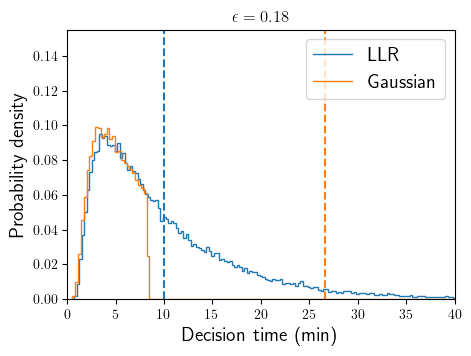

In [306]:
fig, ax = plt.subplots(1,1, figsize=(5,3.5))

ierrs = [65]
# ax.set_title("Decision time density")
ax.set_xlabel("Decision time (min)", fontsize=14)
ax.set_ylabel("Probability density", fontsize=14)

for (i, ierr) in enumerate(ierrs):
    ax.set_title(r"$\epsilon = {}$".format(round(errs[ierr],2)))
    h1, edges1 = np.histogram(np.array(data2[ierr])/60, bins=200, density=True)
    h2, edges2 = np.histogram(np.array(data3[ierr])/60, bins=200, density=True)

    ax.stairs(h1, edges1, label="LLR")
    ax.stairs(h2, edges2, label="Gaussian")

    ax.axvline(x=np.mean(data2[ierr])/60, linestyle='dashed', color="C{}".format(i))
    ax.axvline(x=np.mean(data3[ierr])/60, linestyle='dashed', color="C{}".format(i+1))

r,l = ax.get_xlim()
ax.set_xlim(r/3, l/4)
ax.legend(fontsize=14)
ax.set_xlim(0, 40)

In [116]:
print("<T>_LLR / <T>_GP - 1 ~", (np.mean(data2[ierr])/np.mean(data3[ierr]) - 1) * 100, "%")

<T>_LLR / <T>_GP - 1 ~ 11.927870349568614 %


Text(0, 0.5, 'ET')

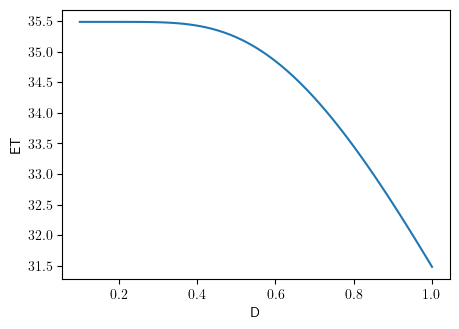

In [155]:
# fig, ax = plt.subplots(subplot_kw={"projection": "3d"})

K = 10
vs = np.linspace(0.1, 1, 100)
ds = np.linspace(0.1, 1, 100)
x, y = np.meshgrid(vs, ds)
z = (K / x) * np.tanh(K*x/(2*y))
# ax.plot_surface(x, y, z)
# ax.set_xlabel("V")
# ax.set_ylabel("D")

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

vx = vs[20]
c = 1
# vx = ds * c
ax.plot(ds, (K / vx) * np.tanh(K*vx/(2*ds)))
ax.set_xlabel("D")
ax.set_ylabel("ET")

### Improving decision-time statistics

In [ ]:
# extract multiple decision events from a single fixed-time trajectory

### RMC estimator (importance sampling)

state of affairs as of 20240927:
- RMC code is wrong (doesn't agree with old code's estimate)
- about 8x slower
- uses 3x as much memory

wrong: 
it's not calculating the same thing. i'm using RS as matrices, assuming the traj starts in the same partition, there's plenty of room for bugs.

slow:
seems to be a problem with get_residence_time and generate. the ll code seems to be fast.

memory:
fine-tuning.

Léo Regnier: use a score that adds more weight to the trajectories that contribute the most variance to your estimator. This may be different than RMC if you're only interested in the first moment. you need to make sure your resampling obeys detailed balance - ergodicity

### Analytical expression for MLE variance for OFF observations

In [1823]:
import numpy as np
from scipy.optimize import root
from scipy.special import zeta
import matplotlib.pyplot as plt

def est_eq(c, t, kb, kon):
    """
    The equation whose root in c gives the MLE for c given observation t.
    
    Equation:
      c*kb*(c*kb - kon)*t = kon*(exp((c*kb - kon)*t) - 1)
    
    Parameters:
      c   : concentration (scalar, unknown)
      t   : observed time
      kb  : rate constant k_b
      kon : rate constant k_on
      
    Returns:
      The value of the left-hand side minus the right-hand side.
    """
    return c * kb * (c * kb - kon) * t - kon * (np.exp((c * kb - kon) * t) - 1)

def MLEstimator(t, kb, kon):
    """
    Given an observation t and constants kb and kon, find the MLE for c by solving the
    likelihood equation numerically.
    
    Uses an initial guess of c0 = kon/kb.
    """
    # c0 = kon / kb  # initial guess
    c0 = 1
    sol = root(lambda c: est_eq(c, t, kb, kon), c0)
    if sol.success:
        return sol.x[0]
    else:
        raise RuntimeError(f"Root finding failed for t={t}, kb={kb}, kon={kon}")
    
def Ioff(c, kb, kon):
    """
    Computes the Fisher information from observing OFF times
    """

    if c*kb > kon:
        a = c*kb/(c*kb-kon)
        return (1 - a**2 * (1 - 2*kon * a**2 * zeta(3,a) / (c*kb))) / c**2
    
    elif c*kb < kon:
        a = c*kb/(c*kb-kon)
        b = kon/(kon-c*kb)
        return (1 - a**2 * (1 - 2*kon * a**2 * zeta(3,b) / (c*kb))) / c**2
    
    elif c*kb == kon:
        return 2 / c**2

def MLEstimatorVar(cTrue, n, kb, kon):
    """
    Computes the variance of the MLE
    """
    return 1/(n*cTrue**2*Ioff(cTrue, kb, kon))
    
def MoMEstimator(t_mean, kb, kon):
    """
    Given an empirical mean of the off time, find the Method of Moments estimate of c.
    """
    return 1/(kb*(t_mean-1/kon))

def MoMEstimatorVar(cTrue, n, kb, kon):
    """
    Computes the variance of the Method of Moments estimator, from the delta method
    """
    return (1+(cTrue*kb)**2/kon**2)/n

def BPEstimatorVar(cTrue, n, kb, kon):
    """
    Computes the variance of the Berg-Purcell estimator of concentration.
    """
    pass

def sample_t(cTrue, kb, kon):
    """
    Sample a single observation t from the hypoexponential distribution.
    
    T1 ~ Exp(cTrue*kb) and T2 ~ Exp(kon), then t = T1 + T2.
    """
    T1 = np.random.exponential(scale=1.0/(cTrue * kb))
    T2 = np.random.exponential(scale=1.0/kon)
    return T1 + T2

def MLEstimatorList(cTrue, n, kb, kon):
    """
    Generate n observations from the hypoexponential distribution and return the list of 
    corresponding MLE and MoM estimates for c.
    """
    t_samples = [sample_t(cTrue, kb, kon) for _ in range(n)]
    c_mle_estimates = [MLEstimator(t, kb, kon) for t in t_samples]
    c_mom_estimate = MoMEstimator(np.mean(t_samples), kb, kon)
    return np.array(c_mle_estimates), c_mom_estimate

# Example usage:
# Parameters:
# cTrue = 0.3   # true concentration
nparams = 100
cvals = np.logspace(-3, 2.0, nparams)
kb = 0.0888      # k_b
kon = 5.0     # k_on
nsamples = 100  # number of observations
vars_mom = np.zeros(nparams)
vars_mle = np.zeros(nparams)

for i, cTrue in enumerate(cvals):

    # Generate one sample observation and compute its MLE for c.
    # t_sample = sample_t(cTrue, kb, kon)
    # c_mle_sample = MLEstimator(t_sample, kb, kon)
    # print(f"Sampled t: {t_sample:.4f}")
    # print(f"MLE for c from this t: {c_mle_sample:.4f}")

    # Generate a list of MLE estimates from n_samples observations.
    # c_mle_list, c_mom = MLEstimatorList(cTrue, n_samples, kb, kon)
    # print(f"Mean of MLE estimates: {np.mean(c_mle_list):.4f}")
    # print(f"Variance of MLE estimates: {np.var(c_mle_list):.4f}")

    vars_mom[i] = nsamples*MoMEstimatorVar(cTrue, nsamples, kb, kon)
    vars_mle[i] = nsamples*MLEstimatorVar(cTrue, nsamples, kb, kon)

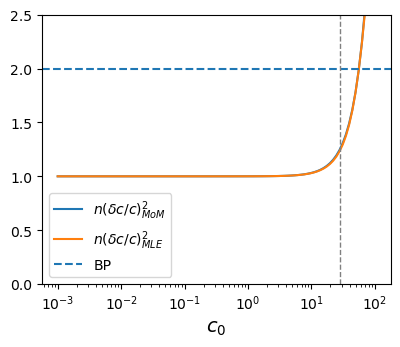

In [1824]:
fig, ax = plt.subplots(1,1, figsize=(4.5,3.5))

ax.plot(cvals, vars_mom, label="$n(\\delta c/c)^2_{MoM}$")
ax.plot(cvals, vars_mle, label="$n(\\delta c/c)^2_{MLE}$")
ax.set_xscale('log')
ax.set_xlabel("$c_0$", fontsize=14)
ax.set_ylim(0,2.5)
ax.axhline(y=2, linestyle="dashed", label="BP")
# ax.axhline(y=1, linestyle="solid", lw=1, color="black", alpha=0.3)
ax.axvline(x=2.5/kb, linestyle="dashed", color="gray", lw=1)
ax.legend()

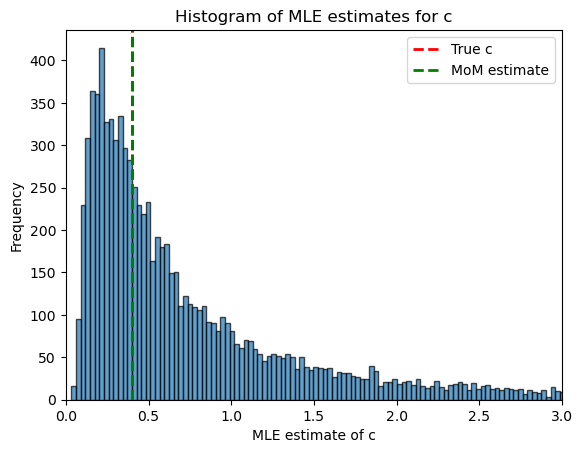

In [1012]:
# Optional: Plot a histogram of the MLE estimates.
plt.hist(c_mle_list, bins=2000, edgecolor='k', alpha=0.7)
plt.xlabel("MLE estimate of c")
plt.ylabel("Frequency")
plt.title("Histogram of MLE estimates for c")
plt.axvline(cTrue, color='red', linestyle='dashed', linewidth=2, label="True c")
plt.axvline(c_mom, color='green', linestyle='dashed', linewidth=2, label="MoM estimate")
plt.legend()
plt.xlim(0,3)
plt.show()

### Numerical integration for the variance of the MLE for ON

Numerical integral result: 0.0001503093185774777
Estimated integration error: 1.4614478475802588e-13


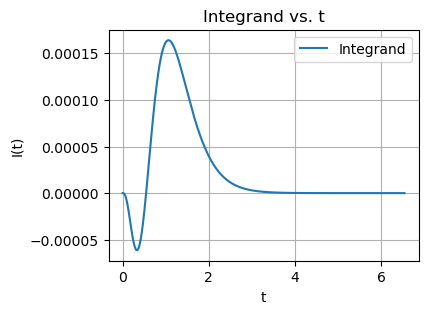

In [1825]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# Define helper functions for coth and csch that handle small arguments.
def coth(x):
    # For very small x, use the series expansion: coth(x) ~ 1/x + x/3
    if np.abs(x) < 1e-8:
        return 1.0/x + x/3.0
    elif x > 100:
        return 1.0
    else:
        return np.cosh(x) / np.sinh(x)

def csch(x):
    # For very small x, use the series expansion: csch(x) ~ 1/x - x/6
    if np.abs(x) < 1e-8:
        return 1.0/x - x/6.0
    elif x > 100:
        return 0
    else:
        return 1.0/np.sinh(x)

# Define the integrand function.
def IonIntegrand(t, c, koffu, kuon, kbon):
    """
    Computes the integrand:
    
    I(t) = -{ A*exp(-0.5*(B+sqrt(D))*t) * (exp(sqrt(D)*t)-1)*kbon^2 *
           [ -4*(8*A + D) + 8*A*sqrt(D)*t*coth( (sqrt(D)*t)/2 )
             + D*(4*A + D)*t^2*csch( (sqrt(D)*t)/2 )^2 ]
          } / ( 4 * D^(5/2) ).
    """
    A = koffu * kuon    # Example value for A
    B = c *kbon + koffu + kuon   # Example value for B
    D = -4 *koffu* kuon + (c* kbon + koffu + kuon)**2    # Example value for D (should be positive)

    sqrtD = np.sqrt(D)
    exp_diff = np.exp(-0.5*(B - sqrtD)*t) - np.exp(-0.5*(B + sqrtD)*t)

    # Argument for coth and csch:
    arg = sqrtD * t / 2.0
    coth_val = coth(arg)
    csch_val = csch(arg)
    
    # The bracketed term
    bracket = -4*(8*A + D) + 8*A*sqrtD*t*coth_val + D*(4*A + D)*t**2 * (csch_val**2)
    
    numerator = A * exp_diff * (kbon**2) * bracket
    denominator = 4 * (D**(5/2))
    
    return numerator/denominator

def Ion(c, koffu, kuon, kbon):
    """
    Computes the Fisher information observing ON times
    """
    tauon = 1/koffu + 1/kuon + c*kbon/(koffu*kuon)

    # Define integration limits. For example, integrate from t=0 to t=10.
    t_min = 1e-4*tauon
    t_max = 15*tauon
    result, error = quad(IonIntegrand, t_min, t_max, args=(c, koffu, kuon, kbon))

    if error/(result * c**2) < 1e-2:
        return result
    else:
        raise ValueError("Relative error too large")

# Example parameter values (modify these as needed)
koffu=5
kuon=5
kbon = 0.0888   # Example value for kbon
c = 10
tauon = 1/koffu + 1/kuon + c*kbon/(koffu*kuon)

# Define integration limits. For example, integrate from t=0 to t=10.
t_min = 1e-4
t_max = 15*tauon

# Perform the numerical integration using quad.
result, error = quad(IonIntegrand, t_min, t_max, args=(c, koffu, kuon, kbon))

print("Numerical integral result:", result)
print("Estimated integration error:", error)

# Optional: Plot the integrand over the integration range.
t_vals = np.linspace(t_min, t_max, 1000)
y_vals = [IonIntegrand(t, c, koffu, kuon, kbon) for t in t_vals]

plt.figure(figsize=(4, 3))
plt.plot(t_vals, y_vals, label="Integrand")
plt.xlabel("t")
plt.ylabel("I(t)")
plt.title("Integrand vs. t")
plt.legend()
plt.grid(True)
plt.show()


In [1827]:
nparams = 100

ioffs = np.zeros(2*nparams)
ions = np.zeros(2*nparams)
cvals = np.logspace(-2,5,2*nparams)

kmax=5
dl_tf=0.0888

konb = 5
koffu = kmax
kuon = kmax
kbon = dl_tf   # Example value for kbon
kboff = dl_tf

for i, c in enumerate(cvals):
    if c < 1:
        ions[i] = 1e-5
    else:
        ions[i] = (Ion(c, koffu, kuon, kbon)) * c**2
    
    ioffs[i] = (Ioff(c, kboff, konb)) * c**2


(0.0, 3.0)

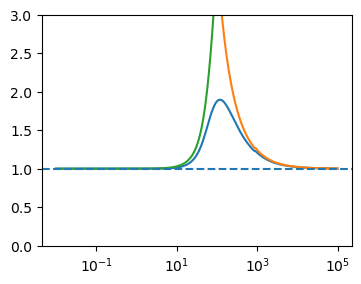

In [1828]:
fig, ax = plt.subplots(1,1, figsize=(4,3))

ax.plot(cvals, 1/(ions + ioffs))
ax.plot(cvals, 1/ions)
ax.plot(cvals, 1/ioffs)
ax.set_xscale('log')
ax.axhline(y=1, linestyle="dashed")
# ax.axvline(x=4 *koffu* kuon, linestyle="solid", lw=0.8, alpha=0.5, color="black")
# ax.axhline(y=0.5, linestyle="solid", lw=0.8, alpha=0.5, color="black")
ax.set_ylim(0,3)

In [ ]:
c = 20
a = c*kboff/(konb-c*kboff)
Ioff(c, kboff, konb) * c**2
# print('a =',a)
# a**2 * (1 - 2*kon * a**2 * zeta(3,a) / (c*kb))

0.8939319511647763

In [1840]:
from scipy.optimize import differential_evolution, shgo

def VMLE(logrates, c, dc):
    """
    Computes the SPRT drift for MLE estimation
    """
    kboff, kbon, konb, kuon, koffu = 10**logrates

    tauon = 1/koffu + 1/kuon + c*kbon/(koffu*kuon)
    tauoff = 1/(c*kboff) + 1/konb
    tau = tauon + tauoff

    if c < 40:
        ion = 0
        ioff = Ioff(c, kboff, konb)
    elif c > 1e4:
        ion = Ion(c, koffu, kuon, kbon)
        ioff = 0
    else:
        ion = Ion(c, koffu, kuon, kbon)
        ioff = Ioff(c, kboff, konb)

    return - dc**2*(ion + ioff) / tau

# Suppose your 5 variables each have [low_i, high_i]
a = 3e-3        # ums
D_tf = 7.4      # um^2/s
dl_tf = 4*a*D_tf
llb = -5
lub = np.log10(5)

bounds = [(llb, np.log10(dl_tf)),
          (llb, np.log10(dl_tf)),
          (llb, lub),
          (llb, lub),
          (llb, lub)]

x_opts = np.zeros((nparams, 5))
f_opts = np.zeros(nparams)
cvals = np.logspace(-2, 4, nparams)

for i, c in enumerate(cvals):

    dc = c/10

    result = shgo(VMLE, bounds=bounds, args=(c, dc), iters=20)

    x_best = result.x      # The best solution found
    f_best = -result.fun   # The maximum value (since we stored negative)

    x_opts[i] = x_best
    f_opts[i] = f_best

    # print("Best X:", x_best)
    # print("Best function value:", f_best)


/home/tohme/miniconda3/envs/flython/lib/python3.11/site-packages/scipy/optimize/_optimize.py:404: RuntimeWarning: Values in x were outside bounds during a minimize step, clipping to bounds
  warnings.warn("Values in x were outside bounds during a "


(0.1, 1000.0)

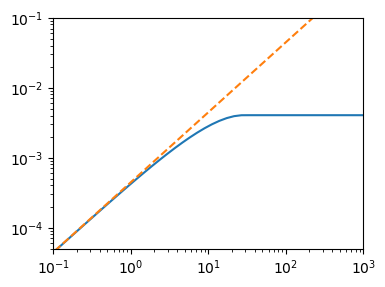

In [1841]:
fig, ax = plt.subplots(1,1,figsize=(4,3))

ax.plot(cvals, f_opts/2)
ax.plot(cvals, 0.5*0.01*cvals*dl_tf, linestyle="dashed")
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylim(5e-5, 1e-1)
ax.set_xlim(1e-1, 1e3)

In [1842]:
data_shgo = {}

for i, c in enumerate(cvals):

    kboff, kbon, konb, kuon, koffu = x_opts[i]
    konu = -5
    kuoff = -5
    koffb = -5

    data_shgo[i+1] = [kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb, f_opts[i], c]

# IR limits

### IR for the mgr circuit against non-difflimited rates (1bs and 2bs)

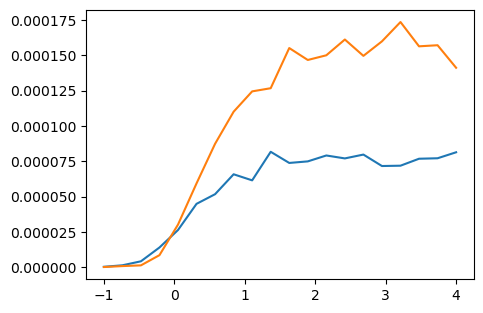

In [2]:
path = '/home/tohme/.julia/dev/LLROpt/data/20241211/irlimit/'
data_1bs = json.load(open(path+'ir_full_1bs_scaling.json'))
data_2bs = json.load(open(path+'ir_full_2bs_scaling.json'))

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

kvals = [data_1bs[str(i)]["k"] for i in range(1, 21)]
vals_1bs = [data_1bs[str(i)]["val"] for i in range(1, 21)]
vals_2bs = [data_2bs[str(i)]["val"] for i in range(1, 21)]
ax.plot(kvals, vals_1bs)
ax.plot(kvals, vals_2bs)

# Dependence of V on concentration 

## 1 binding site

### $\max \{ IR(c)\}$ as a function of c

In [2]:
def vfull(c, dc, logrates):
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = 10**np.array(logrates)
    return 0.5 * (dc/c)**2 * c * (kbon + kboff)

In [331]:
d1 = '20250131/1bs-irfull-c'
d2 = '20250201/1bs-irfull-c-run2'
d3 = '20250201/1bs-irfull-c-run3'
dirlist = [d1,d2,d3]
ndirs = len(dirlist)
data_combined = {}

_, params = get_data(d1, "full")
nparams = params["nparams"]
nedges = 8

data_params_list = [get_data(dir, "full") for dir in dirlist]

for i in range(1, nparams+1):
    argmax_ik = np.argmax([data_params_list[k][0][i][nedges] for k in range(ndirs)])
    data_combined[i] = data_params_list[argmax_ik][0][i]


In [332]:
path = "data/20250207/1bs-irfull-c/"
datafile = "{}ir_full_vs_ep_pareto_pid1.json".format(path)
paramfile = "{}params.json".format(path)

with open(datafile, "w") as f:
    json.dump(data_combined, f)

with open(paramfile, "w") as f:
    params["ncpus"] = 1
    json.dump(params, f)

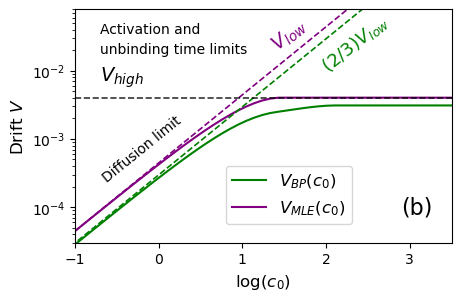

In [1810]:
# dirname = '20241218/2bs-ir-c-c0-m2-to-p4'
dirname_acc = '20241212/test-ir-c'
# dirname_acc = '20250220/ir-acc-c-equil'
dirname_full = '20250207/1bs-irfull-c'

ncpus = 1
nedges = 8
figsize = (4.5,2.9)
ks = [32, 64]
dirs = [dirname_full, dirname_acc]
whichfs = ["full", "acc"]
colors = ["purple", "green"]
labels=["$V_{MLE}(c_0)$", "$V_{BP}(c_0)$"]

fig, ax = plt.subplots(1,1, figsize=figsize, layout="constrained")

ax.set_yscale('log')
ax.set_ylabel("Drift $ V$", fontsize=12)
ax.set_xlabel("$\log (c_0)$", fontsize=12)
ax.set_xticks(list(range(-2,5)))

for i in [1]:
    k = ks[i]
    dirname = dirs[i]
    whichf = whichfs[i]
    data, params = get_data(dirname, whichf)
    nparams = params["nparams"]
    edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
    input_edges = [(0,2), (1,3)]
    on_ind = [0,1,0,1]

    irvals = np.array([data[i][nedges] for i in range(1, nparams+1)])
    cvals = np.array([data[i][nedges+1] for i in range(1, nparams+1)])

    logrates = data[k][:nedges]
    c = data[k][nedges+1]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = 10**np.array(logrates)

    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
    input_edges = [(0,2), (1,3)]
    on_ind = [0,1,0,1]
    # tauon, tauoff = ctmc.mean_fpt_part(we_lin, input_edges, c, on_ind)

    vfull_vals = [vfull(data[i][nedges+1], data[i][nedges+1]/10, data[i][:nedges]) for i in range(1,k+1)]

    # if i == 0:
    #     ax.plot(np.log10(cvals), vfull_vals, color="C2", label="Vfull")

    ax.plot(np.log10(cvals), irvals, label=labels[i], color=colors[i])

ax.plot(np.log10(cvals), f_opts/2, color="purple", label=labels[0])

ax.plot(np.log10(cvals), 0.5*0.01*cvals*dl_tf, linestyle="dashed",lw=1.2, color="purple")
ax.plot(np.log10(cvals), (1/3)*0.01*cvals*dl_tf, linestyle="dashed",lw=1.2, color="green")

tauoff = 1/2.5 + 1/5
tauon = 2/5
taubmax = tauon + tauoff

ax.axhline(y=0.5*0.01/(taubmax+2.5**2/25), color="black", linestyle="dashed", alpha=0.8,lw=1.2)
# ax.axvline(x=(np.log10(5/(2*0.0888))))
ax.set_ylim(3e-5, 0.08)
ax.set_xlim(-1, 3.5)
ax.text(2.9, 8e-5, "(b)", fontsize=16)
ax.text(1.3,0.02,"$V_{low}$", color="purple", fontsize=14, rotation=39)
ax.text(1.9,0.01,"$(2/3)V_{low}$", color="green", fontsize=13, rotation=39)
ax.text(-0.7, 0.007, "$V_{high}$", color="black", fontsize=14)
ax.text(-0.7, 0.035, "Activation and", color="black", fontsize=10)
ax.text(-0.7, 0.018, "unbinding time limits", color="black", fontsize=10)
ax.text(-0.7, 2.4e-4, "Diffusion limit", color="black", fontsize=10, rotation=39)
ax.legend(loc=(0.4, 0.08), fontsize=12)

In [1789]:
date = 20250301
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/ir-acc-full-c0-wide.pdf'.format(os.environ["HOME"], date))

### EP versus c for the above data

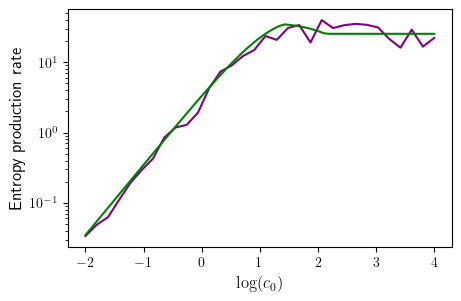

In [726]:
# dirname = '20241218/2bs-ir-c-c0-m2-to-p4'
dirname_acc = '20241212/test-ir-c'
# dirname_acc = '20250220/ir-acc-c-equil'
dirname_full = '20250207/1bs-irfull-c'

ncpus = 1
nedges = 8
figsize = (4.5,2.9)
ks = [32, 64]
dirs = [dirname_full, dirname_acc]
whichfs = ["full", "acc"]
colors = ["purple", "green"]
labels=["$V_{MLE}(c_0)$", "$V_{BP}(c_0)$"]

fig, ax = plt.subplots(1,1, figsize=figsize, layout="constrained")

ax.set_yscale('log')
ax.set_ylabel("Entropy production rate", fontsize=12)
ax.set_xlabel("$\log (c_0)$", fontsize=12)
ax.set_xticks(list(range(-2,5)))

for i in [0,1]:
    k = ks[i]
    dirname = dirs[i]
    whichf = whichfs[i]
    data, params = get_data(dirname, whichf)
    nparams = params["nparams"]
    edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
    input_edges = [(0,2), (1,3)]
    on_ind = [0,1,0,1]

    irvals = np.array([data[i][nedges] for i in range(1, nparams+1)])
    cvals = np.array([data[i][nedges+1] for i in range(1, nparams+1)])

    epvals = np.zeros(nparams)

    for j in range(1, nparams+1):
        logrates = data[j][:nedges]
        c = data[j][nedges+1]
        we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
        Q = utils.build_mat(we_lin, input_edges, c)
        epvals[j-1] = ctmc.EP_ss(Q)

    logrates = data[k][:nedges]
    c = data[k][nedges+1]
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = 10**np.array(logrates)

    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
    input_edges = [(0,2), (1,3)]
    on_ind = [0,1,0,1]
    tauon, tauoff = ctmc.mean_fpt_part(we_lin, input_edges, c, on_ind)
    # tauoff = 1/(c*kboff)
    # tauon = c*kbon/(koffu*kuon)
    taubmax = tauon + tauoff

    vfull_vals = [vfull(data[i][nedges+1], data[i][nedges+1]/10, data[i][:nedges]) for i in range(1,k+1)]

    ax.plot(np.log10(cvals), epvals, label=labels[i], color=colors[i])

# ax.plot(np.log10(cvals), (6/3)*cvals*0.001185/5.6, linestyle="dashed",lw=1.2, color="purple")
# ax.plot(np.log10(cvals), (4/3)*cvals*0.001185/5.6, linestyle="dashed",lw=1.2, color="green")

# ax.axhline(y=0.01/taubmax, color="black", linestyle="dashed", alpha=0.8,lw=1.2)
# ax.axvline(x=(np.log10(5/(2*0.0888))))
# ax.set_ylim(3e-5, 0.08)
# ax.set_xlim(-1, 3.5)
# ax.text(2.9, 8e-5, "(b)", fontsize=16)
# ax.text(1.3,0.02,"$V_{low}$", color="purple", fontsize=14, rotation=39)
# ax.text(1.9,0.01,"$(2/3)V_{low}$", color="green", fontsize=13, rotation=39)
# ax.text(2.8, 0.01, "$V_{high}$", color="black", fontsize=14)
# ax.text(-0.7, 0.026, "Activation and", color="black", fontsize=10)
# ax.text(-0.7, 0.013, "unbinding time limits", color="black", fontsize=10)
# ax.text(-0.7, 2.4e-4, "Diffusion limit", color="black", fontsize=10, rotation=39)
# ax.legend(loc=(0.4, 0.08), fontsize=12)

### I/O curves for the above circuits

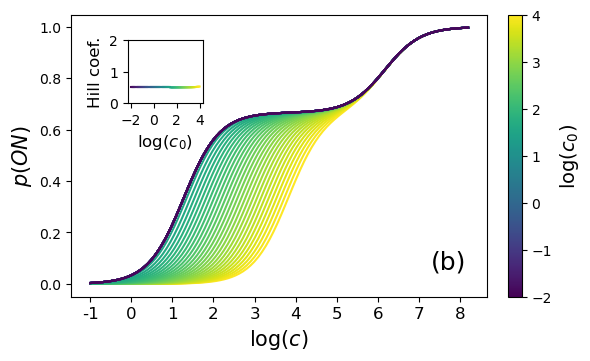

In [1855]:
from matplotlib.colors import Normalize
import numdifftools as nd

# dirname = '20241218/2bs-ir-c-c0-m2-to-p4'
# dirname = '20241212/test-ir-c'
# dirname = '20250220/ir-acc-c-equil'
# dirname = '20250207/1bs-irfull-c'
ncpus = 1
nedges = 8
nbetas = 64
figsize = (5.8,3.5)
# data, params = get_data(dirname, "acc")
data = data_shgo
nparams = params["nparams"]
plt.rcParams['text.usetex'] = False

irvals_acc = np.array([data[i][nedges] for i in range(1, nparams+1)])
c_acc = np.array([data[i][nedges+1] for i in range(1, nparams+1)])
cvals = np.linspace(-1, 8.2, 100)
cmax = np.max(c_acc)

fig, ax = plt.subplots(1,1, figsize=figsize, layout='constrained')

cmap = plt.cm.viridis
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-2, 4), cmap=cmap), ax=ax)
cbar.set_label(r"$\log (c_0)$", fontsize=14)
ax.set_xlabel("$\log(c)$", fontsize=15)
ax.set_ylabel("$p(ON)$", fontsize=15)
ax.set_xticks(range(-1, 9, 1))
ax.set_xticklabels(range(-1, 9, 1), fontsize=12)
ax.text(7.3, 0.06, "(b)", fontsize=18)

left, bottom, width, height = [0.21, 0.72, 0.13, 0.18]
ax2 = fig.add_axes([left, bottom, width, height])
ax2.set_ylim(0, 2)
ax2.set_ylabel('Hill coef.', fontsize=12)
ax2.set_xticks([-2,0,2, 4])
ax2.set_xlabel('$\log (c_0)$', fontsize=12)

for i in range(nbetas, 1, -1):
    logrates = data[i][:nedges]
    c_i = data[i][nedges+1]
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
    f = lambda x : ctmc.pi_on(we_lin, input_edges, 10**x, on_ind)
    # df = nd.Derivative(f, order=3)

    pon = [f(c) for c in cvals]

    mu = (np.log10(c_i) + 2) / 6
    ax.plot(cvals, pon, color=cmap(mu))
    
c_i_last = data[1][nedges+1]
hill_i_last = 0

for i in range(1,nbetas+1):
    logrates = data[i][:nedges]
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
    
    # find half-max
    f = lambda x : ctmc.pi_on(we_lin, input_edges, np.e**x, on_ind)
    # df = nd.Derivative(f, order=3)
    pon = [f(c) for c in cvals]
    logc_k, _ = find_halfmax(f, lb=-7, ub=14, tol=1e-4)
    # c_max = cvals[np.argmax(pon)]
    
    # true concentration
    c_i = data[i][nedges+1]

    # hill coefficient
    hill_i = ctmc.sharpness(we_lin, input_edges, np.e**logc_k, on_ind) #* np.log(10)
    # hill_i = f(c_max) / np.log(10)
    pion = ctmc.pi_on(we_lin, input_edges, np.e**logc_k, on_ind)

    # normalize by activity
    hill_i = hill_i / (pion * (1 - pion)) 
    if i > 1:
        mu = (np.log10(c_i) + 2) / 6
        ax2.plot((np.log10(c_i_last), np.log10(c_i)), (hill_i_last, hill_i), color=cmap(mu))
    
    c_i_last = c_i
    hill_i_last = hill_i


In [1856]:
date = 20250301
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/1bs-pon-c-c0-with-hill-coef-hires.pdf'.format(os.environ["HOME"], date))

### Half-max $c$ and max-sharpness $c$ versus $c_0$

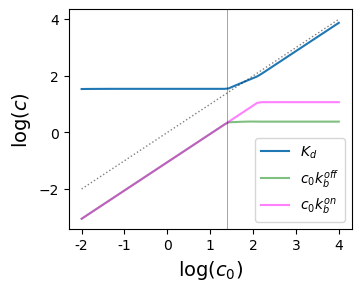

In [911]:
from matplotlib.colors import Normalize
import numdifftools as nd

# dirname = '20241218/2bs-ir-c-c0-m2-to-p4'
dirname = '20241212/test-ir-c'
# dirname = '20250220/ir-acc-c-equil'
# dirname = '20250207/1bs-irfull-c'
ncpus = 1
nedges = 8
nbetas = 64
figsize = (3.5, 2.8)
data, params = get_data(dirname, "acc")
nparams = params["nparams"]
plt.rcParams['text.usetex'] = False

irvals_acc = np.array([data[i][nedges] for i in range(1, nparams+1)])
c_acc = np.array([data[i][nedges+1] for i in range(1, nparams+1)])
cvals = np.linspace(-1, 5.7, nbetas)
cmax = np.max(c_acc)
# c_maxsharp = np.zeros(nbetas)
# c_halfmax = np.zeros(nbetas)
kboffs = np.zeros(nbetas)
kbons = np.zeros(nbetas)

fig, ax = plt.subplots(1,1, figsize=figsize, layout='constrained')

cmap = plt.cm.viridis
# ax.set_xlabel("$\log(c)$", fontsize=15)
# ax.set_ylabel("$p(ON)$", fontsize=15)
ax.set_xticks(range(-2, 5, 1))
ax.set_xticklabels(range(-2, 5, 1), fontsize=12)
# ax.text(5, 0.06, "(a)", fontsize=18)

for i in range(nbetas, 0, -1):
    logrates = data[i][:nedges]
    c_i = data[i][nedges+1]
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
    f = lambda x : ctmc.pi_on(we_lin, input_edges, 10**x, on_ind)
    df = nd.Derivative(f, order=3)
    # dfs = np.array([df(c) for c in cvals])
    # c_maxsharp[i-1] = cvals[np.argmax(dfs)]

    # mu = (np.log10(c_i) + 2) / 6
    # ax.plot(cvals, dfs, color=cmap(mu))
    # ax.axvline(x=c_maxsharp[i-1])

    # pon = [f(c) for c in cvals]
    # c_halfmax[i-1], _ = find_halfmax(f, lb=-7, ub=14, tol=1e-4)
    kboffs[i-1] = logrates[0]
    kbons[i-1] = logrates[2]
    
# ax.plot(np.log10(c_acc), c_maxsharp, color="C1")
ax.plot(np.log10(c_acc), c_halfmax, color="C0", label="$K_{d}$")
ax.plot(np.log10(c_acc), np.log10(c_acc), linestyle="dotted", color="black", lw=1, alpha=0.5)
# ax.plot(np.log10(c_acc), kboffs, color="green", linestyle="solid")
# ax.plot(np.log10(c_acc), kbons, color="magenta")

ax.plot(np.log10(c_acc), np.log10(c_acc)+kboffs, color="green", 
        linestyle="solid", alpha=0.5, label="$c_0k_b^{off}$")
ax.plot(np.log10(c_acc), np.log10(c_acc)+kbons, color="magenta", 
        linestyle="solid", alpha=0.5, label="$c_0k_b^{on}$")

ax.tick_params(labelsize=10, axis='both')
ax.set_xlabel("$\log(c_0)$", fontsize=14)
ax.set_ylabel("$\log(c)$", fontsize=14)
ax.legend(loc='lower right')
ax.axvline(x=1.39, color="black", lw=0.5, alpha=0.5)

In [843]:
date = 20250226
dirname = '{}/phd/flython/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/phd/flython/plots/{}/c-halfmax-kbs-vs-c0.svg'.format(os.environ["HOME"], date))

### Optimal circuits in each regime

In [900]:
k = 50

log c =  2.6666666541650654
tauon =  0.8706671476813084
ckboff =  2.4085543687116204
ckbon =  11.766672180162491


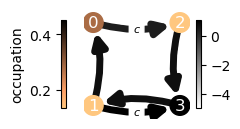

In [901]:
dirname = '20241212/test-ir-c'
# dirname = '20250207/1bs-irfull-c'
# dirname = '20250220/ir-acc-c-equil'
ncpus = 1
nedges = 8
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc")
c = data[k][nedges+1]
logrates = data[k][:nedges]
kboff, konu, kbon,  koffu, kuoff, konb,  kuon,  koffb = 10**np.array(logrates)
edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
ie = [(0,2), (1,3)]
we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
we[0][2] += np.log10(c)
we[2][2] += np.log10(c)
minrate = np.min([we[i][2] for i in range(8)])
maxrate = np.max([we[i][2] for i in range(8)])

Q = utils.build_mat(we_lin, ie, c)
pss = ctmc.P_ss(Q)
G = nx.Graph()
G.add_edges_from(edges)
colors = [pss[int(i)] for i in G.nodes()]
minprob = np.min(colors)
maxprob = np.max(colors)
node_labels = dict(zip(range(4), [0,1,2,3]))

fig, ax, G = plot.draw_circuit(we, ie, dims=(2.5,1.4), node_size=200, arrsize=20,
                               nodefsize=12, node_color=colors, colorbar=False, 
                               node_labels=node_labels, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8)
print("log c = ", np.log10(c))

ax.set_axis_off()
norm = Normalize(minprob, maxprob)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
             ax=ax, label="occupation", location="left", shrink=0.8)

# cbar.set_ticks(ticks=[-6, -4, -2, 0])
# cbar.set_ticks(ticks=[0.2, 0.3, 0.4])
# cbar.set_ticks(ticks=[0.0, 0.5, 1.0])
# ax.text(-0.4, -0.1, r"$c_0 = 10^{3}$", fontsize=11)
# ax.text(-0.2, -0.4, r"(c)", fontsize=16)

norm = Normalize(minrate, maxrate)
cbarr = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax, location="right", shrink=0.8)

cbarr.set_ticks(ticks=[-4, -2, 0])
print('tauon = ', 1/koffu + (c*kbon+koffu)/(koffu*kuon))
print('ckboff = ',we_lin[0][2]*c)
print('ckbon = ',we_lin[2][2]*c)

In [909]:
konb = 5
koffu = 5
kuon = 5
c = 100
kbon = 0.0888
varon = (c*kbon+koffu)/(koffu*kuon**2) + 1/(koffu**2)
tauon = 1/koffu + (c*kbon+koffu)/(koffu*kuon)
A = varon + 1/konb**2
B = -2/konb -2*tauon
C = -1
np.log10(2.1/0.0888)

1.3738063289553182

In [1724]:
date = 20250111
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/opt-circuit-high-c.pdf'.format(os.environ["HOME"], date))

### Hill coefficient as a function of $c_0$

In [3]:
def find_halfmax(f, target=0.5, lb=-5, ub=5, tol=1e-4, verbose=False):
    """
    Binary search for a given value of f, assuming it's monotonically increasing.
    """
    c_k = (ub + lb) / 2
    f_k = f(c_k)
    
    while np.abs(f_k - target) > tol:
        
        if f_k > target:
            ub = c_k
        elif f_k <= target:
            lb = c_k
        else:
            raise ValueError("something's wrong with f")
            
        c_k = (ub + lb) / 2
        f_k = f(c_k)
        
        if verbose:
            print(c_k, f_k)
        
    return c_k, f_k

In [142]:
logrates = data[5][:10]
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
f = lambda x : ctmc.pi_on(we_lin, input_edges, 10**x, on_ind)

find_halfmax(f, lb=0, ub=4, tol=1e-3)

(1.5390625, 0.49977926940157863)

### Testing half-max function

/tmp/ipykernel_29679/186794162.py:11: RuntimeWarning: invalid value encountered in log10
  pon = [f(np.log10(c)) for c in cvals]


[]

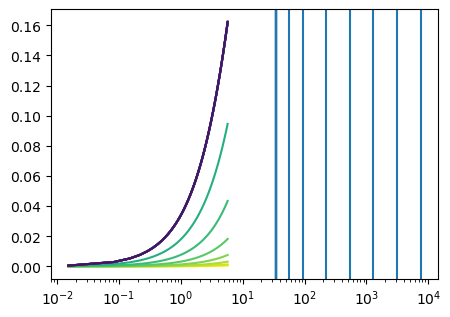

In [468]:
c_halfmaxs = []

fig, ax = plt.subplots(1,1,figsize=(5,3.5))

for i in range(64, 1, -4):
    logrates = data[i][:10]
    c_i = data[i][nedges+1]
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])

    f = lambda x : ctmc.pi_on(we_lin, input_edges, 10**x, on_ind)
    pon = [f(np.log10(c)) for c in cvals]
    
    c_k, _ = find_halfmax(f, lb=-2, ub=4, tol=1e-3)
    c_halfmaxs.append(c_k)

    mu = (np.log10(c_i) + 2) / 6
    ax.plot(cvals, pon, color=cmap(mu))
    ax.set_xscale('log')
    ax.axvline(x=10**c_k)
    
ax.plot()

## 2 binding sites

### $\max \{ IR(c)\}$ as a function of c

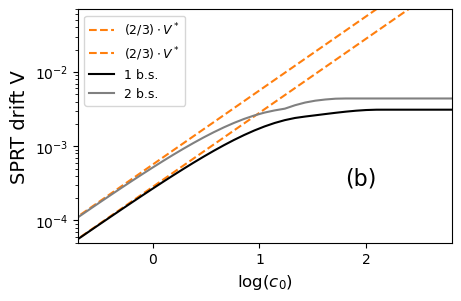

In [470]:
# dirname = '20250111/2bs-ir-c-c0-m4-p3'
dirname = '20250109/2bs-ir-c'
ncpus = 16
nedges = 10
figsize = (4.5,2.9)
data, params = get_data(dirname, "acc")
nparams = params["nparams"]

irvals_acc2 = np.array([data[i][nedges] for i in range(1, nparams+1)])
c_acc2 = np.array([data[i][nedges+1] for i in range(1, nparams+1)])

fig, ax = plt.subplots(1,1, figsize=figsize, layout="constrained")

# ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel("SPRT drift V", fontsize=14)
ax.set_xlabel("$\log (c_0)$", fontsize=12)
ax.set_xticks(list(range(-2,5)))
# ax.plot(np.log10(c_acc), (8/3)*c_acc*0.001185/5.6, linestyle="dashed", color="C1", label="$(4/3)\cdot V_{max}$")
# ax.axhline(y=0.01*(2/3), linestyle="dashed", color="C2", label="$(4/3)\cdot(dc/c)^2$")
ax.set_xlim(-0.7, 2.8)
ax.set_ylim(5e-5, 7e-2)
ax.text(1.8, 3e-4, "(b)", fontsize=16)

dirname = '20241212/test-ir-c'

nedges = 8
data, params = get_data(dirname, "acc")
nparams = params["nparams"]

irvals_acc = np.array([data[i][nedges] for i in range(1, nparams+1)])
c_acc = np.array([data[i][nedges+1] for i in range(1, nparams+1)])

ax.plot(np.log10(c_acc), (4/3)*c_acc*0.001185/5.6, linestyle="dashed", color="C1", label="$(2/3)\cdot V^*$")
ax.plot(np.log10(c_acc), (8/3)*c_acc*0.001185/5.6, linestyle="dashed", color="C1", label="$(2/3)\cdot V^*$")
# ax.axhline(y=0.5*0.01/taubmax, linestyle="dashed", color="C2", label="$(dc/c)^2$")
ax.plot(np.log10(c_acc), irvals_acc, color="black", label="1 b.s.")
ax.plot(np.log10(c_acc2), irvals_acc2, color="gray", label="2 b.s.")
ax.legend(fontsize=9)

In [2048]:
date = 20250111
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/1bs-2bs-ir-acc-c0-wide.pdf'.format(os.environ["HOME"], date))

### I/O curves for the above circuits

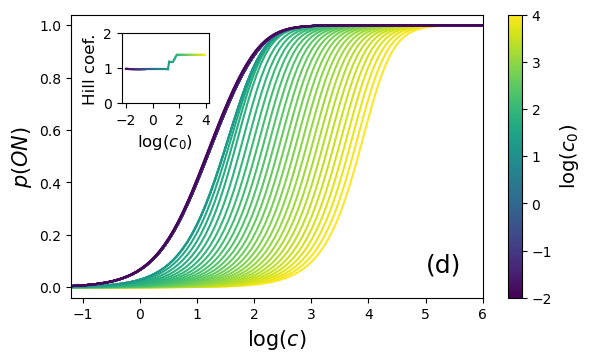

In [388]:
from matplotlib.colors import Normalize

dirname = '20250220/2bs-ir-acc-c'
ncpus = 16
nedges = 10
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc")
nparams = params["nparams"]
plt.rcParams['text.usetex'] = False

irvals_acc = np.array([data[i][nedges] for i in range(1, nparams+1)])
c_acc = np.array([data[i][nedges+1] for i in range(1, nparams+1)])

edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                  (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1
input_edges = np.array([(1,3), (2,4), (5,1), (6,2)]) - 1
on_ind = [0,1,0,1,0,1]
cvals = np.linspace(-2, 6, 100)
cmax = max(c_acc)

fig, ax = plt.subplots(1,1, figsize=figsize, layout='constrained')

cmap = plt.cm.viridis
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-2, 4), cmap=cmap), ax=ax)
cbar.set_label(r"$\log (c_0)$", fontsize=14)
# ax.set_xscale('log')
ax.set_xlabel("$\log(c)$", fontsize=15)
ax.set_ylabel("$p(ON)$", fontsize=15)
# ax.set_xticklabels(range(-6, 5), fontsize=12)
# ax.set_title("Hernan's function, 4-state circuit")
# ax.text(5, 0.06, "(a)", fontsize=18)
ax.set_ylim(-0.04, 1.04)
ax.set_xlim(-1.2, 6)

left, bottom, width, height = [0.2, 0.72, 0.15, 0.2]
ax2 = fig.add_axes([left, bottom, width, height])
ax2.set_ylim(0, 2)
# ax2.set_xscale('log')
ax2.set_ylabel('Hill coef.', fontsize=12)
ax2.set_xticks([-2, 0, 2, 4])
ax2.set_yticks([0,1,2])
ax2.set_xlabel('$\log (c_0)$', fontsize=12)
ax.text(5, 0.06, "(d)", fontsize=18)

for i in range(64, 1, -1):
    logrates = data[i][:nedges]
    c_i = data[i][nedges+1]

    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

    # edges = [(5,1),         (1,5),         (2,6),  (6,2),     (1,2),  (1,3),  (2,4),
    #          (2,1),         (3,1),         (3,4),  (4,2),     (4,3),  (5,6),  (6,5)]

    logrates2 = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon,
                 koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]
    
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])

    pon = [ctmc.pi_on(we_lin, input_edges, 10**c, on_ind) for c in cvals]

    mu = (np.log10(c_i) + 2) / 6
    ax.plot(cvals, pon, color=cmap(mu))
    
c_i_last = data[1][nedges+1]
hill_i_last = 0

for i in range(1,64):
    logrates = data[i][:10]
    kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

    # edges = [(5,1),         (1,5),         (2,6),  (6,2),     (1,2),  (1,3),  (2,4),
    #          (2,1),         (3,1),         (3,4),  (4,2),     (4,3),  (5,6),  (6,5)]

    logrates2 = [kboff+np.log10(2), kuoff,        kuon,  kbon+np.log10(2), kon1b, kboff, kbon,
                 koff1b,       kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu,  koffu]
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])
    
    # find half-max
    f = lambda x : ctmc.pi_on(we_lin, input_edges, 10**x, on_ind)
    pon = [f(c) for c in cvals]
    c_k, _ = find_halfmax(f, lb=-4, ub=5, tol=1e-4)
    
    # half-max true concentration
    c_i = data[i][nedges+1]

    # hill coefficient
    hill_i = 4 * ctmc.sharpness(we_lin, input_edges, 10**c_k, on_ind) #* np.log(10)
    
    if i > 1:
        mu = (np.log10(c_i) + 2) / 6
        ax2.plot((np.log10(c_i_last), np.log10(c_i)), (hill_i_last, hill_i), color=cmap(mu))
    
    c_i_last = c_i
    hill_i_last = hill_i


In [328]:
date = 20250220
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/2bs-pon-c-c0-with-hill-coef-hires.pdf'.format(os.environ["HOME"], date))

### Optimal circuits in each regime

In [384]:
k1=35
k2=k1

log c1 =  1.238095253445461
log c2 =  1.238095253445461


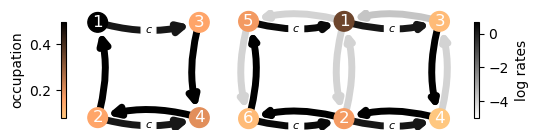

In [385]:
importlib.reload(plot)

##########   1 bs

dirname = '20241212/test-ir-c'
ncpus = 16
nedges1 = 8
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc")

c1 = data[k1][-1]
logrates = data[k1][:nedges1]
edges1 = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
ie1 = [(0,2), (1,3)]
we1 = np.array([(u,v,r) for ((u,v),r) in zip(edges1, logrates)])
we_lin1 = np.array([(u,v,10**r) for ((u,v),r) in zip(edges1, logrates)])
we1[0][2] += np.log10(c1)
we1[2][2] += np.log10(c1)
minrate1 = min([we1[i][2] for i in range(8)])
maxrate1 = max([we1[i][2] for i in range(8)])

Q1 = utils.build_mat(we_lin1, ie1, c1)
pss = ctmc.P_ss(Q1)
G = nx.Graph()
G.add_edges_from(edges1)
colors1 = [pss[int(i)] for i in G.nodes()]
minprob1 = min(colors1)
maxprob1 = max(colors1)
node_labels1 = dict(zip(range(4), range(1,5)))


##########  2 bs

dirname = '20250220/2bs-ir-acc-c'
nedges2 = 10
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc")

c2 = data[k2][nedges2+1]
logrates = data[k2][:nedges2]
kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

# edges = [(5,1),               (1,5),             (2,6), (6,2),            (1,2), (1,3), (2,4),
#          (2,1),               (3,1),             (3,4), (4,2),            (4,3), (5,6), (6,5)]

logrates2 = [kboff+np.log10(2), kuoff,             kuon,  kbon+np.log10(2), kon1b, kboff, kbon,
             koff1b,            kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu, koffu]

edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                  (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1
ie2 = [(0,2), (1,3), (4,0), (5,1)]
on_ind = [0,1,0,1,0,1]
we2 = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates2)])
we2_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])
we2[0][2] += np.log10(c2)
we2[3][2] += np.log10(c2)
we2[5][2] += np.log10(c2)
we2[6][2] += np.log10(c2)
minrate2 = min([we2[i][2] for i in range(nedges2)])
maxrate2 = max([we2[i][2] for i in range(nedges2)])

Q = utils.build_mat(we2_lin, ie2, c2)
pss = ctmc.P_ss(Q)
G = nx.Graph()
G.add_edges_from(edges)
colors2 = [pss[int(i)] for i in G.nodes()]
minprob2 = min(colors2)
maxprob2 = max(colors2)
node_labels2 = dict(zip(range(6), range(1,7)))

vmin, vmax = min(minprob1, minprob2), max(maxprob1, maxprob2)
rmin, rmax = min(minrate1, minrate2), max(maxrate1, maxrate2)

fig, ax = plt.subplots(1,2,figsize=(5.5,1.5), width_ratios=[0.6,1], layout="tight")

_, ax1, G = plot.draw_circuit(we1, ie1, figax=(fig,ax[0]), dims=(1,1.4), node_size=200, arrsize=15,
                               nodefsize=12, node_color=colors1, colorbar=False, vmin=vmin, vmax=vmax,
                               node_labels=node_labels1, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8, rmin=rmin, rmax=rmax)

_, ax2, G = plot.draw_circuit(we2, ie2, figax=(fig,ax[1]), dims=(3.3,1.4), node_size=200, arrsize=10,
                               nodefsize=12, node_color=colors2, colorbar=False, vmin=vmin, vmax=vmax,
                               node_labels=node_labels2, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8, bottom_set=[5,1,3],
                               rmin=rmin, rmax=rmax)

print("log c1 = ", np.log10(c1))
print("log c2 = ", np.log10(c2))

ax[0].set_axis_off()
norm = Normalize(vmin, vmax)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
             ax=ax[0], label="occupation", location="left", shrink=0.8)

# # cbar.set_ticks(ticks=[-6, -4, -2, 0])
# cbar.set_ticks(ticks=[0.1, 0.2, 0.3, 0.4])
# ax.text(-0.44, -0.1, r"$c_0 = 10^{3}$", fontsize=11)
# # ax.text(-0.2, -0.4, r"(c)", fontsize=16)

norm = Normalize(rmin, rmax)
cbarr = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax[1], label="log rates", location="right", shrink=0.8)

# cbarr.set_ticks(ticks=[-4, -2, 0])

log c =  -1.0


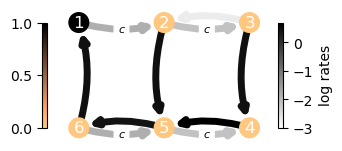

In [1734]:
importlib.reload(plot)

k = 28

dirname = '20250109/2bs-ir-c-c0-m4-p3'
ncpus = 16
nedges2 = 10
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc")

c2 = data[k][nedges2+1]
logrates = data[k][:nedges2]
kboff, konu, kbon, koffu, kuoff, kon1b, kuon, koff1b, kon2b, koff2b = logrates

# edges = [(5,1),               (1,5),             (2,6), (6,2),            (1,2), (1,3), (2,4),
#          (2,1),               (3,1),             (3,4), (4,2),            (4,3), (5,6), (6,5)]

logrates2 = [kboff+np.log10(2), kuoff,             kuon,  kbon+np.log10(2), kon1b, kboff, kbon,
             koff1b,            kuoff+np.log10(2), kon2b, kuon+np.log10(2), koff2b, konu, koffu]

edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                  (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1
ie2 = [(0,2), (1,3), (4,0), (5,1)]
on_ind = [0,1,0,1,0,1]
we2 = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates2)])
we2_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])
we2[0][2] += np.log10(c2)
we2[3][2] += np.log10(c2)
we2[5][2] += np.log10(c2)
we2[6][2] += np.log10(c2)
minrate = min([we2[i][2] for i in range(nedges2)])
maxrate = max([we2[i][2] for i in range(nedges2)])

Q = utils.build_mat(we2_lin, ie2, c2)
pss = ctmc.P_ss(Q)
G = nx.Graph()
G.add_edges_from(edges)
colors2 = [pss[int(i)] for i in G.nodes()]
minprob = min(colors2)
maxprob = max(colors2)
node_labels2 = dict(zip(range(6), [2,5,3,4,1,6]))

fig, ax, G = plot.draw_circuit(we2, ie2, dims=(3.3,1.4), node_size=200, arrsize=10,
                               nodefsize=12, node_color=colors2, colorbar=False, 
                               node_labels=node_labels2, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8, bottom_set=[5,1,3])
print("log c = ", np.log10(c2))

ax.set_axis_off()
norm = Normalize(minprob, maxprob)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
             ax=ax, location="left", shrink=0.8)

# cbar.set_ticks(ticks=[-8, -4, 0])
cbar.set_ticks(ticks=[0.0, 0.5, 1.0])
# ax.text(-0.64, -0.1, r"$c_0 = 10^{-1}$", fontsize=11)
# ax.text(0.25, -0.45, r"(c)", fontsize=18)

norm = Normalize(minrate, maxrate)
cbarr = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax, label="log rates", location="right", shrink=0.8)

cbarr.set_ticks(ticks=range(int(minrate), int(maxrate) + 1, 1))

In [1735]:
date = 20250111
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/2bs-opt-circuit-c0-m1.pdf'.format(os.environ["HOME"], date))

## With decoys

In [4]:
# change this so it can read output of both pareto.opt.dev and specificity.opt.dev

def get_data(dirname, whichf, whicha="pareto", skipkeys=[]):
    paramfile = "params"
    path = '{}/.julia/dev/LLROpt/data/'.format(os.environ["HOME"])
    params = json.load(open(path+'{}/{}.json'.format(dirname, paramfile)))

    data = {}
    data_proc = {}
    ncpus = params["ncpus"]
    nbetas = params["nparams"]
    nparams_per_cpu = int(nbetas/ncpus)

    if whicha == "pareto":
        whichalg = "_vs_ep_pareto_pid"
    elif whicha == "spec":
        whichalg = "_mix_vs_pure_pareto_pid"
    else:
        raise ValueError('argument whicha should be either pareto or spec' )

    # merge data from each process into a single dict
    for cpukey in range(1, ncpus + 1):
        if cpukey not in skipkeys:
            data_proc = json.load(open(path+'{}/ir_{}{}{}.json'.format(dirname, whichf, whichalg, cpukey)))

            for i in range(1, nparams_per_cpu+1):
                keyb = (cpukey - 1) * nparams_per_cpu + i
                data[keyb] = data_proc[str(keyb)]

    return data, params

### $\max \{ IR(c)\}$ as a function of c

gamma:  10.0
w:  2.5


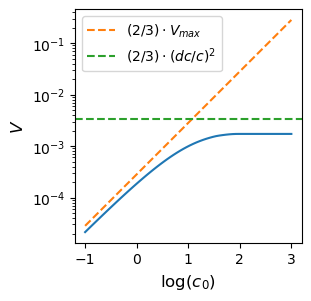

In [3108]:
# dirname = '20241218/2bs-ir-c-c0-m2-to-p4'
dirname = '20250114/1bs-ir-c-decoys-c0-m1-p3'
ncpus = 1
nedges = 8
figsize = (3,2.9)
data, params = get_data(dirname, "acc", "spec")
nparams = params["nparams"]
kg, kw = 3, 2
print("gamma: ", params["gammas"][kg-1])
print("w: ", params["wvals"][kw-1])

irvals_acc = np.array([data[i][str(kg)][str(kw)][nedges] for i in range(1, nparams+1)])
c_acc = np.array([data[i][str(kg)][str(kw)][nedges+1] for i in range(1, nparams+1)])

fig, ax = plt.subplots(1,1, figsize=figsize, layout="constrained")

# ax.set_xscale('log')
ax.set_yscale('log')
ax.set_ylabel("$V$", fontsize=12)
ax.set_xlabel("$\log (c_0)$", fontsize=12)
ax.set_xticks(list(range(-2,5)))
ax.plot(np.log10(c_acc), (4/3)*c_acc*0.001185/5.6, linestyle="dashed", color="C1", label="$(2/3)\cdot V_{max}$")
ax.axhline(y=0.5*0.01*(2/3), linestyle="dashed", color="C2", label="$(2/3)\cdot(dc/c)^2$")
ax.plot(np.log10(c_acc), irvals_acc)
ax.legend()
# ax.text(3, 5e-6, "(b)", fontsize=16)

In [ ]:
date = 20250108
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/ir-acc-c0-narrow.pdf'.format(os.environ["HOME"], date))

### I/O curves for the above circuits

gamma:  10.0
w:  100.0


/tmp/ipykernel_22651/2339296271.py:34: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(range(-2, 7), fontsize=12)


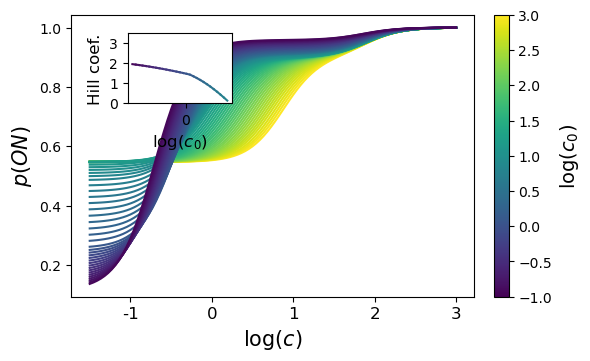

In [2185]:
from matplotlib.colors import Normalize

# dirname = '20241218/2bs-ir-c-c0-m2-to-p4'
dirname = '20250114/1bs-ir-c-decoys-c0-m1-p3'
ncpus = 1
nedges = 8
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc", "spec")
nparams = params["nparams"]

edges = np.array([(5,1), (1,5), (2,6), (6,2), (1,2), (1,3), (2,4),
                  (2,1), (3,1), (3,4), (4,2), (4,3), (5,6), (6,5)]) - 1
input_edges = [(0,2), (1,3)]
on_ind = [0,1,0,1,0,1]
cvals = np.linspace(-1, 8, 100)

kg, kw = 3, 3
gamma = params["gammas"][kg-1]
omega = params["wvals"][kw-1]
print("gamma: ", gamma)
print("w: ", omega)

irvals_acc = np.array([data[i][str(kg)][str(kw)][nedges] for i in range(1, nparams+1)])
c_acc = np.array([data[i][str(kg)][str(kw)][nedges+1] for i in range(1, nparams+1)])
cmax = max(c_acc)

fig, ax = plt.subplots(1,1, figsize=figsize, layout='constrained')

cmap = plt.cm.viridis
cbar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-1, 3), cmap=cmap), ax=ax)
cbar.set_label(r"$\log (c_0)$", fontsize=14)
ax.set_xlabel("$\log(c)$", fontsize=15)
ax.set_ylabel("$p(ON)$", fontsize=15)
ax.set_xticklabels(range(-2, 7), fontsize=12)
# ax.text(5, 0.06, "(a)", fontsize=18)
left, bottom, width, height = [0.21, 0.72, 0.18, 0.2]
ax2 = fig.add_axes([left, bottom, width, height])
ax2.set_ylim(1, 3.5)
ax2.set_ylabel('Hill coef.', fontsize=12)
ax2.set_xticks([-2, 0, 2, 4])
ax2.set_yticks([0,1,2,3])
ax2.set_xlabel('$\log (c_0)$', fontsize=12)

for i in range(64, 1, -1):
    logrates = data[i][str(kg)][str(kw)][:nedges]
    c_i = data[i][str(kg)][str(kw)][nedges+1]

    logcw = np.log10(c_i) + np.log10(omega)
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(gamma), kboff+logcw, kbon+logcw, kuon+np.log10(gamma), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
    
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])

    pon = [ctmc.pi_on(we_lin, input_edges, 10**c, on_ind) for c in cvals]

    mu = (np.log10(c_i) + 1) / 4
    ax.plot(cvals, pon, color=cmap(mu))
    
c_i_last = data[1][str(kg)][str(kw)][nedges+1]
hill_i_last = 0

for i in range(1,30):
    logrates = data[i][str(kg)][str(kw)][:nedges]
    c_i = data[i][str(kg)][str(kw)][nedges+1]

    logcw = np.log10(c_i) + np.log10(omega)
    kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
    logrates2 = [kuoff+np.log10(gamma), kboff+logcw, kbon+logcw, kuon+np.log10(gamma), 
        konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]
    
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])
    
    # find half-max
    f = lambda x : ctmc.pi_on(we_lin, input_edges, 10**x, on_ind)
    pon = [f(c) for c in cvals]
    c_k, _ = find_halfmax(f, lb=-3, ub=6, tol=1e-4)

    # hill coefficient
    hill_i = 4 * ctmc.sharpness(we_lin, input_edges, 10**c_k, on_ind) * np.log(10)
    
    if i > 1:
        mu = (np.log10(c_i) + 1) / 4
        ax2.plot((np.log10(c_i_last), np.log10(c_i)), (hill_i_last, hill_i), color=cmap(mu))
    
    c_i_last = c_i
    hill_i_last = hill_i


In [ ]:
date = 20250109
dirname = '{}/.julia/dev/LLROpt/plots/{}'.format(os.environ["HOME"], date)

if not os.path.exists(dirname):
    os.makedirs(dirname)

fig.savefig('{}/.julia/dev/LLROpt/plots/{}/1bs-pon-c-c0-with-hill-coef-hires.pdf'.format(os.environ["HOME"], date))

### Optimal circuits in each regime

log c =  -0.8095238318846714


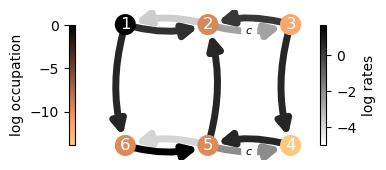

In [1914]:
k = 4
c = data[k][str(kg)][str(kw)][nedges + 1]
logrates = data[i][str(kg)][str(kw)][:nedges]

logcw = np.log10(c) + np.log10(omega)
kboff, konu, kbon, koffu, kuoff, konb, kuon, koffb = logrates
logrates2 = [kuoff+np.log10(gamma), kboff+logcw, kbon+logcw, kuon+np.log10(gamma), 
    konu, kboff, kbon, koffu, kuoff, konb, kuon, koffb, konb, koffb]

we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates2)])
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates2)])
we[0][2] += np.log10(c)
we[2][2] += np.log10(c)
minrate = min([we[i][2] for i in range(8)])
maxrate = max([we[i][2] for i in range(8)])

Q = utils.build_mat(we_lin, ie, c)
pss = ctmc.P_ss(Q)
colors = [np.log(p) for p in pss]
node_labels = dict(zip(range(6), [2,5,3,4,1,6]))

fig, ax, G = plot.draw_circuit(we, ie, dims=(4,1.8), node_size=200, 
                               nodefsize=12, node_color=colors, colorbar=False, 
                               node_labels=node_labels, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8,
                                bottom_set=[5,1,3])
print("log c = ", np.log10(c))

ax.set_axis_off()
norm = Normalize(min(colors), 0)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
             ax=ax, label="log occupation", location="left", shrink=0.8)

# cbar.set_ticks(ticks=[-8, -4, 0])
# cbar.set_ticks(ticks=[-2, -1, 0])
# ax.text(-0.64, -0.1, r"$c_0 = 100$", fontsize=11)
# ax.text(-0.2, -0.4, r"(c)", fontsize=16)

norm = Normalize(minrate, maxrate)
cbarr = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax, label="log rates", location="right", shrink=0.8)

# cbarr.set_ticks(ticks=[-4, -2, 0])

# What's going on with the Hill coefficient?

In [3336]:
k = 40

log c =  1.7142857076422455


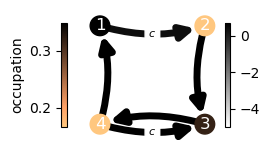

In [3337]:
dirname = '20241212/test-ir-c'
ncpus = 1
nedges = 8
figsize = (5.8,3.5)
data, params = get_data(dirname, "acc")
c = data[k][-1]
logrates = data[k][:nedges]
edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
ie = [(0,2), (1,3)]
we = np.array([(u,v,r) for ((u,v),r) in zip(edges, logrates)])
we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])
we[0][2] += np.log10(c)
we[2][2] += np.log10(c)
minrate = min([we[i][2] for i in range(8)])
maxrate = max([we[i][2] for i in range(8)])

Q = utils.build_mat(we_lin, ie, c)
pss = ctmc.P_ss(Q)
G = nx.Graph()
G.add_edges_from(edges)
colors = [pss[int(i)] for i in G.nodes()]
minprob = min(colors)
maxprob = max(colors)
node_labels = dict(zip(range(4), [1,4,2,3]))

fig, ax, G = plot.draw_circuit(we, ie, dims=(2.8,1.6), node_size=200, arrsize=20,
                               nodefsize=12, node_color=colors, colorbar=False, 
                               node_labels=node_labels, edge_cmap=plt.cm.gray.reversed(),
                               node_cmap=plt.cm.copper.reversed(), edgefsize=8)
print("log c = ", np.log10(c))

ax.set_axis_off()
norm = Normalize(minprob, maxprob)
cbar = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.copper.reversed()), 
             ax=ax, label="occupation", location="left", shrink=0.8)

# cbar.set_ticks(ticks=[0.2, 0.3, 0.4])
# ax.text(-0.4, -0.1, r"$c_0 = 10^{3}$", fontsize=11)
# ax.text(-0.2, -0.4, r"(c)", fontsize=16)

norm = Normalize(minrate, maxrate)
cbarr = plt.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=plt.cm.gray.reversed()), 
             ax=ax, location="right", shrink=0.8)

cbarr.set_ticks(ticks=[-4, -2, 0])

1.215472245374673

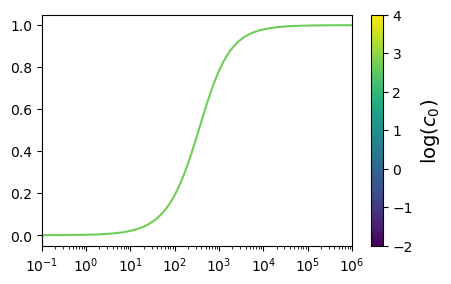

In [3403]:
fig, ax = plt.subplots(1,1,figsize=(5,3))

dirname = '20241212/test-ir-c'
data, params = get_data(dirname, "acc")

edges = np.array([(1,3), (1,2), (2,4), (2,1), (3,1), (3,4), (4,2), (4,3)]) - 1
ie = [(0,2), (1,3)]
on_ind = [0,1,0,1]
xvals = np.logspace(-2, 6, 100)
cmap = plt.cm.viridis
# inds = range(64, 1, -1)
inds = [50]

for i in inds:
    logrates = data[i][:nedges]
    c_i = data[i][nedges+1]
    we_lin = np.array([(u,v,10**r) for ((u,v),r) in zip(edges, logrates)])

    pon = [ctmc.pi_on(we_lin, ie, c, on_ind) for c in xvals]

    mu = (np.log10(c_i) + 2) / 6
    ax.plot(xvals, pon, color=cmap(mu))
    ax.set_xscale('log')
    ax.set_xlim(1e-1, 1e6)

cbar = fig.colorbar(plt.cm.ScalarMappable(norm=Normalize(-2, 4), cmap=cmap), ax=ax)
cbar.set_label(r"$\log (c_0)$", fontsize=14)

s = ctmc.sharpness(we_lin, ie, c_i, on_ind)
pion = ctmc.pi_on(we_lin, ie, c_i, on_ind)
s / (pion * (1 - pion))

0.36974134586232477

# Clustering pareto-optimal circuits

In [ ]:
def plot_clusters(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(4, 4))
    labels = labels if labels is not None else np.ones(X.shape[0])
    probabilities = probabilities if probabilities is not None else np.ones(X.shape[0])
    # Black removed and is used for noise instead.
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    # The probability of a point belonging to its labeled cluster determines
    # the size of its marker
    proba_map = {idx: probabilities[idx] for idx in range(len(labels))}
    for k, col in zip(unique_labels, colors):
        if k == -1:
            # Black used for noise.
            col = [0, 0, 0, 1]

        class_index = np.where(labels == k)[0]
        for ci in class_index:
            ax.plot(
                X[ci, 0],
                X[ci, 1],
                "x" if k == -1 else "o",
                markerfacecolor=tuple(col),
                markeredgecolor="k",
                markersize=4 if k == -1 else 1 + 5 * proba_map[ci],
            )
    n_clusters_ = len(set(labels)) - (1 if -1 in labels else 0)
    preamble = "True" if ground_truth else "Estimated"
    title = f"{preamble} number of clusters: {n_clusters_}"
    if parameters is not None:
        parameters_str = ", ".join(f"{k}={v}" for k, v in parameters.items())
        title += f" | {parameters_str}"
    ax.set_title(title)
    plt.tight_layout()

    return ax

<Axes: title={'center': 'Estimated number of clusters: 2'}>

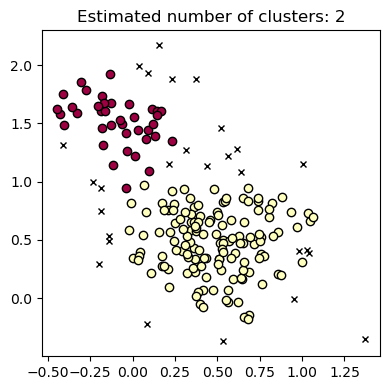

In [ ]:
from sklearn.cluster import HDBSCAN
from sklearn.manifold import TSNE

rng = np.random.default_rng()

noise = 0.3

x1 = rng.normal(0,    noise,  50)
y1 = rng.normal(1.5,  noise,  50)
z1 = rng.normal(-2,   noise,  50)
w1 = rng.normal(0.5,  noise,  50)

x2 = rng.normal(0.5,  noise,  50)
y2 = rng.normal(0.5,  noise,  50)
z2 = rng.normal(0.5,  noise,  50)
w2 = rng.normal(0.5,  noise,  50)

x3 = rng.normal(0.5,  noise,  50)
y3 = rng.normal(0.5,  noise,  50)
z3 = rng.normal(1.5,  noise,  50)
w3 = rng.normal(1.5,  noise,  50)

x4 = rng.normal(0.5,  noise,  50)
y4 = rng.normal(0.5,  noise,  50)
z4 = rng.normal(-1.5,  noise,  50)
w4 = rng.normal(-1.5,  noise,  50)

x = np.concatenate((x1, x2, x3, x4))
y = np.concatenate((y1, y2, y3, y4))
z = np.concatenate((z1, z2, z3, z4))
w = np.concatenate((w1, w2, w3, w4))

X2 = np.stack((x,y), axis=1)
X4 = np.stack((x,y,z,w), axis=1)

hdb2d = HDBSCAN()
hdb2d.fit(X2)

plot_clusters(X2, hdb2d.labels_)

<Axes: title={'center': 'Estimated number of clusters: 4'}>

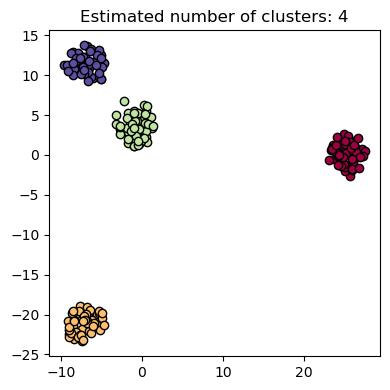

In [ ]:
X4_embedded = TSNE(n_components=2, learning_rate='auto',
                    init='random', perplexity=30).fit_transform(X4)

hdb4d = HDBSCAN()
hdb4d.fit(X4_embedded)

plot_clusters(X4_embedded, hdb4d.labels_)

# Inferring circuits from traces